# 05 - Transaction Graph Construction

Ce notebook construit la représentation transactionnelle du dataset PaySim destinée aux futurs modèles de Graph Machine Learning et de Dynamic Graph Learning.

L'objectif est de représenter chaque compte comme un nœud et chaque transaction comme une interaction dirigée et temporelle, tout en préservant strictement la causalité et le découpage temporel Train / Validation / Test.

Une attention particulière sera portée au risque de **temporal topology leakage** : pour une transaction observée au temps \(t\), aucune information structurelle provenant d'une transaction future ne devra être accessible au modèle.

Le notebook ne réalise pas encore l'entraînement d'un GNN. Il prépare une représentation graph propre, compacte, causale et réutilisable pour les expérimentations statiques et dynamiques.

## 1. Setup and Data Loading

Cette première section initialise l'environnement, vérifie les artefacts produits par le Feature Engineering et contrôle l'intégrité du dataset Graph-ready.

Le schéma du fichier Parquet est inspecté avant le chargement afin de limiter les allocations mémoire. Les listes officielles de features Graph Core, Graph Full et PaySim-sensitive sont récupérées directement depuis les métadonnées du notebook précédent.

Aucune structure de graphe n'est construite à ce stade.

In [1]:
from pathlib import Path
import gc
import json
import platform
import re
import sys
import importlib.util
import importlib.metadata

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# Reproductibilité
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Chemins
PROCESSED_DIR = Path("../data/processed")

GRAPH_READY_PATH = PROCESSED_DIR / "paysim_graph_ready.parquet"
METADATA_PATH = PROCESSED_DIR / "feature_engineering_metadata.json"

print("Python :", sys.version.split()[0])
print("Plateforme :", platform.platform())
print("RANDOM_STATE :", RANDOM_STATE)

print("\nGraph-ready :", GRAPH_READY_PATH)
print("Existe :", GRAPH_READY_PATH.exists())

print("\nMetadata :", METADATA_PATH)
print("Existe :", METADATA_PATH.exists())

assert GRAPH_READY_PATH.exists(), f"Fichier introuvable : {GRAPH_READY_PATH}"
assert METADATA_PATH.exists(), f"Fichier introuvable : {METADATA_PATH}"

Python : 3.13.7
Plateforme : Windows-11-10.0.22631-SP0
RANDOM_STATE : 42

Graph-ready : ..\data\processed\paysim_graph_ready.parquet
Existe : True

Metadata : ..\data\processed\feature_engineering_metadata.json
Existe : True


In [2]:
def check_package(import_name, distribution_name=None):
    distribution_name = distribution_name or import_name
    available = importlib.util.find_spec(import_name) is not None

    version = None
    if available:
        try:
            version = importlib.metadata.version(distribution_name)
        except importlib.metadata.PackageNotFoundError:
            version = "version inconnue"

    return {
        "available": available,
        "version": version
    }


packages = {
    "pandas": ("pandas", "pandas"),
    "numpy": ("numpy", "numpy"),
    "scipy": ("scipy", "scipy"),
    "torch": ("torch", "torch"),
    "torch_geometric": ("torch_geometric", "torch-geometric"),
    "dgl": ("dgl", "dgl"),
}

environment = {}

for name, (import_name, distribution_name) in packages.items():
    environment[name] = check_package(import_name, distribution_name)

environment_df = pd.DataFrame(environment).T
environment_df

,available,version
pandas,True,3.0.3
numpy,True,2.2.6
scipy,True,1.17.1
torch,True,2.12.0
torch_geometric,True,2.7.0
dgl,False,None


In [3]:
# Charger les métadonnées
with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata = json.load(f)

print("Type :", type(metadata).__name__)
print("Nombre de clés principales :", len(metadata))

print("\nClés principales :")
for key in metadata.keys():
    print("-", key)

Type : dict
Nombre de clés principales : 12

Clés principales :
- project
- dataset
- notebook
- dataset_summary
- target
- split
- feature_sets
- export_schemas
- temporal_rules
- missing_value_semantics
- excluded_predictors
- notes


In [4]:
def collect_string_lists(obj, path=""):
    results = []

    if isinstance(obj, dict):
        for key, value in obj.items():
            child_path = f"{path}.{key}" if path else key
            results.extend(collect_string_lists(value, child_path))

    elif isinstance(obj, list):
        if all(isinstance(x, str) for x in obj):
            results.append((path, obj))

    return results


metadata_lists = collect_string_lists(metadata)

print("Listes de chaînes détectées dans le JSON :", len(metadata_lists))

for path, values in metadata_lists:
    print(f"- {path}: {len(values)} éléments")

Listes de chaînes détectées dans le JSON : 16
- feature_sets.core_ml: 22 éléments
- feature_sets.full_ml: 31 éléments
- feature_sets.linear_core: 20 éléments
- feature_sets.linear_full: 27 éléments
- feature_sets.paysim_sensitive: 11 éléments
- feature_sets.model_paysim_sensitive: 9 éléments
- feature_sets.graph_core: 15 éléments
- feature_sets.graph_full: 24 éléments
- feature_sets.graph_core_edge: 9 éléments
- feature_sets.graph_node_history: 6 éléments
- feature_sets.graph_sensitive: 9 éléments
- feature_sets.categorical: 1 éléments
- feature_sets.redundant_analysis_only: 6 éléments
- export_schemas.machine_learning.columns: 34 éléments
- export_schemas.graph_ready.columns: 29 éléments
- excluded_predictors: 4 éléments


In [5]:
def normalize_text(text):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")


def find_feature_list(metadata_lists, aliases, required_terms):
    aliases = {normalize_text(alias) for alias in aliases}
    candidates = []

    for path, values in metadata_lists:
        normalized_path = normalize_text(path)
        leaf = normalize_text(path.split(".")[-1])

        exact_alias = leaf in aliases
        terms_match = all(term in normalized_path for term in required_terms)

        if exact_alias or terms_match:
            candidates.append({
                "path": path,
                "values": values,
                "exact_alias": exact_alias
            })

    if not candidates:
        return None, None, []

    candidates.sort(
        key=lambda x: (
            not x["exact_alias"],
            x["path"].count("."),
            len(x["path"])
        )
    )

    selected = candidates[0]

    return selected["path"], selected["values"], candidates


core_path, graph_core_features, core_candidates = find_feature_list(
    metadata_lists,
    aliases=[
        "graph_core",
        "graph_core_features",
        "graph_core_feature_list"
    ],
    required_terms=["graph", "core"]
)

full_path, graph_full_features, full_candidates = find_feature_list(
    metadata_lists,
    aliases=[
        "graph_full",
        "graph_full_features",
        "graph_full_feature_list"
    ],
    required_terms=["graph", "full"]
)

sensitive_path, graph_sensitive_features, sensitive_candidates = find_feature_list(
    metadata_lists,
    aliases=[
        "graph_sensitive",
        "graph_sensitive_features",
        "paysim_sensitive",
        "paysim_sensitive_features"
    ],
    required_terms=["sensitive"]
)

print("Graph Core :", core_path)
print("Graph Full :", full_path)
print("Graph Sensitive :", sensitive_path)

if graph_core_features is None:
    raise KeyError("Impossible de retrouver automatiquement Graph Core dans le JSON.")

if graph_full_features is None:
    raise KeyError("Impossible de retrouver automatiquement Graph Full dans le JSON.")

if graph_sensitive_features is None:
    graph_sensitive_features = []
    print("\nAucune liste Graph Sensitive identifiée automatiquement.")

Graph Core : feature_sets.graph_core
Graph Full : feature_sets.graph_full
Graph Sensitive : feature_sets.graph_sensitive


In [6]:
print("Graph Core features :", len(graph_core_features))
print(graph_core_features)

print("\nGraph Full features :", len(graph_full_features))
print(graph_full_features)

print("\nGraph Sensitive features :", len(graph_sensitive_features))
print(graph_sensitive_features)

Graph Core features : 15
['amount', 'log_amount', 'type', 'origin_balance_change', 'destination_balance_change', 'origin_zero_before', 'origin_zero_after', 'destination_zero_before', 'destination_zero_after', 'orig_prev_transactions', 'dest_prev_transactions', 'orig_prev_volume', 'dest_prev_volume', 'orig_time_since_last', 'dest_time_since_last']

Graph Full features : 24
['amount', 'log_amount', 'type', 'origin_balance_change', 'destination_balance_change', 'origin_zero_before', 'origin_zero_after', 'destination_zero_before', 'destination_zero_after', 'orig_prev_transactions', 'dest_prev_transactions', 'orig_prev_volume', 'dest_prev_volume', 'orig_time_since_last', 'dest_time_since_last', 'amount_to_oldbalance_ratio', 'origin_balance_residual', 'destination_balance_residual', 'origin_emptied', 'amount_equals_oldbalance', 'cycle_sin', 'cycle_cos', 'simulated_day', 'dest_active_last_24']

Graph Sensitive features : 9
['amount_to_oldbalance_ratio', 'origin_balance_residual', 'destination

In [7]:
# Inspecter le fichier sans charger les données
parquet_file = pq.ParquetFile(GRAPH_READY_PATH)

parquet_columns = parquet_file.schema_arrow.names
n_rows_parquet = parquet_file.metadata.num_rows
n_columns_parquet = len(parquet_columns)

print("Dimensions du Parquet :", (n_rows_parquet, n_columns_parquet))

print("\nColonnes du Parquet :")
for column in parquet_columns:
    print("-", column)

Dimensions du Parquet : (6362620, 29)

Colonnes du Parquet :
- nameOrig
- nameDest
- step
- split
- amount
- log_amount
- type
- origin_balance_change
- destination_balance_change
- origin_zero_before
- origin_zero_after
- destination_zero_before
- destination_zero_after
- orig_prev_transactions
- dest_prev_transactions
- orig_prev_volume
- dest_prev_volume
- orig_time_since_last
- dest_time_since_last
- amount_to_oldbalance_ratio
- origin_balance_residual
- destination_balance_residual
- origin_emptied
- amount_equals_oldbalance
- cycle_sin
- cycle_cos
- simulated_day
- dest_active_last_24
- isFraud


In [8]:
essential_columns = [
    "nameOrig",
    "nameDest",
    "step",
    "split",
    "isFraud",
    "type"
]

missing_essential = [
    column
    for column in essential_columns
    if column not in parquet_columns
]

print("Colonnes essentielles manquantes :", missing_essential)

assert not missing_essential, (
    f"Colonnes essentielles absentes : {missing_essential}"
)

Colonnes essentielles manquantes : []


In [9]:
requested_columns = (
    essential_columns
    + graph_core_features
    + graph_full_features
    + graph_sensitive_features
)

# Supprimer les doublons sans modifier l'ordre
requested_columns = list(dict.fromkeys(requested_columns))

missing_requested = [
    column
    for column in requested_columns
    if column not in parquet_columns
]

columns_to_load = [
    column
    for column in parquet_columns
    if column in requested_columns
]

print("Colonnes demandées :", len(requested_columns))
print("Colonnes disponibles à charger :", len(columns_to_load))
print("Colonnes demandées absentes :", missing_requested)

Colonnes demandées : 29
Colonnes disponibles à charger : 29
Colonnes demandées absentes : []


In [10]:
# Charger uniquement les colonnes utiles
df_graph = pd.read_parquet(
    GRAPH_READY_PATH,
    columns=columns_to_load,
    engine="pyarrow"
)

gc.collect()

print("Dimensions chargées :", df_graph.shape)

memory_mb = df_graph.memory_usage(deep=True).sum() / 1024**2
memory_gb = memory_mb / 1024

print(f"Mémoire du DataFrame : {memory_mb:,.2f} MB")
print(f"Mémoire du DataFrame : {memory_gb:,.2f} GB")

Dimensions chargées : (6362620, 29)
Mémoire du DataFrame : 673.32 MB
Mémoire du DataFrame : 0.66 GB


In [11]:
print("Dtypes des colonnes essentielles :")

for column in essential_columns:
    print(f"{column:12s} -> {df_graph[column].dtype}")

print("\nRépartition globale des dtypes chargés :")
print(df_graph.dtypes.astype(str).value_counts())

Dtypes des colonnes essentielles :
nameOrig     -> string
nameDest     -> string
step         -> int16
split        -> category
isFraud      -> int8
type         -> category

Répartition globale des dtypes chargés :
float32     12
int8         8
int16        4
string       2
category     2
float64      1
Name: count, dtype: int64


In [12]:
fraud_distribution = (
    df_graph["isFraud"]
    .value_counts(dropna=False)
    .sort_index()
    .rename("count")
    .to_frame()
)

fraud_distribution["percentage"] = (
    fraud_distribution["count"] / len(df_graph) * 100
)

fraud_distribution

,count,percentage
isFraud,,
0,6354407,99.870918
1,8213,0.129082


In [13]:
split_summary = (
    df_graph
    .groupby("split", observed=True)
    .agg(
        transactions=("isFraud", "size"),
        frauds=("isFraud", "sum"),
        step_min=("step", "min"),
        step_max=("step", "max")
    )
)

split_summary["fraud_rate_pct"] = (
    split_summary["frauds"]
    / split_summary["transactions"]
    * 100
)

split_summary = split_summary.sort_values("step_min")

split_summary

,transactions,frauds,step_min,step_max,fraud_rate_pct
split,,,,,
Train,4771387,3745,1,334,0.078489
Validation,792406,638,335,392,0.080514
Test,798827,3830,393,743,0.479453


In [14]:
def find_duplicates(values):
    duplicated = (
        pd.Series(values, dtype="object")
        .value_counts()
    )

    return duplicated[duplicated > 1].index.tolist()


core_duplicates = find_duplicates(graph_core_features)
full_duplicates = find_duplicates(graph_full_features)
sensitive_duplicates = find_duplicates(graph_sensitive_features)

core_set = set(graph_core_features)
full_set = set(graph_full_features)

core_in_full = core_set.issubset(full_set)

full_minus_core = [
    feature
    for feature in graph_full_features
    if feature not in core_set
]

print("Graph Core :", len(graph_core_features))
print("Graph Full :", len(graph_full_features))

print("\nDoublons Graph Core :", core_duplicates)
print("Doublons Graph Full :", full_duplicates)
print("Doublons Graph Sensitive :", sensitive_duplicates)

print("\nGraph Core inclus dans Graph Full :", core_in_full)

print("\nGraph Full - Graph Core :", len(full_minus_core))
print(full_minus_core)

Graph Core : 15
Graph Full : 24

Doublons Graph Core : []
Doublons Graph Full : []
Doublons Graph Sensitive : []

Graph Core inclus dans Graph Full : True

Graph Full - Graph Core : 9
['amount_to_oldbalance_ratio', 'origin_balance_residual', 'destination_balance_residual', 'origin_emptied', 'amount_equals_oldbalance', 'cycle_sin', 'cycle_cos', 'simulated_day', 'dest_active_last_24']


In [15]:
core_missing = [
    feature
    for feature in graph_core_features
    if feature not in parquet_columns
]

full_missing = [
    feature
    for feature in graph_full_features
    if feature not in parquet_columns
]

sensitive_missing = [
    feature
    for feature in graph_sensitive_features
    if feature not in parquet_columns
]

print("Graph Core manquantes :", core_missing)
print("Graph Full manquantes :", full_missing)
print("Graph Sensitive manquantes :", sensitive_missing)

Graph Core manquantes : []
Graph Full manquantes : []
Graph Sensitive manquantes : []


In [16]:
forbidden_predictive_features = {
    "isFraud",
    "isFlaggedFraud",
    "split",
    "nameOrig",
    "nameDest"
}

core_forbidden = sorted(
    core_set.intersection(forbidden_predictive_features)
)

full_forbidden = sorted(
    full_set.intersection(forbidden_predictive_features)
)

print("Features interdites dans Graph Core :", core_forbidden)
print("Features interdites dans Graph Full :", full_forbidden)

print("\nstep dans Graph Core :", "step" in core_set)
print("step dans Graph Full :", "step" in full_set)

Features interdites dans Graph Core : []
Features interdites dans Graph Full : []

step dans Graph Core : False
step dans Graph Full : False


In [17]:
assert len(graph_core_features) == 15, (
    f"Graph Core devrait contenir 15 features, "
    f"mais {len(graph_core_features)} ont été trouvées."
)

assert len(graph_full_features) == 24, (
    f"Graph Full devrait contenir 24 features, "
    f"mais {len(graph_full_features)} ont été trouvées."
)

assert not core_duplicates, (
    f"Doublons dans Graph Core : {core_duplicates}"
)

assert not full_duplicates, (
    f"Doublons dans Graph Full : {full_duplicates}"
)

assert core_in_full, (
    "Graph Core n'est pas inclus dans Graph Full."
)

assert not core_missing, (
    f"Features Graph Core absentes du Parquet : {core_missing}"
)

assert not full_missing, (
    f"Features Graph Full absentes du Parquet : {full_missing}"
)

assert not core_forbidden, (
    f"Features interdites dans Graph Core : {core_forbidden}"
)

assert not full_forbidden, (
    f"Features interdites dans Graph Full : {full_forbidden}"
)

print("Audit structurel Graph Core / Graph Full : OK")

Audit structurel Graph Core / Graph Full : OK


In [18]:
print("===== DATASET =====")
print("Parquet complet :", (n_rows_parquet, n_columns_parquet))
print("DataFrame chargé :", df_graph.shape)
print(f"Mémoire chargée : {memory_gb:.2f} GB")

print("\n===== FEATURES =====")
print("Graph Core :", len(graph_core_features))
print("Graph Full :", len(graph_full_features))
print("Graph Sensitive :", len(graph_sensitive_features))
print("Full - Core :", len(full_minus_core))

print("\n===== AUDIT =====")
print("Core manquantes :", core_missing)
print("Full manquantes :", full_missing)
print("Sensitive manquantes :", sensitive_missing)
print("Core doublons :", core_duplicates)
print("Full doublons :", full_duplicates)
print("Core ⊂ Full :", core_in_full)
print("Interdites Core :", core_forbidden)
print("Interdites Full :", full_forbidden)

print("\n===== SPLITS =====")
print(split_summary)

print("\n===== ENVIRONNEMENT GRAPH =====")
print(environment_df)

===== DATASET =====
Parquet complet : (6362620, 29)
DataFrame chargé : (6362620, 29)
Mémoire chargée : 0.66 GB

===== FEATURES =====
Graph Core : 15
Graph Full : 24
Graph Sensitive : 9
Full - Core : 9

===== AUDIT =====
Core manquantes : []
Full manquantes : []
Sensitive manquantes : []
Core doublons : []
Full doublons : []
Core ⊂ Full : True
Interdites Core : []
Interdites Full : []

===== SPLITS =====
            transactions  frauds  step_min  step_max  fraud_rate_pct
split                                                               
Train            4771387    3745         1       334        0.078489
Validation        792406     638       335       392        0.080514
Test              798827    3830       393       743        0.479453

===== ENVIRONNEMENT GRAPH =====
                available version
pandas               True   3.0.3
numpy                True   2.2.6
scipy                True  1.17.1
torch                True  2.12.0
torch_geometric      True   2.7.0
dgl        

### Section 1 - Key Findings

Le dataset Graph-ready et les métadonnées du Feature Engineering ont été chargés et validés avec succès.

Le fichier contient **6 362 620 transactions et 29 colonnes**, pour une empreinte mémoire d'environ **673 MB**. Les colonnes structurantes du futur graphe sont disponibles avec des types adaptés : les identifiants `nameOrig` et `nameDest` restent des chaînes de caractères, `step` est stocké en `int16`, `split` et `type` en variables catégorielles et la cible `isFraud` en `int8`.

Les listes officielles de features ont été récupérées directement depuis les métadonnées. **Graph Core contient 15 features et Graph Full 24 features**. Les neuf variables supplémentaires de Graph Full correspondent exactement aux neuf features identifiées comme Graph PaySim-sensitive. Cette séparation permettra de conserver un protocole expérimental Core / Full cohérent avec celui utilisé pour les baselines tabulaires.

Aucune feature Graph Core ou Graph Full n'est manquante, dupliquée ou interdite. Les identifiants bruts, la cible et le split ne sont pas utilisés comme prédicteurs. La variable `step` est également séparée des feature sets afin de conserver explicitement son rôle temporel.

Le split temporel officiel est parfaitement préservé : Train couvre les steps 1 à 334, Validation les steps 335 à 392 et Test les steps 393 à 743. Le Test présente un taux de fraude nettement supérieur à celui de Validation, confirmant le drift temporel déjà observé lors des baselines Machine Learning.

L'environnement dispose de PyTorch et PyTorch Geometric, tandis que DGL n'est pas installé. Aucun choix de framework n'est néanmoins effectué à ce stade : la construction du graphe restera autant que possible indépendante d'une librairie spécifique.

Ces contrôles confirment que les artefacts du Feature Engineering constituent une base cohérente pour commencer l'analyse structurelle et temporelle du réseau transactionnel.

## 2. Graph-ready Dataset Integrity and Temporal Safety

Avant de construire la topologie transactionnelle, il est nécessaire de vérifier que les données structurelles et temporelles respectent strictement le protocole expérimental.

Cette étape contrôle notamment l'intégrité des identifiants de comptes, la validité de la cible et des splits, l'ordre chronologique du dataset ainsi que la cohérence entre les fenêtres Train, Validation et Test.

La causalité constitue une contrainte centrale : pour une transaction observée au step \(t\), le futur contexte graph devra être construit uniquement à partir des transactions de steps strictement inférieurs à \(t\). Les transactions appartenant au même step ne seront donc pas utilisées comme historique les unes des autres.

Les valeurs manquantes des features historiques sont également auditées afin de distinguer les valeurs réellement problématiques des absences d'historique ayant une signification causale.

In [19]:
# Inspecter les règles temporelles
print("===== SPLIT METADATA =====")
print(json.dumps(metadata.get("split", {}), indent=2, ensure_ascii=False))

print("\n===== TEMPORAL RULES =====")
print(json.dumps(metadata.get("temporal_rules", {}), indent=2, ensure_ascii=False))

print("\n===== MISSING VALUE SEMANTICS =====")
print(json.dumps(
    metadata.get("missing_value_semantics", {}),
    indent=2,
    ensure_ascii=False
))

===== SPLIT METADATA =====
{
  "Train": {
    "step_start": 1,
    "step_end": 334,
    "transactions": 4771387,
    "frauds": 3745
  },
  "Validation": {
    "step_start": 335,
    "step_end": 392,
    "transactions": 792406,
    "frauds": 638
  },
  "Test": {
    "step_start": 393,
    "step_end": 743,
    "transactions": 798827,
    "frauds": 3830
  }
}

===== TEMPORAL RULES =====
{
  "historical_features": "Only transactions with step < t",
  "same_step_transactions": "Never treated as historical",
  "chronological_split": true
}

===== MISSING VALUE SEMANTICS =====
{
  "orig_prev_mean_amount": "No previous origin transaction",
  "orig_time_since_last": "No previous origin transaction",
  "dest_prev_mean_amount": "No previous destination transaction",
  "dest_time_since_last": "No previous destination transaction",
  "amount_to_oldbalance_ratio": "oldbalanceOrg == 0",
  "amount_to_dest_balance_ratio": "oldbalanceDest == 0"
}


In [20]:
# Vérifier les valeurs manquantes essentielles
essential_nulls = {
    column: int(df_graph[column].isna().sum())
    for column in essential_columns
}

print("Valeurs manquantes essentielles :")
for column, count in essential_nulls.items():
    print(f"{column:12s} : {count:,}")

# Vérifier les identifiants vides
empty_orig = int(df_graph["nameOrig"].eq("").sum())
empty_dest = int(df_graph["nameDest"].eq("").sum())

print("\nIdentifiants vides :")
print("nameOrig :", f"{empty_orig:,}")
print("nameDest :", f"{empty_dest:,}")

# Valeurs de la cible
fraud_values = sorted(df_graph["isFraud"].unique().tolist())

print("\nValeurs isFraud :", fraud_values)

# Valeurs des splits
split_values = df_graph["split"].unique().tolist()

print("Valeurs split :", split_values)

# Types de transactions
if isinstance(df_graph["type"].dtype, pd.CategoricalDtype):
    transaction_types = df_graph["type"].cat.categories.tolist()
else:
    transaction_types = sorted(df_graph["type"].dropna().unique().tolist())

print("Types de transactions :", transaction_types)

Valeurs manquantes essentielles :
nameOrig     : 0
nameDest     : 0
step         : 0
split        : 0
isFraud      : 0
type         : 0

Identifiants vides :
nameOrig : 0
nameDest : 0

Valeurs isFraud : [0, 1]
Valeurs split : ['Train', 'Validation', 'Test']
Types de transactions : ['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER']


In [21]:
# Vérifier les colonnes structurelles
assert all(value == 0 for value in essential_nulls.values()), (
    f"Valeurs manquantes dans les colonnes essentielles : {essential_nulls}"
)

assert empty_orig == 0, (
    f"{empty_orig} identifiants source sont vides."
)

assert empty_dest == 0, (
    f"{empty_dest} identifiants destination sont vides."
)

assert set(fraud_values) == {0, 1}, (
    f"Valeurs inattendues dans isFraud : {fraud_values}"
)

assert set(split_values) == {"Train", "Validation", "Test"}, (
    f"Splits inattendus : {split_values}"
)

print("Intégrité des colonnes structurelles : OK")

Intégrité des colonnes structurelles : OK


In [22]:
# Vérifier l'ordre temporel
steps = df_graph["step"].to_numpy(copy=False)

temporal_order_ok = bool(
    np.all(steps[1:] >= steps[:-1])
)

step_min_global = int(steps.min())
step_max_global = int(steps.max())

print("Ordre temporel conservé :", temporal_order_ok)
print("Step minimum :", step_min_global)
print("Step maximum :", step_max_global)

assert temporal_order_ok, (
    "Le dataset Graph-ready n'est pas ordonné chronologiquement."
)

assert step_min_global == 1
assert step_max_global == 743

print("Ordre temporel global : OK")

Ordre temporel conservé : True
Step minimum : 1
Step maximum : 743
Ordre temporel global : OK


In [23]:
# Vérifier les fenêtres temporelles
train_mask = df_graph["split"].eq("Train")
val_mask = df_graph["split"].eq("Validation")
test_mask = df_graph["split"].eq("Test")

train_step_ok = (
    df_graph.loc[train_mask, "step"]
    .between(1, 334)
    .all()
)

val_step_ok = (
    df_graph.loc[val_mask, "step"]
    .between(335, 392)
    .all()
)

test_step_ok = (
    df_graph.loc[test_mask, "step"]
    .between(393, 743)
    .all()
)

print("Steps Train valides :", bool(train_step_ok))
print("Steps Validation valides :", bool(val_step_ok))
print("Steps Test valides :", bool(test_step_ok))

# Vérifier aussi l'inverse
expected_train = df_graph["step"].between(1, 334)
expected_val = df_graph["step"].between(335, 392)
expected_test = df_graph["step"].between(393, 743)

train_assignment_ok = bool(
    np.array_equal(
        train_mask.to_numpy(),
        expected_train.to_numpy()
    )
)

val_assignment_ok = bool(
    np.array_equal(
        val_mask.to_numpy(),
        expected_val.to_numpy()
    )
)

test_assignment_ok = bool(
    np.array_equal(
        test_mask.to_numpy(),
        expected_test.to_numpy()
    )
)

print("\nAffectation Train exacte :", train_assignment_ok)
print("Affectation Validation exacte :", val_assignment_ok)
print("Affectation Test exacte :", test_assignment_ok)

Steps Train valides : True
Steps Validation valides : True
Steps Test valides : True

Affectation Train exacte : True
Affectation Validation exacte : True
Affectation Test exacte : True


In [24]:
# Valider le split temporel
assert train_step_ok
assert val_step_ok
assert test_step_ok

assert train_assignment_ok
assert val_assignment_ok
assert test_assignment_ok

print("Cohérence step / split : OK")

Cohérence step / split : OK


In [25]:
# Vérifier les frontières temporelles
boundary_steps = [334, 335, 392, 393]

boundary_summary = (
    df_graph[df_graph["step"].isin(boundary_steps)]
    .groupby(["step", "split"], observed=True)
    .agg(
        transactions=("isFraud", "size"),
        frauds=("isFraud", "sum")
    )
    .reset_index()
)

boundary_summary

,step,split,transactions,frauds
0,334,Train,12016,4
1,335,Validation,10456,4
2,392,Validation,10,10
3,393,Test,19269,4


In [26]:
# Compter les valeurs manquantes colonne par colonne
missing_graph_records = []

for feature in graph_full_features:
    missing_count = int(df_graph[feature].isna().sum())

    missing_graph_records.append({
        "feature": feature,
        "missing_count": missing_count,
        "missing_pct": missing_count / len(df_graph) * 100
    })

missing_graph_df = pd.DataFrame(missing_graph_records)

missing_graph_df = (
    missing_graph_df
    .sort_values(
        ["missing_count", "feature"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

missing_graph_df

,feature,missing_count,missing_pct
0,orig_time_since_last,6353354,99.854368
1,dest_time_since_last,2769903,43.534000
2,amount_to_oldbalance_ratio,2102449,33.043762
3,amount,0,0.000000
4,amount_equals_oldbalance,0,0.000000
5,cycle_cos,0,0.000000
6,cycle_sin,0,0.000000
7,dest_active_last_24,0,0.000000
8,dest_prev_transactions,0,0.000000
9,dest_prev_volume,0,0.000000


In [27]:
features_with_missing = missing_graph_df[
    missing_graph_df["missing_count"] > 0
].copy()

print(
    "Features Graph Full avec valeurs manquantes :",
    len(features_with_missing)
)

features_with_missing

Features Graph Full avec valeurs manquantes : 3


,feature,missing_count,missing_pct
0,orig_time_since_last,6353354,99.854368
1,dest_time_since_last,2769903,43.534000
2,amount_to_oldbalance_ratio,2102449,33.043762


In [28]:
# Identifier les self-transactions
self_transaction_mask = df_graph["nameOrig"].eq(
    df_graph["nameDest"]
)

n_self_transactions = int(self_transaction_mask.sum())

self_transaction_pct = (
    n_self_transactions / len(df_graph) * 100
)

n_self_frauds = int(
    df_graph.loc[self_transaction_mask, "isFraud"].sum()
)

print("Self-transactions :", f"{n_self_transactions:,}")
print(f"Proportion : {self_transaction_pct:.6f} %")
print("Fraudes parmi elles :", f"{n_self_frauds:,}")

Self-transactions : 0
Proportion : 0.000000 %
Fraudes parmi elles : 0


In [29]:
# Libérer les objets temporaires
del train_mask
del val_mask
del test_mask

del expected_train
del expected_val
del expected_test

del self_transaction_mask

gc.collect()

print("Objets temporaires supprimés.")

Objets temporaires supprimés.


### Temporal Graph Safety Principle

La construction du graphe suivra une logique strictement causale.

Pour une transaction observée au step \(t\), le contexte structurel autorisé est :

\[
G_{<t}
\]

c'est-à-dire le graphe constitué exclusivement des transactions observées aux steps strictement inférieurs à \(t\).

Les transactions appartenant au step \(t\) constituent le batch d'événements à prédire et ne peuvent pas fournir de voisinage, de degré, d'agrégation ou de message aux autres transactions du même step.

Après la prédiction du step \(t\), sa topologie pourra être ajoutée à l'historique disponible pour le step suivant. Cette mise à jour de la topologie ne signifie pas que les labels du step précédent deviennent automatiquement disponibles pour réentraîner le modèle.

Cette distinction entre **observation de la topologie**, **observation du label** et **mise à jour du modèle** sera conservée dans le futur protocole rolling / online.

In [30]:
print("===== STRUCTURE =====")
print("Lignes :", f"{len(df_graph):,}")
print("Colonnes :", df_graph.shape[1])
print("Null essentiels :", essential_nulls)
print("nameOrig vides :", empty_orig)
print("nameDest vides :", empty_dest)
print("Valeurs isFraud :", fraud_values)
print("Splits :", split_values)
print("Types :", transaction_types)

print("\n===== TEMPORALITÉ =====")
print("Ordre temporel :", temporal_order_ok)
print("Steps :", step_min_global, "->", step_max_global)
print("Train exact :", train_assignment_ok)
print("Validation exact :", val_assignment_ok)
print("Test exact :", test_assignment_ok)

print("\n===== MISSING VALUES =====")
print("Features Graph avec NaN :", len(features_with_missing))

if len(features_with_missing) > 0:
    print(
        features_with_missing[
            ["feature", "missing_count", "missing_pct"]
        ].to_string(index=False)
    )

print("\n===== SELF-TRANSACTIONS =====")
print("Nombre :", f"{n_self_transactions:,}")
print(f"Proportion : {self_transaction_pct:.6f} %")
print("Fraudes :", f"{n_self_frauds:,}")

print("\nAudit d'intégrité et de sécurité temporelle terminé.")

===== STRUCTURE =====
Lignes : 6,362,620
Colonnes : 29
Null essentiels : {'nameOrig': 0, 'nameDest': 0, 'step': 0, 'split': 0, 'isFraud': 0, 'type': 0}
nameOrig vides : 0
nameDest vides : 0
Valeurs isFraud : [0, 1]
Splits : ['Train', 'Validation', 'Test']
Types : ['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER']

===== TEMPORALITÉ =====
Ordre temporel : True
Steps : 1 -> 743
Train exact : True
Validation exact : True
Test exact : True

===== MISSING VALUES =====
Features Graph avec NaN : 3
                   feature  missing_count  missing_pct
      orig_time_since_last        6353354    99.854368
      dest_time_since_last        2769903    43.534000
amount_to_oldbalance_ratio        2102449    33.043762

===== SELF-TRANSACTIONS =====
Nombre : 0
Proportion : 0.000000 %
Fraudes : 0

Audit d'intégrité et de sécurité temporelle terminé.


### Section 2 - Key Findings

L'audit d'intégrité confirme que les données Graph-ready sont compatibles avec une construction transactionnelle stricte. Aucune valeur manquante ou vide n'est présente dans les identifiants source et destination, les variables temporelles, le split, le type de transaction ou la cible.

L'ordre chronologique est entièrement conservé sur les 743 steps. L'affectation des transactions aux périodes Train, Validation et Test correspond exactement aux fenêtres définies lors du Feature Engineering : Train couvre les steps 1 à 334, Validation les steps 335 à 392 et Test les steps 393 à 743. Aucun chevauchement ou mélange temporel n'est observé.

Les métadonnées confirment également la règle causale du projet : pour une transaction au step \(t\), seules les transactions appartenant aux steps strictement inférieurs à \(t\) peuvent constituer son historique. Les événements du même step ne sont jamais considérés comme historiques entre eux.

Trois features Graph Full contiennent des valeurs manquantes, mais leur absence possède une signification explicite. `orig_time_since_last` est manquante pour environ 99,85 % des transactions lorsqu'aucune transaction source antérieure n'existe, tandis que `dest_time_since_last` est manquante pour environ 43,53 % des transactions sans historique destination. Cette forte asymétrie suggère que les comptes apparaissant comme destinations pourraient être nettement plus récurrents que les comptes sources. Cette hypothèse devra être vérifiée directement lors de l'analyse de l'univers des nœuds et des degrés. Les valeurs manquantes de `amount_to_oldbalance_ratio` correspondent quant à elles aux situations où le solde initial de la source est nul.

Aucune self-transaction `nameOrig == nameDest` n'est présente. Le graphe transactionnel naturel ne contient donc aucun self-loop issu directement des données.

Enfin, les volumes peuvent varier fortement entre les steps. Le step 392 ne contient que 10 transactions, toutes frauduleuses, alors que les steps voisins peuvent contenir plusieurs milliers d'événements. Cette hétérogénéité devra être prise en compte avant de choisir une stratégie de snapshots temporels.

L'ensemble de ces contrôles valide la base temporelle et structurelle nécessaire à la définition du protocole Graph Learning.

## 3. Graph Representation and Leakage Protocol

La représentation du graphe doit être définie avant toute construction technique afin d'éviter qu'une opération apparemment innocente introduise une fuite temporelle.

PaySim fournit naturellement un problème de classification au niveau transactionnel. Chaque compte constitue donc un nœud et chaque transaction une interaction dirigée entre un compte source et un compte destination.

La topologie accessible à une transaction dépend explicitement du temps. Pour prédire les transactions du step \(t\), seules les interactions appartenant aux steps strictement antérieurs sont autorisées dans le graphe de contexte.

Cette section formalise également la distinction entre le mapping administratif des identifiants, la visibilité de la topologie, la disponibilité des labels et la mise à jour online du graphe.

In [31]:
# Définir la représentation du graphe
graph_spec = {
    "node_entity": "PaySim account",
    "edge_entity": "individual transaction",
    "source_column": "nameOrig",
    "destination_column": "nameDest",
    "time_column": "step",
    "label_column": "isFraud",
    "directed": True,
    "multigraph": True,
    "self_loops_in_raw_data": False,
    "prediction_task": "edge classification",
    "canonical_temporal_form": "event-based",
    "static_views": "derived snapshots or cumulative historical graphs"
}

graph_spec

{'node_entity': 'PaySim account',
 'edge_entity': 'individual transaction',
 'source_column': 'nameOrig',
 'destination_column': 'nameDest',
 'time_column': 'step',
 'label_column': 'isFraud',
 'directed': True,
 'multigraph': True,
 'self_loops_in_raw_data': False,
 'prediction_task': 'edge classification',
 'canonical_temporal_form': 'event-based',
 'static_views': 'derived snapshots or cumulative historical graphs'}

### 3.1 Graph Semantics

La représentation canonique retenue est un **graphe transactionnel dirigé, temporel et multi-arêtes**.

- **Nœud** : un compte PaySim.
- **Arête** : une transaction individuelle.
- **Direction** : `nameOrig → nameDest`.
- **Timestamp** : `step`.
- **Label** : `isFraud`, porté par l'arête.
- **Tâche prédictive** : classification d'arêtes.

Plusieurs transactions entre les mêmes comptes restent des événements distincts. Elles ne sont pas agrégées dans la représentation canonique, car une agrégation préalable supprimerait leur ordre, leur fréquence et une partie de leur information temporelle.

La représentation event-based constitue donc la source principale. Des graphes statiques ou des snapshots pourront être dérivés ultérieurement selon les besoins des modèles.

In [32]:
# Définir le rôle des identifiants
id_mapping_policy = {
    "global_mapping_allowed": True,
    "role": "administrative indexing only",
    "uses_labels": False,
    "uses_graph_statistics": False,
    "uses_temporal_statistics": False,
    "raw_ids_as_predictive_features": False,
    "node_visibility_defined_by_first_seen": True
}

id_mapping_policy

{'global_mapping_allowed': True,
 'role': 'administrative indexing only',
 'uses_labels': False,
 'uses_graph_statistics': False,
 'uses_temporal_statistics': False,
 'raw_ids_as_predictive_features': False,
 'node_visibility_defined_by_first_seen': True}

### 3.2 Administrative Mapping vs Graph Visibility

Un mapping global et déterministe des identifiants bruts vers des entiers peut être utilisé comme opération administrative, à condition qu'il ne dépende d'aucun label, degré, voisinage, fréquence ou autre statistique du graphe.

L'identifiant numérique d'un nœud ne constitue jamais une feature prédictive.

Il faut distinguer :

\[
\text{node\_id exists}
\neq
\text{node is visible at time } t
\]

Un compte peut donc disposer d'un `node_id` dans le mapping global tout en restant inconnu du graphe historique tant que sa première transaction n'a pas été observée.

La visibilité temporelle d'un nœud sera déterminée par son `first_seen_step`, et non par son existence dans le mapping administratif.

In [33]:
# Formaliser la visibilité des informations
visibility_rules = pd.DataFrame([
    {
        "information": "Global raw-ID -> node_id mapping",
        "at_prediction_time_t": "Allowed",
        "role": "Administrative only"
    },
    {
        "information": "Edges with step < t",
        "at_prediction_time_t": "Allowed",
        "role": "Historical topology"
    },
    {
        "information": "Edge features with step < t",
        "at_prediction_time_t": "Allowed",
        "role": "Historical information"
    },
    {
        "information": "Query edge features at step t",
        "at_prediction_time_t": "Allowed",
        "role": "Current transaction features"
    },
    {
        "information": "Query edges at step t inside adjacency",
        "at_prediction_time_t": "Forbidden",
        "role": "Would create same-step topology leakage"
    },
    {
        "information": "Edges with step > t",
        "at_prediction_time_t": "Forbidden",
        "role": "Future topology leakage"
    },
    {
        "information": "Label of current query edge",
        "at_prediction_time_t": "Forbidden",
        "role": "Prediction target"
    },
    {
        "information": "Validation/Test labels in graph state",
        "at_prediction_time_t": "Forbidden",
        "role": "Supervised leakage"
    },
    {
        "information": "Degrees/neighbors computed with future edges",
        "at_prediction_time_t": "Forbidden",
        "role": "Structural leakage"
    }
])

visibility_rules

,information,at_prediction_time_t,role
0,Global raw-ID -> node_id mapping,Allowed,Administrative only
1,Edges with step < t,Allowed,Historical topology
2,Edge features with step < t,Allowed,Historical information
3,Query edge features at step t,Allowed,Current transaction features
4,Query edges at step t inside adjacency,Forbidden,Would create same-step topology leakage
5,Edges with step > t,Forbidden,Future topology leakage
6,Label of current query edge,Forbidden,Prediction target
7,Validation/Test labels in graph state,Forbidden,Supervised leakage
8,Degrees/neighbors computed with future edges,Forbidden,Structural leakage


In [34]:
# Règles causales
causal_protocol = {
    "history_for_step_t": "step < t",
    "query_batch": "step == t",
    "same_step_edges_in_context": False,
    "future_edges_in_context": False,
    "update_topology_after_prediction": True,
    "use_query_labels_for_topology_update": False,
    "automatic_online_retraining": False
}

causal_protocol

{'history_for_step_t': 'step < t',
 'query_batch': 'step == t',
 'same_step_edges_in_context': False,
 'future_edges_in_context': False,
 'update_topology_after_prediction': True,
 'use_query_labels_for_topology_update': False,
 'automatic_online_retraining': False}

In [35]:
# Définir le protocole rolling
rolling_protocol = pd.DataFrame([
    {
        "phase": "Before step t",
        "action": "Build/use G_<t",
        "labels_used": "No current/future labels"
    },
    {
        "phase": "Predict step t",
        "action": "Score all transactions from E_t",
        "labels_used": "No"
    },
    {
        "phase": "Evaluate step t",
        "action": "Compare predictions with labels",
        "labels_used": "Metrics only"
    },
    {
        "phase": "After step t",
        "action": "Add E_t topology to history",
        "labels_used": "No label injected into graph state"
    },
    {
        "phase": "Next step",
        "action": "Use updated G_<t+1",
        "labels_used": "No automatic supervised retraining"
    }
])

rolling_protocol

,phase,action,labels_used
0,Before step t,Build/use G_<t,No current/future labels
1,Predict step t,Score all transactions from E_t,No
2,Evaluate step t,Compare predictions with labels,Metrics only
3,After step t,Add E_t topology to history,No label injected into graph state
4,Next step,Use updated G_<t+1,No automatic supervised retraining


### 3.3 Train / Validation / Test Protocol

Le protocole principal conservera les mêmes rôles que pour les baselines tabulaires.

**Train**

Les paramètres du modèle sont appris exclusivement à partir des transactions Train. Pendant un traitement temporel du Train, une transaction au step \(t\) ne peut utiliser que \(G_{<t}\).

**Validation**

La Validation sert au choix de l'architecture, des hyperparamètres et du seuil de décision. Les paramètres supervisés du modèle restent fixes pendant l'évaluation rolling.

Pour prédire le step \(t\) de Validation, les événements des steps Validation antérieurs peuvent appartenir au graphe historique puisqu'ils ont déjà été observés. En revanche, leurs labels ne sont pas injectés automatiquement dans l'état du modèle ou du graphe.

**Test**

Le Test n'intervient dans aucune décision d'architecture, d'hyperparamètre ou de seuil. Le modèle final et le protocole sont figés avant son évaluation.

La topologie continue néanmoins d'évoluer de manière causale : lorsqu'un step Test a été prédit, ses transactions peuvent devenir des événements historiques pour les steps Test suivants, sans utilisation de leurs labels pour un réentraînement supervisé automatique.

In [36]:
# Récupérer les fenêtres officielles
split_windows = []

for split_name in ["Train", "Validation", "Test"]:
    split_info = metadata["split"][split_name]

    split_windows.append({
        "split": split_name,
        "step_start": split_info["step_start"],
        "step_end": split_info["step_end"],
        "transactions": split_info["transactions"],
        "frauds": split_info["frauds"]
    })

split_windows_df = pd.DataFrame(split_windows)

split_windows_df

,split,step_start,step_end,transactions,frauds
0,Train,1,334,4771387,3745
1,Validation,335,392,792406,638
2,Test,393,743,798827,3830


### 3.4 Inductive and Transductive Evaluation

Le caractère inductif ou transductif du problème ne sera pas supposé à l'avance.

Une transaction future pourra appartenir à l'une des situations suivantes :

1. source et destination déjà observées ;
2. source nouvelle et destination connue ;
3. source connue et destination nouvelle ;
4. source et destination nouvelles.

La proportion de chacune de ces situations sera mesurée explicitement dans les sections suivantes.

Si une proportion non négligeable des transactions Validation ou Test implique de nouveaux comptes, les futurs modèles devront être capables de fonctionner dans un cadre au moins partiellement inductif. Un modèle reposant uniquement sur une table d'embeddings apprise pour les nœuds Train serait alors insuffisant pour couvrir correctement le protocole expérimental.

In [37]:
# Comparer les deux familles temporelles
temporal_representation = pd.DataFrame([
    {
        "representation": "Event-based",
        "preserves_individual_transactions": True,
        "preserves_exact_step": True,
        "natural_for_online_updates": True,
        "canonical_storage": True
    },
    {
        "representation": "Snapshots",
        "preserves_individual_transactions": "Depends on construction",
        "preserves_exact_step": "Depends on window",
        "natural_for_online_updates": "Partial",
        "canonical_storage": False
    }
])

temporal_representation

,representation,preserves_individual_transactions,preserves_exact_step,natural_for_online_updates,canonical_storage
0,Event-based,True,True,True,True
1,Snapshots,Depends on construction,Depends on window,Partial,False


### 3.5 Canonical Temporal Representation

La représentation événementielle sera conservée comme format canonique de construction :

\[
(src,\ dst,\ step,\ edge\_features,\ label)
\]

Cette décision ne constitue pas encore un choix d'architecture.

Elle permet au contraire de préserver plusieurs possibilités :

- dériver un graphe cumulatif pour un premier GNN statique ;
- construire des snapshots par step ou fenêtre temporelle ;
- utiliser directement la séquence d'interactions pour un modèle temporel.

Les snapshots seront donc considérés comme des vues dérivées du flux transactionnel plutôt que comme la source primaire des données.

### 3.6 Static GNN Safety

L'utilisation d'un GNN dit « statique » ne supprime pas la contrainte temporelle.

Une adjacency construite une seule fois avec toutes les transactions jusqu'au step 743 serait interdite, même si seuls les labels Train étaient utilisés pour l'apprentissage.

Pour une transaction au step \(t\), le message passing devra reposer exclusivement sur une topologie autorisée par le protocole temporel.

Le modèle pourra conserver des paramètres fixes tandis que la topologie historique évolue avec les événements déjà observés. Cette distinction permettra de construire une baseline GNN statique causalement valide avant d'aborder les architectures temporelles plus avancées.

In [38]:
# Vérifier les décisions fondamentales
protocol_checks = {
    "directed_graph": graph_spec["directed"] is True,
    "multigraph": graph_spec["multigraph"] is True,
    "edge_classification": graph_spec["prediction_task"] == "edge classification",
    "same_step_forbidden": causal_protocol["same_step_edges_in_context"] is False,
    "future_topology_forbidden": causal_protocol["future_edges_in_context"] is False,
    "topology_updated_after_prediction": causal_protocol["update_topology_after_prediction"] is True,
    "labels_not_used_for_update": causal_protocol["use_query_labels_for_topology_update"] is False,
    "raw_ids_not_features": id_mapping_policy["raw_ids_as_predictive_features"] is False
}

for check, value in protocol_checks.items():
    print(f"{check:35s} : {value}")

assert all(protocol_checks.values())

print("\nGraph leakage protocol : OK")

directed_graph                      : True
multigraph                          : True
edge_classification                 : True
same_step_forbidden                 : True
future_topology_forbidden           : True
topology_updated_after_prediction   : True
labels_not_used_for_update          : True
raw_ids_not_features                : True

Graph leakage protocol : OK


In [39]:
print("===== GRAPH REPRESENTATION =====")
print("Node :", graph_spec["node_entity"])
print("Edge :", graph_spec["edge_entity"])
print("Directed :", graph_spec["directed"])
print("Multigraph :", graph_spec["multigraph"])
print("Prediction task :", graph_spec["prediction_task"])
print("Canonical temporal form :", graph_spec["canonical_temporal_form"])

print("\n===== TEMPORAL SAFETY =====")
print("History for step t :", causal_protocol["history_for_step_t"])
print("Same-step context :", causal_protocol["same_step_edges_in_context"])
print("Future context :", causal_protocol["future_edges_in_context"])
print(
    "Topology update after prediction :",
    causal_protocol["update_topology_after_prediction"]
)
print(
    "Labels used for topology update :",
    causal_protocol["use_query_labels_for_topology_update"]
)

print("\n===== ID MAPPING =====")
print(
    "Global administrative mapping :",
    id_mapping_policy["global_mapping_allowed"]
)
print(
    "Raw IDs as predictive features :",
    id_mapping_policy["raw_ids_as_predictive_features"]
)
print(
    "Visibility based on first_seen :",
    id_mapping_policy["node_visibility_defined_by_first_seen"]
)

print("\nGraph representation and leakage protocol defined.")

===== GRAPH REPRESENTATION =====
Node : PaySim account
Edge : individual transaction
Directed : True
Multigraph : True
Prediction task : edge classification
Canonical temporal form : event-based

===== TEMPORAL SAFETY =====
History for step t : step < t
Same-step context : False
Future context : False
Topology update after prediction : True
Labels used for topology update : False

===== ID MAPPING =====
Global administrative mapping : True
Raw IDs as predictive features : False
Visibility based on first_seen : True

Graph representation and leakage protocol defined.


### Section 3 - Key Findings

La représentation canonique du réseau PaySim est définie comme un **graphe transactionnel dirigé, temporel et multi-arêtes**. Chaque compte constitue un nœud et chaque transaction individuelle une arête dirigée de `nameOrig` vers `nameDest`. La cible `isFraud` étant définie au niveau transactionnel, le problème est formulé comme une tâche de **classification d'arêtes**.

La représentation événementielle `(src, dst, step, edge_features, label)` est retenue comme format canonique de construction. Ce choix ne fixe pas encore l'architecture du futur modèle : des graphes cumulatifs ou des snapshots pourront être dérivés de ces événements pour les GNN statiques, tandis que la séquence originale restera directement exploitable par les futurs modèles temporels.

Un mapping global et déterministe des identifiants vers des `node_id` est autorisé uniquement comme mécanisme administratif. L'identifiant numérique ne constitue jamais une feature prédictive et l'existence d'un nœud dans ce mapping ne signifie pas qu'il est visible à un instant donné. La visibilité temporelle sera déterminée par la première apparition du compte dans les transactions observées.

Le protocole causal impose que les prédictions des transactions du step \(t\) utilisent exclusivement le graphe historique \(G_{<t}\). Les transactions appartenant au step courant ne peuvent pas être utilisées dans l'adjacence ou le message passing avant leur prédiction, et toute information issue d'arêtes futures est interdite.

L'évaluation principale suivra un protocole rolling. Pour chaque step, le modèle prédit d'abord les transactions courantes à partir de l'historique disponible. Après cette prédiction, la topologie des transactions observées peut être ajoutée au graphe pour les steps suivants. Leurs labels peuvent être utilisés pour calculer les métriques expérimentales, mais ne sont pas automatiquement injectés dans l'état du graphe ou utilisés pour un réentraînement supervisé.

Les paramètres supervisés sont appris exclusivement sur Train. Validation conserve son rôle de sélection de l'architecture, des hyperparamètres et du seuil, tandis que Test reste strictement réservé à l'évaluation finale. La topologie peut néanmoins évoluer causalement pendant Validation et Test à partir des transactions déjà observées.

Enfin, aucune hypothèse n'est encore faite sur le caractère transductif ou inductif du problème. La proportion de transactions impliquant des nœuds nouveaux sera mesurée explicitement avant de choisir les mécanismes de représentation des nœuds et les architectures GNN.

## 4. Node Universe Analysis

Avant de construire le mapping des nœuds, il est nécessaire de caractériser précisément l'univers des comptes PaySim.

L'analyse distingue les comptes apparaissant comme sources, destinations ou dans les deux rôles. Elle mesure également leur récurrence dans les transactions et vérifie l'asymétrie suggérée par les features historiques du Feature Engineering.

Les opérations sont réalisées de manière progressive afin d'éviter la création prématurée de structures contenant plusieurs millions d'identifiants dupliqués.

Les statistiques `first_seen_step` et `last_seen_step` seront calculées après l'encodage des comptes en identifiants numériques, afin d'éviter des agrégations coûteuses directement sur les chaînes de caractères.

In [40]:
# Vérifier la mémoire disponible
psutil_available = importlib.util.find_spec("psutil") is not None

if psutil_available:
    import psutil

    process = psutil.Process()

    process_gb = process.memory_info().rss / 1024**3
    available_gb = psutil.virtual_memory().available / 1024**3

    print(f"RAM processus : {process_gb:.2f} GB")
    print(f"RAM disponible : {available_gb:.2f} GB")
else:
    process_gb = None
    available_gb = None
    print("psutil non disponible.")

print("\nBackend nameOrig :", type(df_graph["nameOrig"].array).__name__)
print("Backend nameDest :", type(df_graph["nameDest"].array).__name__)

print("dtype nameOrig :", df_graph["nameOrig"].dtype)
print("dtype nameDest :", df_graph["nameDest"].dtype)

RAM processus : 0.84 GB
RAM disponible : 2.81 GB

Backend nameOrig : ArrowStringArray
Backend nameDest : ArrowStringArray
dtype nameOrig : string
dtype nameDest : string


In [41]:
# Compter les comptes uniques
n_transactions = len(df_graph)

n_unique_sources = int(
    df_graph["nameOrig"].nunique(dropna=False)
)

n_unique_destinations = int(
    df_graph["nameDest"].nunique(dropna=False)
)

print("Transactions :", f"{n_transactions:,}")
print("Sources uniques :", f"{n_unique_sources:,}")
print("Destinations uniques :", f"{n_unique_destinations:,}")

print(
    f"\nTransactions / source unique : "
    f"{n_transactions / n_unique_sources:.4f}"
)

print(
    f"Transactions / destination unique : "
    f"{n_transactions / n_unique_destinations:.4f}"
)

Transactions : 6,362,620
Sources uniques : 6,353,307
Destinations uniques : 2,722,362

Transactions / source unique : 1.0015
Transactions / destination unique : 2.3372


In [42]:
# Mesurer les apparitions répétées
source_extra_occurrences = (
    n_transactions - n_unique_sources
)

dest_extra_occurrences = (
    n_transactions - n_unique_destinations
)

source_extra_pct = (
    source_extra_occurrences / n_transactions * 100
)

dest_extra_pct = (
    dest_extra_occurrences / n_transactions * 100
)

print("===== SOURCE =====")
print(
    "Occurrences après la première :",
    f"{source_extra_occurrences:,}"
)
print(
    f"Proportion : {source_extra_pct:.6f} %"
)

print("\n===== DESTINATION =====")
print(
    "Occurrences après la première :",
    f"{dest_extra_occurrences:,}"
)
print(
    f"Proportion : {dest_extra_pct:.6f} %"
)

===== SOURCE =====
Occurrences après la première : 9,313
Proportion : 0.146371 %

===== DESTINATION =====
Occurrences après la première : 3,640,258
Proportion : 57.213192 %


In [43]:
# Mesurer l'historique causal
source_with_past = int(
    df_graph["orig_time_since_last"].notna().sum()
)

dest_with_past = int(
    df_graph["dest_time_since_last"].notna().sum()
)

source_with_past_pct = (
    source_with_past / n_transactions * 100
)

dest_with_past_pct = (
    dest_with_past / n_transactions * 100
)

source_same_step_gap = (
    source_extra_occurrences - source_with_past
)

dest_same_step_gap = (
    dest_extra_occurrences - dest_with_past
)

print("===== SOURCE =====")
print(
    "Transactions avec passé causal :",
    f"{source_with_past:,}"
)
print(
    f"Proportion : {source_with_past_pct:.6f} %"
)
print(
    "Écart répétition brute / passé causal :",
    f"{source_same_step_gap:,}"
)

print("\n===== DESTINATION =====")
print(
    "Transactions avec passé causal :",
    f"{dest_with_past:,}"
)
print(
    f"Proportion : {dest_with_past_pct:.6f} %"
)
print(
    "Écart répétition brute / passé causal :",
    f"{dest_same_step_gap:,}"
)

===== SOURCE =====
Transactions avec passé causal : 9,266
Proportion : 0.145632 %
Écart répétition brute / passé causal : 47

===== DESTINATION =====
Transactions avec passé causal : 3,592,717
Proportion : 56.466000 %
Écart répétition brute / passé causal : 47,541


In [44]:
# Libérer les objets inutiles
gc.collect()

# Construire les ensembles uniques
src_nodes = pd.Index(
    df_graph["nameOrig"].unique(),
    name="raw_id"
)

if psutil_available:
    print(
        f"RAM après sources uniques : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

dest_nodes = pd.Index(
    df_graph["nameDest"].unique(),
    name="raw_id"
)

gc.collect()

src_nodes_mb = src_nodes.memory_usage(deep=True) / 1024**2
dest_nodes_mb = dest_nodes.memory_usage(deep=True) / 1024**2

print("\nSources uniques :", f"{len(src_nodes):,}")
print(f"Mémoire sources : {src_nodes_mb:.2f} MB")

print("\nDestinations uniques :", f"{len(dest_nodes):,}")
print(f"Mémoire destinations : {dest_nodes_mb:.2f} MB")

if psutil_available:
    print(
        f"\nRAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM après sources uniques : 1.81 GB

Sources uniques : 6,353,307
Mémoire sources : 111.98 MB

Destinations uniques : 2,722,362
Mémoire destinations : 47.99 MB

RAM disponible : 1.87 GB


In [45]:
# Identifier les comptes présents dans les deux rôles
dest_in_sources = dest_nodes.isin(src_nodes)

overlap_nodes = dest_nodes[dest_in_sources]

n_overlap = len(overlap_nodes)

n_source_only = n_unique_sources - n_overlap
n_destination_only = n_unique_destinations - n_overlap

n_total_nodes = (
    n_unique_sources
    + n_unique_destinations
    - n_overlap
)

print("Sources uniques :", f"{n_unique_sources:,}")
print("Destinations uniques :", f"{n_unique_destinations:,}")

print("\nSource ET destination :", f"{n_overlap:,}")
print("Source uniquement :", f"{n_source_only:,}")
print("Destination uniquement :", f"{n_destination_only:,}")

print("\nNombre total de nœuds :", f"{n_total_nodes:,}")

print(
    f"\nOverlap / total nœuds : "
    f"{n_overlap / n_total_nodes * 100:.6f} %"
)

del dest_in_sources
gc.collect()

Sources uniques : 6,353,307
Destinations uniques : 2,722,362

Source ET destination : 1,769
Source uniquement : 6,351,538
Destination uniquement : 2,720,593

Nombre total de nœuds : 9,073,900

Overlap / total nœuds : 0.019495 %


0

In [46]:
# Résumer les rôles des comptes
node_role_summary = pd.DataFrame({
    "role": [
        "Source only",
        "Destination only",
        "Both"
    ],
    "nodes": [
        n_source_only,
        n_destination_only,
        n_overlap
    ]
})

node_role_summary["percentage"] = (
    node_role_summary["nodes"]
    / n_total_nodes
    * 100
)

node_role_summary

,role,nodes,percentage
0,Source only,6351538,69.997884
1,Destination only,2720593,29.982620
2,Both,1769,0.019495


In [47]:
# Compter les préfixes des comptes uniques
source_prefix = (
    pd.Series(src_nodes, dtype="string")
    .str.slice(0, 1)
    .value_counts(dropna=False)
    .sort_index()
)

dest_prefix = (
    pd.Series(dest_nodes, dtype="string")
    .str.slice(0, 1)
    .value_counts(dropna=False)
    .sort_index()
)

overlap_prefix = (
    pd.Series(overlap_nodes, dtype="string")
    .str.slice(0, 1)
    .value_counts(dropna=False)
    .sort_index()
)

prefix_summary = pd.concat(
    [
        source_prefix.rename("unique_sources"),
        dest_prefix.rename("unique_destinations"),
        overlap_prefix.rename("overlap")
    ],
    axis=1
).fillna(0).astype("int64")

prefix_summary["unique_nodes"] = (
    prefix_summary["unique_sources"]
    + prefix_summary["unique_destinations"]
    - prefix_summary["overlap"]
)

prefix_summary

,unique_sources,unique_destinations,overlap,unique_nodes
raw_id,,,,
C,6353307,571961,1769,6923499
M,0,2150401,0,2150401


In [48]:
# Estimer la mémoire des structures numériques
bytes_int32 = np.dtype(np.int32).itemsize
bytes_int64 = np.dtype(np.int64).itemsize

node_ids_int32_mb = (
    n_total_nodes * bytes_int32 / 1024**2
)

edge_src_dst_int32_mb = (
    n_transactions * 2 * bytes_int32 / 1024**2
)

edge_src_dst_int64_mb = (
    n_transactions * 2 * bytes_int64 / 1024**2
)

step_int16_mb = (
    n_transactions * np.dtype(np.int16).itemsize
    / 1024**2
)

labels_int8_mb = (
    n_transactions * np.dtype(np.int8).itemsize
    / 1024**2
)

print(
    f"node_id int32 pour tous les nœuds : "
    f"{node_ids_int32_mb:.2f} MB"
)

print(
    f"src + dst int32 pour toutes les arêtes : "
    f"{edge_src_dst_int32_mb:.2f} MB"
)

print(
    f"edge_index int64 équivalent : "
    f"{edge_src_dst_int64_mb:.2f} MB"
)

print(
    f"step int16 : {step_int16_mb:.2f} MB"
)

print(
    f"isFraud int8 : {labels_int8_mb:.2f} MB"
)

node_id int32 pour tous les nœuds : 34.61 MB
src + dst int32 pour toutes les arêtes : 48.54 MB
edge_index int64 équivalent : 97.09 MB
step int16 : 12.14 MB
isFraud int8 : 6.07 MB


In [49]:
# Vérifier les comptages
assert len(src_nodes) == n_unique_sources
assert len(dest_nodes) == n_unique_destinations

assert n_overlap >= 0
assert n_source_only >= 0
assert n_destination_only >= 0

assert (
    n_source_only
    + n_destination_only
    + n_overlap
    == n_total_nodes
)

assert (
    n_total_nodes
    <= n_unique_sources + n_unique_destinations
)

assert (
    n_total_nodes
    <= 2 * n_transactions
)

print("Cohérence de l'univers des nœuds : OK")

Cohérence de l'univers des nœuds : OK


In [50]:
print("===== NODE UNIVERSE =====")
print("Transactions :", f"{n_transactions:,}")
print("Sources uniques :", f"{n_unique_sources:,}")
print("Destinations uniques :", f"{n_unique_destinations:,}")
print("Nœuds totaux :", f"{n_total_nodes:,}")

print("\n===== NODE ROLES =====")
print("Source only :", f"{n_source_only:,}")
print("Destination only :", f"{n_destination_only:,}")
print("Both :", f"{n_overlap:,}")
print(
    f"Overlap : {n_overlap / n_total_nodes * 100:.6f} %"
)

print("\n===== RECURRENCE =====")
print(
    f"Source extra occurrences : "
    f"{source_extra_occurrences:,} "
    f"({source_extra_pct:.6f} %)"
)
print(
    f"Source with causal past : "
    f"{source_with_past:,} "
    f"({source_with_past_pct:.6f} %)"
)

print(
    f"Destination extra occurrences : "
    f"{dest_extra_occurrences:,} "
    f"({dest_extra_pct:.6f} %)"
)
print(
    f"Destination with causal past : "
    f"{dest_with_past:,} "
    f"({dest_with_past_pct:.6f} %)"
)

print("\n===== SAME-STEP GAP =====")
print("Source :", f"{source_same_step_gap:,}")
print("Destination :", f"{dest_same_step_gap:,}")

print("\n===== PREFIXES =====")
print(prefix_summary)

print("\n===== MEMORY =====")
print(f"Unique sources : {src_nodes_mb:.2f} MB")
print(f"Unique destinations : {dest_nodes_mb:.2f} MB")
print(
    f"Future src/dst int32 : "
    f"{edge_src_dst_int32_mb:.2f} MB"
)
print(
    f"PyTorch-style int64 equivalent : "
    f"{edge_src_dst_int64_mb:.2f} MB"
)

if psutil_available:
    print(
        f"RAM disponible finale : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

print("\nNode universe analysis completed.")

===== NODE UNIVERSE =====
Transactions : 6,362,620
Sources uniques : 6,353,307
Destinations uniques : 2,722,362
Nœuds totaux : 9,073,900

===== NODE ROLES =====
Source only : 6,351,538
Destination only : 2,720,593
Both : 1,769
Overlap : 0.019495 %

===== RECURRENCE =====
Source extra occurrences : 9,313 (0.146371 %)
Source with causal past : 9,266 (0.145632 %)
Destination extra occurrences : 3,640,258 (57.213192 %)
Destination with causal past : 3,592,717 (56.466000 %)

===== SAME-STEP GAP =====
Source : 47
Destination : 47,541

===== PREFIXES =====
        unique_sources  unique_destinations  overlap  unique_nodes
raw_id                                                            
C              6353307               571961     1769       6923499
M                    0              2150401        0       2150401

===== MEMORY =====
Unique sources : 111.98 MB
Unique destinations : 47.99 MB
Future src/dst int32 : 48.54 MB
PyTorch-style int64 equivalent : 97.09 MB
RAM disponible finale : 

### Section 4 - Key Findings

L'univers transactionnel PaySim contient **9 073 900 comptes uniques** pour 6 362 620 transactions. Parmi eux, 6 353 307 apparaissent comme sources et 2 722 362 comme destinations.

La structure est fortement asymétrique. Les comptes sources sont presque toujours éphémères : seules 9 313 occurrences source apparaissent après la première apparition d'un compte, et seulement 9 266 transactions, soit environ 0,146 %, disposent d'un historique source provenant d'un step strictement antérieur. À l'inverse, 3 592 717 transactions, soit environ 56,47 %, disposent d'un historique destination causal.

La distinction entre répétition brute et historique causal confirme l'importance de la règle `step < t`. L'écart est de seulement 47 transactions côté source mais de 47 541 côté destination, certaines répétitions ayant lieu dans le même step et ne pouvant donc pas être utilisées comme contexte historique.

La séparation des rôles est également extrêmement forte. Environ 70 % des nœuds apparaissent uniquement comme sources, environ 30 % uniquement comme destinations, et seulement **1 769 comptes**, soit environ 0,0195 % des nœuds, apparaissent dans les deux rôles.

L'analyse des préfixes renforce cette structure. Tous les 6 353 307 comptes sources appartiennent au préfixe `C`. Les 2 150 401 comptes `M` apparaissent exclusivement comme destinations, tandis que les destinations `C` représentent 571 961 comptes. La structure PaySim est donc presque entièrement séparée selon le rôle transactionnel, sans être strictement bipartite.

Ces résultats ont des conséquences directes pour les futurs GNN. La majorité des sources possèdent peu ou pas de voisinage historique exploitable, tandis que les destinations concentrent l'essentiel de la récurrence relationnelle. La valeur potentielle du message passing devra donc être étudiée de manière asymétrique entre source et destination.

Le très grand nombre de nœuds rend également peu adaptée une stratégie naïve reposant sur une table dense d'embeddings entraînables pour chaque compte. Une table de seulement 64 dimensions en `float32` représenterait déjà plus de 2 GB avant même de considérer les gradients, l'optimizer ou les autres objets du modèle.

En revanche, la représentation numérique de la topologie reste compacte. Les deux extrémités des 6,36 millions d'arêtes nécessiteraient environ 48,5 MB en `int32`, contre environ 97,1 MB en `int64`. Le stockage administratif privilégiera donc `int32`, avec conversion ponctuelle vers `int64` uniquement lorsque les bibliothèques de Deep Learning l'exigeront.

Ces observations motivent une construction du mapping mémoire-efficace et renforcent l'importance de mesurer explicitement le cold-start avant de sélectionner l'architecture GNN.

## 5. Node ID Mapping

Les identifiants textuels des comptes doivent être convertis en indices numériques compacts avant la construction des structures Graph Learning.

Le mapping est purement administratif : la valeur du `node_id` ne constitue jamais une feature prédictive et ne détermine pas la visibilité temporelle du compte.

Afin de limiter la mémoire, les sources uniques sont encodées en premier selon leur ordre de première apparition dans l'artefact chronologique. Les comptes apparaissant uniquement comme destinations sont ensuite ajoutés. Lorsqu'un compte apparaît dans les deux rôles, le même identifiant numérique est réutilisé.

Les identifiants sont stockés en `int32`, ce qui est suffisant pour les 9,07 millions de nœuds observés. Les conversions vers d'autres types seront effectuées uniquement lorsque les futures bibliothèques de modélisation les exigeront.

In [51]:
# Vérifier la capacité des identifiants
int32_max = np.iinfo(np.int32).max

print("Nombre total de nœuds :", f"{n_total_nodes:,}")
print("Maximum int32 :", f"{int32_max:,}")
print("int32 suffisant :", n_total_nodes <= int32_max)

assert n_total_nodes <= int32_max

if psutil_available:
    process_gb = process.memory_info().rss / 1024**3
    available_gb = psutil.virtual_memory().available / 1024**3

    print(f"\nRAM processus : {process_gb:.2f} GB")
    print(f"RAM disponible : {available_gb:.2f} GB")

Nombre total de nœuds : 9,073,900
Maximum int32 : 2,147,483,647
int32 suffisant : True

RAM processus : 1.48 GB
RAM disponible : 2.94 GB


In [52]:
# Encoder les comptes sources
src_codes, source_uniques = pd.factorize(
    df_graph["nameOrig"],
    sort=False
)

source_uniques = pd.Index(
    source_uniques,
    name="raw_id"
)

print("Codes source dtype initial :", src_codes.dtype)
print("Sources uniques factorisées :", f"{len(source_uniques):,}")

assert len(source_uniques) == n_unique_sources
assert src_codes.min() == 0
assert src_codes.max() == n_unique_sources - 1

Codes source dtype initial : int64
Sources uniques factorisées : 6,353,307


In [53]:
# Convertir les IDs source en int32
src = src_codes.astype(np.int32)

del src_codes
gc.collect()

print("Shape src :", src.shape)
print("dtype src :", src.dtype)
print("src min :", int(src.min()))
print("src max :", int(src.max()))
print(f"Mémoire src : {src.nbytes / 1024**2:.2f} MB")

if psutil_available:
    print(
        f"RAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

Shape src : (6362620,)
dtype src : int32
src min : 0
src max : 6353306
Mémoire src : 24.27 MB
RAM disponible : 2.75 GB


In [54]:
# Vérifier la cohérence des sources
source_order_ok = source_uniques.equals(src_nodes)

print(
    "Ordre source identique à la Section 4 :",
    source_order_ok
)

assert source_order_ok

# Libérer l'ancien index redondant
del src_nodes
gc.collect()

if psutil_available:
    print(
        f"RAM après suppression src_nodes : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

Ordre source identique à la Section 4 : True
RAM après suppression src_nodes : 2.73 GB


In [55]:
# Encoder localement les destinations
dst_local_codes, destination_uniques = pd.factorize(
    df_graph["nameDest"],
    sort=False
)

destination_uniques = pd.Index(
    destination_uniques,
    name="raw_id"
)

print(
    "Destinations uniques factorisées :",
    f"{len(destination_uniques):,}"
)

print(
    "Codes destination dtype initial :",
    dst_local_codes.dtype
)

assert len(destination_uniques) == n_unique_destinations
assert dst_local_codes.min() == 0
assert dst_local_codes.max() == n_unique_destinations - 1

Destinations uniques factorisées : 2,722,362
Codes destination dtype initial : int64


In [56]:
# Compacter les codes destination
dst_local = dst_local_codes.astype(np.int32)

del dst_local_codes
gc.collect()

print("Shape dst_local :", dst_local.shape)
print("dtype dst_local :", dst_local.dtype)
print(f"Mémoire dst_local : {dst_local.nbytes / 1024**2:.2f} MB")

if psutil_available:
    print(
        f"RAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

Shape dst_local : (6362620,)
dtype dst_local : int32
Mémoire dst_local : 24.27 MB
RAM disponible : 2.79 GB


In [57]:
# Vérifier la cohérence des destinations
destination_order_ok = destination_uniques.equals(dest_nodes)

print(
    "Ordre destination identique à la Section 4 :",
    destination_order_ok
)

assert destination_order_ok

# Libérer les anciens objets redondants
del dest_nodes

if "overlap_nodes" in globals():
    del overlap_nodes

gc.collect()

if psutil_available:
    print(
        f"RAM après nettoyage : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

Ordre destination identique à la Section 4 : True
RAM après nettoyage : 2.77 GB


In [58]:
# Rechercher les destinations déjà présentes comme sources
dest_to_source = source_uniques.get_indexer(
    destination_uniques
)

destination_is_source = dest_to_source >= 0

n_overlap_mapping = int(destination_is_source.sum())
n_dest_only_mapping = int((~destination_is_source).sum())

print(
    "Destinations aussi sources :",
    f"{n_overlap_mapping:,}"
)

print(
    "Destinations uniquement :",
    f"{n_dest_only_mapping:,}"
)

print(
    "Overlap attendu :",
    f"{n_overlap:,}"
)

assert n_overlap_mapping == n_overlap
assert n_dest_only_mapping == n_destination_only

Destinations aussi sources : 1,769
Destinations uniquement : 2,720,593
Overlap attendu : 1,769


In [59]:
if psutil_available:
    print(
        f"RAM processus : "
        f"{process.memory_info().rss / 1024**3:.2f} GB"
    )

    print(
        f"RAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM processus : 2.27 GB
RAM disponible : 2.52 GB


In [60]:
# Construire les IDs globaux des destinations
destination_global_ids = np.empty(
    n_unique_destinations,
    dtype=np.int32
)

# Réutiliser les IDs des comptes déjà sources
destination_global_ids[destination_is_source] = (
    dest_to_source[destination_is_source]
    .astype(np.int32)
)

# Attribuer les nouveaux IDs
destination_global_ids[~destination_is_source] = np.arange(
    n_unique_sources,
    n_total_nodes,
    dtype=np.int32
)

print(
    "Destination global min :",
    int(destination_global_ids.min())
)

print(
    "Destination global max :",
    int(destination_global_ids.max())
)

print(
    f"Mémoire mapping destination : "
    f"{destination_global_ids.nbytes / 1024**2:.2f} MB"
)

assert destination_global_ids.min() >= 0
assert destination_global_ids.max() == n_total_nodes - 1

Destination global min : 571
Destination global max : 9073899
Mémoire mapping destination : 10.38 MB


In [61]:
# Conserver les destinations exclusives
destination_only_uniques = pd.Index(
    destination_uniques[~destination_is_source],
    name="raw_id"
)

print(
    "Destinations exclusives conservées :",
    f"{len(destination_only_uniques):,}"
)

print(
    f"Mémoire destination_only_uniques : "
    f"{destination_only_uniques.memory_usage(deep=True) / 1024**2:.2f} MB"
)

assert len(destination_only_uniques) == n_destination_only

assert (
    len(source_uniques)
    + len(destination_only_uniques)
    == n_total_nodes
)

Destinations exclusives conservées : 2,720,593
Mémoire destination_only_uniques : 47.96 MB


In [62]:
# Construire les IDs destination globaux
dst = destination_global_ids[dst_local]

print("Shape dst :", dst.shape)
print("dtype dst :", dst.dtype)
print("dst min :", int(dst.min()))
print("dst max :", int(dst.max()))
print(f"Mémoire dst : {dst.nbytes / 1024**2:.2f} MB")

assert dst.dtype == np.int32
assert len(dst) == n_transactions
assert dst.min() >= 0
assert dst.max() < n_total_nodes

Shape dst : (6362620,)
dtype dst : int32
dst min : 571
dst max : 9073899
Mémoire dst : 24.27 MB


In [63]:
# Libérer les structures temporaires
del dst_local
del destination_global_ids
del dest_to_source
del destination_is_source
del destination_uniques

gc.collect()

if psutil_available:
    print(
        f"RAM processus après nettoyage : "
        f"{process.memory_info().rss / 1024**3:.2f} GB"
    )

    print(
        f"RAM disponible après nettoyage : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM processus après nettoyage : 2.25 GB
RAM disponible après nettoyage : 2.46 GB


In [64]:
# Décrire le mapping administratif
node_mapping_spec = {
    "strategy": "sources_first_then_destination_only",
    "ordering": "first appearance in chronological graph-ready dataset",
    "dtype": "int32",
    "n_nodes": int(n_total_nodes),
    "n_source_nodes": int(n_unique_sources),
    "n_destination_only_nodes": int(n_destination_only),
    "n_overlap_nodes": int(n_overlap),
    "source_id_start": 0,
    "source_id_end": int(n_unique_sources - 1),
    "destination_only_id_start": int(n_unique_sources),
    "destination_only_id_end": int(n_total_nodes - 1),
    "overlap_reuses_source_id": True,
    "predictive_feature": False
}

node_mapping_spec

{'strategy': 'sources_first_then_destination_only',
 'ordering': 'first appearance in chronological graph-ready dataset',
 'dtype': 'int32',
 'n_nodes': 9073900,
 'n_source_nodes': 6353307,
 'n_destination_only_nodes': 2720593,
 'n_overlap_nodes': 1769,
 'source_id_start': 0,
 'source_id_end': 6353306,
 'destination_only_id_start': 6353307,
 'destination_only_id_end': 9073899,
 'overlap_reuses_source_id': True,
 'predictive_feature': False}

In [65]:
# Fonction de décodage pour audit
def decode_node_id(node_id):
    node_id = int(node_id)

    if node_id < n_unique_sources:
        return source_uniques[node_id]

    local_id = node_id - n_unique_sources
    return destination_only_uniques[local_id]

In [66]:
# Construire des positions de contrôle
train_count = metadata["split"]["Train"]["transactions"]
validation_count = metadata["split"]["Validation"]["transactions"]

validation_start = train_count
test_start = train_count + validation_count

sample_positions = sorted(set([
    0,
    1,
    n_transactions // 2,
    validation_start - 1,
    validation_start,
    test_start - 1,
    test_start,
    n_transactions - 1
]))

mapping_checks = []

for pos in sample_positions:
    raw_src = df_graph["nameOrig"].iloc[pos]
    raw_dst = df_graph["nameDest"].iloc[pos]

    decoded_src = decode_node_id(src[pos])
    decoded_dst = decode_node_id(dst[pos])

    mapping_checks.append({
        "row": pos,
        "src_id": int(src[pos]),
        "src_ok": raw_src == decoded_src,
        "dst_id": int(dst[pos]),
        "dst_ok": raw_dst == decoded_dst
    })

mapping_check_df = pd.DataFrame(mapping_checks)

mapping_check_df

,row,src_id,src_ok,dst_id,dst_ok
0,0,0,True,6353307,True
1,1,1,True,6353308,True
2,3181310,3178919,True,7543076,True
3,4771386,4766058,True,8387565,True
4,4771387,4766059,True,8387566,True
5,5563792,5556622,True,6421737,True
6,5563793,5556623,True,8727481,True
7,6362619,6353306,True,6622552,True


In [67]:
# Vérifier la réversibilité
all_src_ok = bool(mapping_check_df["src_ok"].all())
all_dst_ok = bool(mapping_check_df["dst_ok"].all())

print("Décodage source valide :", all_src_ok)
print("Décodage destination valide :", all_dst_ok)

assert all_src_ok
assert all_dst_ok

print("Réversibilité du mapping : OK")

Décodage source valide : True
Décodage destination valide : True
Réversibilité du mapping : OK


In [68]:
# Vérifier les tableaux d'arêtes
print("src dtype :", src.dtype)
print("dst dtype :", dst.dtype)

print("src shape :", src.shape)
print("dst shape :", dst.shape)

print("src range :", int(src.min()), "->", int(src.max()))
print("dst range :", int(dst.min()), "->", int(dst.max()))

numeric_self_loops = int(
    np.count_nonzero(src == dst)
)

print("Self-loops après encodage :", numeric_self_loops)

assert src.dtype == np.int32
assert dst.dtype == np.int32

assert len(src) == n_transactions
assert len(dst) == n_transactions

assert src.min() >= 0
assert dst.min() >= 0

assert src.max() < n_total_nodes
assert dst.max() < n_total_nodes

assert numeric_self_loops == 0

print("Encodage numérique des arêtes : OK")

src dtype : int32
dst dtype : int32
src shape : (6362620,)
dst shape : (6362620,)
src range : 0 -> 6353306
dst range : 571 -> 9073899
Self-loops après encodage : 0
Encodage numérique des arêtes : OK


In [69]:
# Mesurer la mémoire des IDs bruts transactionnels
raw_id_memory_mb = (
    df_graph["nameOrig"].memory_usage(deep=True)
    + df_graph["nameDest"].memory_usage(deep=True)
) / 1024**2

print(
    f"Mémoire transactionnelle nameOrig/nameDest : "
    f"{raw_id_memory_mb:.2f} MB"
)

Mémoire transactionnelle nameOrig/nameDest : 224.29 MB


In [70]:
# Supprimer les identifiants transactionnels bruts
df_graph.drop(
    columns=["nameOrig", "nameDest"],
    inplace=True
)

gc.collect()

print("Dimensions df_graph :", df_graph.shape)

remaining_memory_mb = (
    df_graph.memory_usage(deep=True).sum()
    / 1024**2
)

print(
    f"Mémoire df_graph restante : "
    f"{remaining_memory_mb:.2f} MB"
)

if psutil_available:
    print(
        f"RAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

Dimensions df_graph : (6362620, 27)
Mémoire df_graph restante : 449.02 MB
RAM disponible : 2.37 GB


In [71]:
# Mesurer le mapping compact
source_mapping_mb = (
    source_uniques.memory_usage(deep=True)
    / 1024**2
)

destination_only_mapping_mb = (
    destination_only_uniques.memory_usage(deep=True)
    / 1024**2
)

src_mb = src.nbytes / 1024**2
dst_mb = dst.nbytes / 1024**2

print(
    f"source_uniques : "
    f"{source_mapping_mb:.2f} MB"
)

print(
    f"destination_only_uniques : "
    f"{destination_only_mapping_mb:.2f} MB"
)

print(f"src int32 : {src_mb:.2f} MB")
print(f"dst int32 : {dst_mb:.2f} MB")

print(
    f"\nMapping + extrémités : "
    f"{source_mapping_mb + destination_only_mapping_mb + src_mb + dst_mb:.2f} MB"
)

source_uniques : 240.98 MB
destination_only_uniques : 47.96 MB
src int32 : 24.27 MB
dst int32 : 24.27 MB

Mapping + extrémités : 337.48 MB


In [72]:
# Vérifier le mapping final
mapping_audit = {
    "n_nodes": n_total_nodes,
    "n_edges": n_transactions,
    "source_uniques": len(source_uniques),
    "destination_only_uniques": len(destination_only_uniques),
    "src_dtype": str(src.dtype),
    "dst_dtype": str(dst.dtype),
    "src_valid_range": bool(
        src.min() >= 0
        and src.max() < n_total_nodes
    ),
    "dst_valid_range": bool(
        dst.min() >= 0
        and dst.max() < n_total_nodes
    ),
    "mapping_reversible": all_src_ok and all_dst_ok,
    "numeric_self_loops": numeric_self_loops
}

for key, value in mapping_audit.items():
    print(f"{key:30s} : {value}")

assert mapping_audit["source_uniques"] == n_unique_sources
assert mapping_audit["destination_only_uniques"] == n_destination_only

assert mapping_audit["src_dtype"] == "int32"
assert mapping_audit["dst_dtype"] == "int32"

assert mapping_audit["src_valid_range"]
assert mapping_audit["dst_valid_range"]
assert mapping_audit["mapping_reversible"]
assert mapping_audit["numeric_self_loops"] == 0

print("\nNode ID mapping validated.")

n_nodes                        : 9073900
n_edges                        : 6362620
source_uniques                 : 6353307
destination_only_uniques       : 2720593
src_dtype                      : int32
dst_dtype                      : int32
src_valid_range                : True
dst_valid_range                : True
mapping_reversible             : True
numeric_self_loops             : 0

Node ID mapping validated.


In [73]:
print("===== NODE MAPPING =====")
print("Total nodes :", f"{n_total_nodes:,}")
print("Source ID range : 0 ->", f"{n_unique_sources - 1:,}")
print(
    "Destination-only ID range :",
    f"{n_unique_sources:,}",
    "->",
    f"{n_total_nodes - 1:,}"
)

print("\n===== EDGE ARRAYS =====")
print(
    "src :",
    src.shape,
    src.dtype,
    f"{src.nbytes / 1024**2:.2f} MB"
)

print(
    "dst :",
    dst.shape,
    dst.dtype,
    f"{dst.nbytes / 1024**2:.2f} MB"
)

print("\n===== RAW-ID MAPPING =====")
print(
    "source_uniques :",
    f"{len(source_uniques):,}",
    f"({source_mapping_mb:.2f} MB)"
)

print(
    "destination_only_uniques :",
    f"{len(destination_only_uniques):,}",
    f"({destination_only_mapping_mb:.2f} MB)"
)

print("\n===== VALIDATION =====")
print("Source order deterministic :", source_order_ok)
print("Destination order deterministic :", destination_order_ok)
print("Overlap reused :", n_overlap_mapping)
print("Mapping reversible :", all_src_ok and all_dst_ok)
print("Self-loops :", numeric_self_loops)

print("\n===== DATAFRAME =====")
print("Shape :", df_graph.shape)
print(f"Memory : {remaining_memory_mb:.2f} MB")

if psutil_available:
    print(
        f"RAM disponible finale : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

print("\nNode ID mapping completed.")

===== NODE MAPPING =====
Total nodes : 9,073,900
Source ID range : 0 -> 6,353,306
Destination-only ID range : 6,353,307 -> 9,073,899

===== EDGE ARRAYS =====
src : (6362620,) int32 24.27 MB
dst : (6362620,) int32 24.27 MB

===== RAW-ID MAPPING =====
source_uniques : 6,353,307 (240.98 MB)
destination_only_uniques : 2,720,593 (47.96 MB)

===== VALIDATION =====
Source order deterministic : True
Destination order deterministic : True
Overlap reused : 1769
Mapping reversible : True
Self-loops : 0

===== DATAFRAME =====
Shape : (6362620, 27)
Memory : 449.02 MB
RAM disponible finale : 2.46 GB

Node ID mapping completed.


In [74]:
# Inspecter les backends du mapping
print("source_uniques dtype :", source_uniques.dtype)
print(
    "source_uniques backend :",
    type(source_uniques.array).__name__
)

print("\ndestination_only_uniques dtype :", destination_only_uniques.dtype)
print(
    "destination_only_uniques backend :",
    type(destination_only_uniques.array).__name__
)

print(
    f"\nMémoire source_uniques : "
    f"{source_uniques.memory_usage(deep=True) / 1024**2:.2f} MB"
)

print(
    f"Mémoire destination_only_uniques : "
    f"{destination_only_uniques.memory_usage(deep=True) / 1024**2:.2f} MB"
)

source_uniques dtype : string
source_uniques backend : ArrowStringArray

destination_only_uniques dtype : string
destination_only_uniques backend : ArrowStringArray

Mémoire source_uniques : 240.98 MB
Mémoire destination_only_uniques : 47.96 MB


In [75]:
# Conserver quelques valeurs de contrôle
source_check_positions = [
    0,
    1,
    len(source_uniques) // 2,
    len(source_uniques) - 1
]

source_check_values = [
    source_uniques[pos]
    for pos in source_check_positions
]

# Recréer un stockage Arrow compact
source_uniques_compact = pd.Index(
    pd.array(
        source_uniques,
        dtype="string[pyarrow]"
    ),
    name="raw_id"
)

print(
    "Backend compact :",
    type(source_uniques_compact.array).__name__
)

print(
    "dtype compact :",
    source_uniques_compact.dtype
)

compact_source_mb = (
    source_uniques_compact.memory_usage(deep=True)
    / 1024**2
)

current_source_mb = (
    source_uniques.memory_usage(deep=True)
    / 1024**2
)

print(
    f"\nAvant : {current_source_mb:.2f} MB"
)

print(
    f"Après : {compact_source_mb:.2f} MB"
)

print(
    f"Gain : "
    f"{current_source_mb - compact_source_mb:.2f} MB"
)

Backend compact : ArrowStringArray
dtype compact : string

Avant : 240.98 MB
Après : 111.98 MB
Gain : 129.00 MB


In [76]:
# Vérifier que l'ordre est conservé
source_compaction_ok = all(
    source_uniques_compact[pos] == expected
    for pos, expected in zip(
        source_check_positions,
        source_check_values
    )
)

print(
    "Ordre conservé après compaction :",
    source_compaction_ok
)

assert len(source_uniques_compact) == n_unique_sources
assert source_compaction_ok

Ordre conservé après compaction : True


In [77]:
# Remplacer le mapping source
del source_uniques
gc.collect()

source_uniques = source_uniques_compact
del source_uniques_compact

gc.collect()

source_mapping_mb = (
    source_uniques.memory_usage(deep=True)
    / 1024**2
)

print(
    f"source_uniques final : "
    f"{source_mapping_mb:.2f} MB"
)

print(
    "Backend final :",
    type(source_uniques.array).__name__
)

if psutil_available:
    print(
        f"RAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

source_uniques final : 111.98 MB
Backend final : ArrowStringArray
RAM disponible : 2.98 GB


In [78]:
# Vérifier les objets disponibles
for name in [
    "source_uniques",
    "source_uniques_compact",
    "destination_only_uniques",
    "src",
    "dst"
]:
    print(f"{name:28s} :", name in globals())

source_uniques               : True
source_uniques_compact       : False
destination_only_uniques     : True
src                          : True
dst                          : True


In [79]:
# Restaurer uniquement les identifiants sources
source_series_restore = pd.read_parquet(
    GRAPH_READY_PATH,
    columns=["nameOrig"],
    engine="pyarrow"
)["nameOrig"]

print(
    "Backend temporaire :",
    type(source_series_restore.array).__name__
)

print(
    f"Mémoire temporaire : "
    f"{source_series_restore.memory_usage(deep=True) / 1024**2:.2f} MB"
)

Backend temporaire : ArrowStringArray
Mémoire temporaire : 112.15 MB


In [80]:
# Reconstruire l'ordre déterministe des sources
source_uniques = pd.Index(
    pd.array(
        source_series_restore.unique(),
        dtype="string[pyarrow]"
    ),
    name="raw_id"
)

print(
    "Sources restaurées :",
    f"{len(source_uniques):,}"
)

print(
    "Backend :",
    type(source_uniques.array).__name__
)

print(
    f"Mémoire : "
    f"{source_uniques.memory_usage(deep=True) / 1024**2:.2f} MB"
)

assert len(source_uniques) == n_unique_sources

Sources restaurées : 6,353,307
Backend : ArrowStringArray
Mémoire : 111.98 MB


In [81]:
# Libérer la colonne temporaire
del source_series_restore
gc.collect()

if psutil_available:
    print(
        f"RAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM disponible : 2.79 GB


In [82]:
# Définir le décodage administratif
def decode_node_id(node_id):
    node_id = int(node_id)

    if node_id < n_unique_sources:
        return source_uniques[node_id]

    local_id = node_id - n_unique_sources
    return destination_only_uniques[local_id]

In [83]:
# Vérifier le mapping après compaction
test_node_ids = [
    0,
    1,
    n_unique_sources // 2,
    n_unique_sources - 1,
    n_unique_sources,
    n_total_nodes - 1
]

decoded_nodes = []

for node_id in test_node_ids:
    decoded_nodes.append({
        "node_id": node_id,
        "raw_id": decode_node_id(node_id)
    })

decoded_nodes_df = pd.DataFrame(decoded_nodes)

decoded_nodes_df

,node_id,raw_id
0,0,C1231006815
1,1,C1666544295
2,3176653,C1293134661
3,6353306,C1280323807
4,6353307,M1979787155
5,9073899,C2080388513


In [84]:
# Vérifications finales
mapping_ranges_ok = (
    len(source_uniques) == n_unique_sources
    and len(destination_only_uniques) == n_destination_only
)

source_mapping_compact = (
    source_uniques.memory_usage(deep=True)
    < 150 * 1024**2
)

print("Ordre source conservé :", source_compaction_ok)
print("Plages du mapping cohérentes :", mapping_ranges_ok)
print("Mapping source compact :", source_mapping_compact)

assert source_compaction_ok
assert mapping_ranges_ok
assert source_mapping_compact

print("\nMapping compact après compaction : OK")

Ordre source conservé : True
Plages du mapping cohérentes : True
Mapping source compact : True

Mapping compact après compaction : OK


In [85]:
# Résumer la mémoire du mapping compact
source_mapping_mb = (
    source_uniques.memory_usage(deep=True)
    / 1024**2
)

destination_only_mapping_mb = (
    destination_only_uniques.memory_usage(deep=True)
    / 1024**2
)

src_mb = src.nbytes / 1024**2
dst_mb = dst.nbytes / 1024**2

compact_mapping_total_mb = (
    source_mapping_mb
    + destination_only_mapping_mb
    + src_mb
    + dst_mb
)

print("===== COMPACT MAPPING =====")
print(f"source_uniques : {source_mapping_mb:.2f} MB")
print(
    f"destination_only_uniques : "
    f"{destination_only_mapping_mb:.2f} MB"
)
print(f"src : {src_mb:.2f} MB")
print(f"dst : {dst_mb:.2f} MB")

print(
    f"\nTotal mapping + edges : "
    f"{compact_mapping_total_mb:.2f} MB"
)

if psutil_available:
    print(
        f"RAM disponible finale : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

===== COMPACT MAPPING =====
source_uniques : 111.98 MB
destination_only_uniques : 47.96 MB
src : 24.27 MB
dst : 24.27 MB

Total mapping + edges : 208.48 MB
RAM disponible finale : 2.73 GB


### Section 5 - Key Findings

Le mapping administratif des comptes PaySim vers des identifiants numériques a été construit et validé pour les **9 073 900 nœuds** du graphe.

Les comptes ayant été observés comme sources occupent les identifiants `0` à `6 353 306`. Les comptes apparaissant exclusivement comme destinations sont ensuite ajoutés jusqu'au `node_id = 9 073 899`. Les 1 769 comptes présents dans les deux rôles réutilisent leur identifiant source, ce qui garantit l'unicité d'un nœud indépendamment de son rôle transactionnel.

Les identifiants sont stockés en `int32`, largement suffisant pour le nombre de nœuds observé. Les tableaux `src` et `dst` correspondant aux 6 362 620 transactions occupent chacun environ **24,27 MB**, soit seulement 48,54 MB pour l'ensemble des extrémités du graphe.

La réversibilité du mapping a été vérifiée avant la suppression des identifiants transactionnels bruts. Les contrôles effectués sur plusieurs positions du dataset, notamment aux frontières temporelles Train / Validation / Test, confirment que les `node_id` permettent de retrouver correctement les comptes d'origine et de destination. Aucun self-loop n'est introduit par l'encodage.

Une optimisation supplémentaire du stockage des identifiants uniques a permis de réduire la mémoire de `source_uniques` de 240,98 MB à 111,98 MB sans modifier l'ordre du mapping. La structure compacte finale composée des identifiants uniques et des tableaux `src` / `dst` occupe environ **208,48 MB**.

Les colonnes transactionnelles textuelles `nameOrig` et `nameDest`, qui occupaient ensemble environ 224,29 MB, ont ensuite été supprimées du DataFrame de travail. Les identifiants bruts restent disponibles une seule fois dans le mapping administratif tandis que la topologie est désormais représentée numériquement.

Le mapping reste strictement administratif : la valeur du `node_id` n'est jamais utilisée comme feature prédictive et ne détermine pas la visibilité temporelle d'un compte. Cette dernière sera établie à partir des étapes de première apparition dans les sections suivantes.

## 6. Node Temporal Metadata

La visibilité d'un nœud dans un graphe temporel dépend de sa première apparition dans les transactions observées.

Cette section construit des métadonnées temporelles compactes pour chaque compte : première et dernière apparition globale, ainsi que première et dernière apparition selon son rôle de source ou de destination.

Ces informations permettront de déterminer précisément si un compte était déjà connu avant une transaction donnée et constituent donc la base de l'analyse de cold-start et du protocole inductif / transductif.

Les steps PaySim étant compris entre 1 et 743, les métadonnées temporelles sont stockées en `uint16` afin de limiter leur empreinte mémoire.

In [86]:
# Libérer les objets d'audit
objects_to_remove = [
    "decoded_nodes_df",
    "decoded_nodes",
    "mapping_check_df",
    "mapping_checks",
    "mapping_checks_after_compaction",
    "selected_source_values",
    "selected_source_ids",
    "source_check_values",
    "source_check_positions",
    "test_node_ids"
]

for name in objects_to_remove:
    globals().pop(name, None)

gc.collect()

if psutil_available:
    print(
        f"RAM processus : "
        f"{process.memory_info().rss / 1024**3:.2f} GB"
    )

    available_gb = (
        psutil.virtual_memory().available / 1024**3
    )

    print(
        f"RAM disponible : "
        f"{available_gb:.2f} GB"
    )

RAM processus : 1.93 GB
RAM disponible : 2.75 GB


In [87]:
# Récupérer les steps
edge_steps = df_graph["step"].to_numpy(
    dtype=np.int16,
    copy=False
)

print("Shape steps :", edge_steps.shape)
print("dtype steps :", edge_steps.dtype)
print("Step min :", int(edge_steps.min()))
print("Step max :", int(edge_steps.max()))
print(
    f"Mémoire steps : "
    f"{edge_steps.nbytes / 1024**2:.2f} MB"
)

assert len(edge_steps) == n_transactions
assert edge_steps.min() == 1
assert edge_steps.max() == 743

Shape steps : (6362620,)
dtype steps : int16
Step min : 1
Step max : 743
Mémoire steps : 12.14 MB


In [88]:
# Définir la valeur sentinelle
STEP_SENTINEL = np.iinfo(np.uint16).max

print("STEP_SENTINEL :", STEP_SENTINEL)
print(
    "Compatible avec step max :",
    STEP_SENTINEL > edge_steps.max()
)

assert STEP_SENTINEL > edge_steps.max()

STEP_SENTINEL : 65535
Compatible avec step max : True


In [89]:
# Initialiser les premières apparitions
first_source_step = np.full(
    n_total_nodes,
    STEP_SENTINEL,
    dtype=np.uint16
)

first_destination_step = np.full(
    n_total_nodes,
    STEP_SENTINEL,
    dtype=np.uint16
)

# Calculer les premiers steps
np.minimum.at(
    first_source_step,
    src,
    edge_steps
)

np.minimum.at(
    first_destination_step,
    dst,
    edge_steps
)

n_seen_as_source = int(
    np.count_nonzero(
        first_source_step != STEP_SENTINEL
    )
)

n_seen_as_destination = int(
    np.count_nonzero(
        first_destination_step != STEP_SENTINEL
    )
)

print(
    "Nœuds vus comme source :",
    f"{n_seen_as_source:,}"
)

print(
    "Nœuds vus comme destination :",
    f"{n_seen_as_destination:,}"
)

print(
    f"\nMémoire first_source_step : "
    f"{first_source_step.nbytes / 1024**2:.2f} MB"
)

print(
    f"Mémoire first_destination_step : "
    f"{first_destination_step.nbytes / 1024**2:.2f} MB"
)

assert n_seen_as_source == n_unique_sources
assert n_seen_as_destination == n_unique_destinations

Nœuds vus comme source : 6,353,307
Nœuds vus comme destination : 2,722,362

Mémoire first_source_step : 17.31 MB
Mémoire first_destination_step : 17.31 MB


In [90]:
# Initialiser les dernières apparitions
last_source_step = np.zeros(
    n_total_nodes,
    dtype=np.uint16
)

last_destination_step = np.zeros(
    n_total_nodes,
    dtype=np.uint16
)

# Calculer les derniers steps
np.maximum.at(
    last_source_step,
    src,
    edge_steps
)

np.maximum.at(
    last_destination_step,
    dst,
    edge_steps
)

n_last_source = int(
    np.count_nonzero(last_source_step)
)

n_last_destination = int(
    np.count_nonzero(last_destination_step)
)

print(
    "Nœuds avec dernière apparition source :",
    f"{n_last_source:,}"
)

print(
    "Nœuds avec dernière apparition destination :",
    f"{n_last_destination:,}"
)

assert n_last_source == n_unique_sources
assert n_last_destination == n_unique_destinations

Nœuds avec dernière apparition source : 6,353,307
Nœuds avec dernière apparition destination : 2,722,362


In [91]:
# Initialiser les dernières apparitions
last_source_step = np.zeros(
    n_total_nodes,
    dtype=np.uint16
)

last_destination_step = np.zeros(
    n_total_nodes,
    dtype=np.uint16
)

# Calculer les derniers steps
np.maximum.at(
    last_source_step,
    src,
    edge_steps
)

np.maximum.at(
    last_destination_step,
    dst,
    edge_steps
)

n_last_source = int(
    np.count_nonzero(last_source_step)
)

n_last_destination = int(
    np.count_nonzero(last_destination_step)
)

print(
    "Nœuds avec dernière apparition source :",
    f"{n_last_source:,}"
)

print(
    "Nœuds avec dernière apparition destination :",
    f"{n_last_destination:,}"
)

assert n_last_source == n_unique_sources
assert n_last_destination == n_unique_destinations

Nœuds avec dernière apparition source : 6,353,307
Nœuds avec dernière apparition destination : 2,722,362


In [92]:
# Calculer les apparitions globales
first_seen_step = np.minimum(
    first_source_step,
    first_destination_step
)

last_seen_step = np.maximum(
    last_source_step,
    last_destination_step
)

unseen_nodes = int(
    np.count_nonzero(
        first_seen_step == STEP_SENTINEL
    )
)

invalid_temporal_nodes = int(
    np.count_nonzero(
        first_seen_step > last_seen_step
    )
)

print("Nœuds jamais observés :", unseen_nodes)
print(
    "Nœuds avec first_seen > last_seen :",
    invalid_temporal_nodes
)

print(
    "first_seen :",
    int(first_seen_step.min()),
    "->",
    int(first_seen_step.max())
)

print(
    "last_seen :",
    int(last_seen_step.min()),
    "->",
    int(last_seen_step.max())
)

print(
    f"\nMémoire first_seen_step : "
    f"{first_seen_step.nbytes / 1024**2:.2f} MB"
)

print(
    f"Mémoire last_seen_step : "
    f"{last_seen_step.nbytes / 1024**2:.2f} MB"
)

assert unseen_nodes == 0
assert invalid_temporal_nodes == 0

Nœuds jamais observés : 0
Nœuds avec first_seen > last_seen : 0
first_seen : 1 -> 743
last_seen : 1 -> 743

Mémoire first_seen_step : 17.31 MB
Mémoire last_seen_step : 17.31 MB


In [93]:
# Vérifier les intervalles temporels par rôle
source_seen_mask = (
    first_source_step != STEP_SENTINEL
)

destination_seen_mask = (
    first_destination_step != STEP_SENTINEL
)

source_temporal_ok = bool(
    np.all(
        first_source_step[source_seen_mask]
        <=
        last_source_step[source_seen_mask]
    )
)

destination_temporal_ok = bool(
    np.all(
        first_destination_step[destination_seen_mask]
        <=
        last_destination_step[destination_seen_mask]
    )
)

print(
    "Temporalité source valide :",
    source_temporal_ok
)

print(
    "Temporalité destination valide :",
    destination_temporal_ok
)

assert source_temporal_ok
assert destination_temporal_ok

del source_seen_mask
del destination_seen_mask

gc.collect()

Temporalité source valide : True
Temporalité destination valide : True


0

In [94]:
# Vérifier l'ordre des premières apparitions source
source_first_steps = (
    first_source_step[:n_unique_sources]
)

source_first_seen_order_ok = bool(
    np.all(
        source_first_steps[1:]
        >=
        source_first_steps[:-1]
    )
)

print(
    "first_source_step non décroissant :",
    source_first_seen_order_ok
)

print(
    "Premier step source :",
    int(source_first_steps[0])
)

print(
    "Dernier first_source_step :",
    int(source_first_steps[-1])
)

assert source_first_seen_order_ok

first_source_step non décroissant : True
Premier step source : 1
Dernier first_source_step : 743


In [95]:
# Encoder le rôle des nœuds
NODE_ROLE_LABELS = {
    0: "Source only",
    1: "Destination only",
    2: "Both"
}

node_role_code = np.zeros(
    n_total_nodes,
    dtype=np.int8
)

# Les IDs après les sources sont destination-only
node_role_code[n_unique_sources:] = 1

# Identifier les sources également destinations
both_node_ids = np.flatnonzero(
    first_destination_step[:n_unique_sources]
    != STEP_SENTINEL
)

node_role_code[both_node_ids] = 2

role_counts = np.bincount(
    node_role_code,
    minlength=3
)

node_role_temporal_summary = pd.DataFrame({
    "role_code": [0, 1, 2],
    "role": [
        NODE_ROLE_LABELS[0],
        NODE_ROLE_LABELS[1],
        NODE_ROLE_LABELS[2]
    ],
    "nodes": role_counts
})

node_role_temporal_summary["percentage"] = (
    node_role_temporal_summary["nodes"]
    / n_total_nodes
    * 100
)

node_role_temporal_summary

,role_code,role,nodes,percentage
0,0,Source only,6351538,69.997884
1,1,Destination only,2720593,29.982620
2,2,Both,1769,0.019495


In [96]:
# Encoder le split de première apparition
FIRST_SPLIT_LABELS = {
    0: "Train",
    1: "Validation",
    2: "Test"
}

first_split_code = np.full(
    n_total_nodes,
    2,
    dtype=np.int8
)

first_split_code[
    first_seen_step <= 392
] = 1

first_split_code[
    first_seen_step <= 334
] = 0

first_split_counts = np.bincount(
    first_split_code,
    minlength=3
)

first_seen_split_summary = pd.DataFrame({
    "split_code": [0, 1, 2],
    "split": [
        "Train",
        "Validation",
        "Test"
    ],
    "new_nodes": first_split_counts
})

first_seen_split_summary["percentage"] = (
    first_seen_split_summary["new_nodes"]
    / n_total_nodes
    * 100
)

first_seen_split_summary

,split_code,split,new_nodes,percentage
0,0,Train,6800639,74.947255
1,1,Validation,1130324,12.456871
2,2,Test,1142937,12.595874


In [97]:
# Croiser rôle et split de première apparition
role_split_code = (
    node_role_code.astype(np.int16) * 3
    + first_split_code.astype(np.int16)
)

role_split_counts = np.bincount(
    role_split_code,
    minlength=9
).reshape(3, 3)

role_split_summary = pd.DataFrame(
    role_split_counts,
    index=[
        "Source only",
        "Destination only",
        "Both"
    ],
    columns=[
        "Train",
        "Validation",
        "Test"
    ]
)

role_split_summary["Total"] = (
    role_split_summary.sum(axis=1)
)

role_split_summary

,Train,Validation,Test,Total
Source only,4764698,790342,796498,6351538
Destination only,2034259,339915,346419,2720593
Both,1682,67,20,1769


In [98]:
# Libérer le code temporaire
del role_split_code
gc.collect()

0

In [99]:
# Compter les nouveaux nœuds par step
new_nodes_by_step = np.bincount(
    first_seen_step.astype(np.int32),
    minlength=744
)

new_nodes_by_step = new_nodes_by_step[1:744]

print(
    "Steps représentés :",
    len(new_nodes_by_step)
)

print(
    "Total nouveaux nœuds :",
    f"{new_nodes_by_step.sum():,}"
)

print(
    "Minimum nouveaux nœuds / step :",
    f"{new_nodes_by_step.min():,}"
)

print(
    "Maximum nouveaux nœuds / step :",
    f"{new_nodes_by_step.max():,}"
)

max_new_nodes_step = int(
    np.argmax(new_nodes_by_step) + 1
)

print(
    "Step avec le plus de nouveaux nœuds :",
    max_new_nodes_step
)

assert new_nodes_by_step.sum() == n_total_nodes

Steps représentés : 743
Total nouveaux nœuds : 9,073,900
Minimum nouveaux nœuds / step : 4
Maximum nouveaux nœuds / step : 71,291
Step avec le plus de nouveaux nœuds : 19


In [100]:
# Calculer la durée observée des nœuds
node_span = (
    last_seen_step.astype(np.int32)
    - first_seen_step.astype(np.int32)
)

span_quantiles = np.quantile(
    node_span,
    [0, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99, 1.0]
)

span_summary = pd.DataFrame({
    "quantile": [
        "min",
        "25%",
        "50%",
        "75%",
        "90%",
        "95%",
        "99%",
        "max"
    ],
    "span_steps": span_quantiles
})

span_summary

,quantile,span_steps
0,min,0.0
1,25%,0.0
2,50%,0.0
3,75%,0.0
4,90%,0.0
5,95%,15.0
6,99%,380.0
7,max,727.0


In [101]:
# Libérer la durée temporaire
del node_span
gc.collect()

0

In [102]:
# Vérifier les métadonnées temporelles
temporal_metadata_checks = {
    "all_nodes_seen": unseen_nodes == 0,
    "first_before_last": invalid_temporal_nodes == 0,
    "source_count_match": n_seen_as_source == n_unique_sources,
    "destination_count_match": n_seen_as_destination == n_unique_destinations,
    "source_role_match": int(role_counts[0]) == n_source_only,
    "destination_role_match": int(role_counts[1]) == n_destination_only,
    "both_role_match": int(role_counts[2]) == n_overlap,
    "source_order_match": source_first_seen_order_ok,
    "all_nodes_have_split": int(first_split_counts.sum()) == n_total_nodes
}

for check, value in temporal_metadata_checks.items():
    print(
        f"{check:30s} : {value}"
    )

assert all(
    temporal_metadata_checks.values()
)

print(
    "\nNode temporal metadata validated."
)

all_nodes_seen                 : True
first_before_last              : True
source_count_match             : True
destination_count_match        : True
source_role_match              : True
destination_role_match         : True
both_role_match                : True
source_order_match             : True
all_nodes_have_split           : True

Node temporal metadata validated.


In [103]:
# Mesurer les métadonnées temporelles
temporal_arrays = {
    "first_source_step": first_source_step,
    "last_source_step": last_source_step,
    "first_destination_step": first_destination_step,
    "last_destination_step": last_destination_step,
    "first_seen_step": first_seen_step,
    "last_seen_step": last_seen_step,
    "node_role_code": node_role_code,
    "first_split_code": first_split_code
}

temporal_memory_mb = 0

for name, array in temporal_arrays.items():
    memory_mb = array.nbytes / 1024**2
    temporal_memory_mb += memory_mb

    print(
        f"{name:28s} : "
        f"{memory_mb:.2f} MB"
    )

print(
    f"\nTotal métadonnées temporelles : "
    f"{temporal_memory_mb:.2f} MB"
)

if psutil_available:
    print(
        f"RAM processus : "
        f"{process.memory_info().rss / 1024**3:.2f} GB"
    )

    print(
        f"RAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

first_source_step            : 17.31 MB
last_source_step             : 17.31 MB
first_destination_step       : 17.31 MB
last_destination_step        : 17.31 MB
first_seen_step              : 17.31 MB
last_seen_step               : 17.31 MB
node_role_code               : 8.65 MB
first_split_code             : 8.65 MB

Total métadonnées temporelles : 121.15 MB
RAM processus : 2.05 GB
RAM disponible : 2.67 GB


In [104]:
print("===== NODE TEMPORAL METADATA =====")
print("Nœuds :", f"{n_total_nodes:,}")
print(
    "first_seen :",
    int(first_seen_step.min()),
    "->",
    int(first_seen_step.max())
)
print(
    "last_seen :",
    int(last_seen_step.min()),
    "->",
    int(last_seen_step.max())
)

print("\n===== ROLES =====")
print(node_role_temporal_summary.to_string(index=False))

print("\n===== FIRST-SEEN SPLIT =====")
print(first_seen_split_summary.to_string(index=False))

print("\n===== ROLE × FIRST-SEEN SPLIT =====")
print(role_split_summary)

print("\n===== TEMPORAL EVOLUTION =====")
print(
    "Step avec le plus de nouveaux nœuds :",
    max_new_nodes_step
)
print(
    "Maximum nouveaux nœuds :",
    f"{new_nodes_by_step.max():,}"
)

print("\n===== NODE SPAN =====")
print(span_summary.to_string(index=False))

print("\n===== VALIDATION =====")
print(
    "Source first-seen order :",
    source_first_seen_order_ok
)
print(
    "Temporal metadata valid :",
    all(temporal_metadata_checks.values())
)

if psutil_available:
    print(
        f"RAM disponible finale : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

print(
    "\nNode temporal metadata completed."
)

===== NODE TEMPORAL METADATA =====
Nœuds : 9,073,900
first_seen : 1 -> 743
last_seen : 1 -> 743

===== ROLES =====
 role_code             role   nodes  percentage
         0      Source only 6351538   69.997884
         1 Destination only 2720593   29.982620
         2             Both    1769    0.019495

===== FIRST-SEEN SPLIT =====
 split_code      split  new_nodes  percentage
          0      Train    6800639   74.947255
          1 Validation    1130324   12.456871
          2       Test    1142937   12.595874

===== ROLE × FIRST-SEEN SPLIT =====
                    Train  Validation    Test    Total
Source only       4764698      790342  796498  6351538
Destination only  2034259      339915  346419  2720593
Both                 1682          67      20     1769

===== TEMPORAL EVOLUTION =====
Step avec le plus de nouveaux nœuds : 19
Maximum nouveaux nœuds : 71,291

===== NODE SPAN =====
quantile  span_steps
     min         0.0
     25%         0.0
     50%         0.0
     75%  

### Section 6 - Key Findings

Les métadonnées temporelles ont été construites et validées pour les **9 073 900 nœuds** du graphe. Chaque compte dispose désormais de sa première et dernière apparition globale ainsi que de ses premières et dernières apparitions comme source et destination. Aucun nœud administratif n'est absent des transactions et toutes les relations `first_seen_step <= last_seen_step` sont respectées.

La cohérence entre le mapping déterministe et la temporalité est également confirmée : les `first_source_step` sont non décroissants selon l'ordre des identifiants source, conformément à leur attribution par première apparition chronologique.

L'analyse du split de première apparition révèle une composante inductive importante. **6 800 639 nœuds, soit environ 74,95 %, apparaissent pour la première fois pendant Train**, tandis que **1 130 324 nœuds apparaissent en Validation** et **1 142 937 en Test**. Au total, environ un quart de l'univers des comptes n'est donc pas encore observé à la fin du Train.

Cette arrivée de nouveaux comptes concerne principalement des nœuds à rôle unique. Parmi les 1 769 comptes apparaissant à la fois comme source et destination, 1 682 sont déjà présents en Train, contre seulement 67 apparaissant pour la première fois en Validation et 20 en Test.

Le réseau continue par ailleurs d'introduire de nouveaux nœuds durant l'ensemble des 743 steps. Le maximum observé est de **71 291 nouveaux nœuds au step 19**, tandis qu'aucun step n'est totalement dépourvu de nouvelles entités.

La persistance temporelle des comptes est très faible. Pour au moins 90 % des nœuds, la première et la dernière apparition ont lieu dans le même step. À l'inverse, une petite minorité reste active pendant plusieurs centaines de steps, avec une durée maximale observée de 727 steps.

Ces résultats confirment que PaySim présente un univers transactionnel très dynamique, dominé par des nœuds éphémères et continuellement renouvelés. Un futur GNN ne devra donc pas dépendre exclusivement d'embeddings spécifiques appris pour les nœuds présents dans Train. La proportion réelle de transactions affectées par ce cold-start doit néanmoins encore être mesurée explicitement avant de caractériser le protocole comme inductif ou transductif.

## 7. Cold-start and Inductive Setting Analysis

Le cold-start est analysé au niveau des transactions afin de déterminer si les futurs modèles Graph Learning évolueront dans un cadre transductif, inductif ou hybride.

Deux notions de connaissance d'un nœud sont distinguées.

**Training-known node**

Un nœud est considéré comme connu du Train si sa première apparition vérifie :

\[
first\_seen\_step \leq 334
\]

Cette définition est particulièrement importante pour les modèles reposant sur des représentations apprises exclusivement pendant Train.

**Topology-known node at step \(t\)**

Dans le protocole rolling causal, un nœud est connu pour une transaction au step \(t\) uniquement si :

\[
first\_seen\_step < t
\]

Un nœud apparaissant pour la première fois au step courant reste donc considéré comme nouveau, même s'il apparaît dans plusieurs transactions du même step, car les événements du même step ne sont jamais utilisés comme historique entre eux.

Les transactions sont classées selon quatre situations :

- Known → Known ;
- New → Known ;
- Known → New ;
- New → New.

Cette analyse est réalisée séparément pour Validation et Test.

In [105]:
# Récupérer les frontières des splits
train_edges = metadata["split"]["Train"]["transactions"]
val_edges = metadata["split"]["Validation"]["transactions"]
test_edges = metadata["split"]["Test"]["transactions"]

train_end = train_edges
val_end = train_edges + val_edges
test_end = val_end + test_edges

val_slice = slice(train_end, val_end)
test_slice = slice(val_end, test_end)

edge_labels = df_graph["isFraud"].to_numpy(
    dtype=np.int8,
    copy=False
)

print("Train :", 0, "->", f"{train_end - 1:,}")
print("Validation :", f"{train_end:,}", "->", f"{val_end - 1:,}")
print("Test :", f"{val_end:,}", "->", f"{test_end - 1:,}")

print("\nTransactions Train :", f"{train_edges:,}")
print("Transactions Validation :", f"{val_edges:,}")
print("Transactions Test :", f"{test_edges:,}")

print("\nValidation steps :", int(edge_steps[val_slice].min()), "->", int(edge_steps[val_slice].max()))
print("Test steps :", int(edge_steps[test_slice].min()), "->", int(edge_steps[test_slice].max()))

assert test_end == n_transactions
assert edge_steps[val_slice].min() == 335
assert edge_steps[val_slice].max() == 392
assert edge_steps[test_slice].min() == 393
assert edge_steps[test_slice].max() == 743

Train : 0 -> 4,771,386
Validation : 4,771,387 -> 5,563,792
Test : 5,563,793 -> 6,362,619

Transactions Train : 4,771,387
Transactions Validation : 792,406
Transactions Test : 798,827

Validation steps : 335 -> 392
Test steps : 393 -> 743


In [106]:
# Résumer une configuration de cold-start
def summarize_cold_start(src_known, dst_known, labels, name):
    category_code = (
        (~src_known).astype(np.int8) * 2
        + (~dst_known).astype(np.int8)
    )

    joint_code = (
        category_code.astype(np.int16) * 2
        + labels.astype(np.int16)
    )

    joint_counts = np.bincount(
        joint_code,
        minlength=8
    ).reshape(4, 2)

    category_labels = {
        0: "Known -> Known",
        2: "New -> Known",
        1: "Known -> New",
        3: "New -> New"
    }

    order = [0, 2, 1, 3]

    records = []

    for code in order:
        legitimate = int(joint_counts[code, 0])
        frauds = int(joint_counts[code, 1])
        total = legitimate + frauds

        records.append({
            "category": category_labels[code],
            "transactions": total,
            "percentage": total / len(labels) * 100,
            "frauds": frauds,
            "fraud_rate_pct": (
                frauds / total * 100
                if total > 0 else 0.0
            )
        })

    summary_df = pd.DataFrame(records)

    source_new = int((~src_known).sum())
    destination_new = int((~dst_known).sum())

    stats = {
        "name": name,
        "transactions": int(len(labels)),
        "source_new_transactions": source_new,
        "source_new_pct": source_new / len(labels) * 100,
        "destination_new_transactions": destination_new,
        "destination_new_pct": destination_new / len(labels) * 100
    }

    return summary_df, stats

In [107]:
# Analyser Validation par rapport au Train
val_src = src[val_slice]
val_dst = dst[val_slice]
val_labels = edge_labels[val_slice]

val_src_known_train = (
    first_seen_step[val_src] <= 334
)

val_dst_known_train = (
    first_seen_step[val_dst] <= 334
)

val_train_summary, val_train_stats = summarize_cold_start(
    val_src_known_train,
    val_dst_known_train,
    val_labels,
    "Validation vs Train"
)

print("===== VALIDATION VS TRAIN =====")
print(
    "Transactions avec nouvelle source :",
    f"{val_train_stats['source_new_transactions']:,}",
    f"({val_train_stats['source_new_pct']:.6f} %)"
)

print(
    "Transactions avec nouvelle destination :",
    f"{val_train_stats['destination_new_transactions']:,}",
    f"({val_train_stats['destination_new_pct']:.6f} %)"
)

val_train_summary

===== VALIDATION VS TRAIN =====
Transactions avec nouvelle source : 790,515 (99.761360 %)
Transactions avec nouvelle destination : 366,993 (46.313758 %)


,category,transactions,percentage,frauds,fraud_rate_pct
0,Known -> Known,995,0.125567,2,0.201005
1,New -> Known,424418,53.560675,221,0.052071
2,Known -> New,896,0.113073,1,0.111607
3,New -> New,366097,46.200685,414,0.113085


In [108]:
# Analyser Validation en rolling causal
val_steps = edge_steps[val_slice]

val_src_first = first_seen_step[val_src]
val_dst_first = first_seen_step[val_dst]

val_src_future_error = int(
    np.count_nonzero(
        val_src_first > val_steps
    )
)

val_dst_future_error = int(
    np.count_nonzero(
        val_dst_first > val_steps
    )
)

print(
    "Sources avec first_seen futur :",
    val_src_future_error
)

print(
    "Destinations avec first_seen futur :",
    val_dst_future_error
)

assert val_src_future_error == 0
assert val_dst_future_error == 0

val_src_known_rolling = (
    val_src_first < val_steps
)

val_dst_known_rolling = (
    val_dst_first < val_steps
)

val_rolling_summary, val_rolling_stats = summarize_cold_start(
    val_src_known_rolling,
    val_dst_known_rolling,
    val_labels,
    "Validation rolling"
)

print("\n===== VALIDATION ROLLING =====")

print(
    "Transactions avec source nouvelle au step :",
    f"{val_rolling_stats['source_new_transactions']:,}",
    f"({val_rolling_stats['source_new_pct']:.6f} %)"
)

print(
    "Transactions avec destination nouvelle au step :",
    f"{val_rolling_stats['destination_new_transactions']:,}",
    f"({val_rolling_stats['destination_new_pct']:.6f} %)"
)

val_rolling_summary

Sources avec first_seen futur : 0
Destinations avec first_seen futur : 0

===== VALIDATION ROLLING =====
Transactions avec source nouvelle au step : 790,384 (99.744828 %)
Transactions avec destination nouvelle au step : 341,016 (43.035515 %)


,category,transactions,percentage,frauds,fraud_rate_pct
0,Known -> Known,1123,0.141720,2,0.178094
1,New -> Known,450267,56.822765,239,0.053080
2,Known -> New,899,0.113452,1,0.111235
3,New -> New,340117,42.922063,396,0.116431


In [109]:
# Analyser Test par rapport au Train
test_src = src[test_slice]
test_dst = dst[test_slice]
test_labels = edge_labels[test_slice]

test_src_known_train = (
    first_seen_step[test_src] <= 334
)

test_dst_known_train = (
    first_seen_step[test_dst] <= 334
)

test_train_summary, test_train_stats = summarize_cold_start(
    test_src_known_train,
    test_dst_known_train,
    test_labels,
    "Test vs Train"
)

print("===== TEST VS TRAIN =====")

print(
    "Transactions avec source jamais vue en Train :",
    f"{test_train_stats['source_new_transactions']:,}",
    f"({test_train_stats['source_new_pct']:.6f} %)"
)

print(
    "Transactions avec destination jamais vue en Train :",
    f"{test_train_stats['destination_new_transactions']:,}",
    f"({test_train_stats['destination_new_pct']:.6f} %)"
)

test_train_summary

===== TEST VS TRAIN =====
Transactions avec source jamais vue en Train : 796,967 (99.767159 %)
Transactions avec destination jamais vue en Train : 420,020 (52.579595 %)


,category,transactions,percentage,frauds,fraud_rate_pct
0,Known -> Known,868,0.108659,4,0.460829
1,New -> Known,377939,47.311746,1100,0.291052
2,Known -> New,992,0.124182,6,0.604839
3,New -> New,419028,52.455413,2720,0.649121


In [110]:
# Analyser Test par rapport à l'historique pré-Test
test_src_known_pretest = (
    first_seen_step[test_src] <= 392
)

test_dst_known_pretest = (
    first_seen_step[test_dst] <= 392
)

test_pretest_summary, test_pretest_stats = summarize_cold_start(
    test_src_known_pretest,
    test_dst_known_pretest,
    test_labels,
    "Test vs pre-Test history"
)

print("===== TEST VS HISTORIQUE PRÉ-TEST =====")

print(
    "Transactions avec nouvelle source :",
    f"{test_pretest_stats['source_new_transactions']:,}",
    f"({test_pretest_stats['source_new_pct']:.6f} %)"
)

print(
    "Transactions avec nouvelle destination :",
    f"{test_pretest_stats['destination_new_transactions']:,}",
    f"({test_pretest_stats['destination_new_pct']:.6f} %)"
)

test_pretest_summary

===== TEST VS HISTORIQUE PRÉ-TEST =====
Transactions avec nouvelle source : 796,659 (99.728602 %)
Transactions avec nouvelle destination : 370,517 (46.382634 %)


,category,transactions,percentage,frauds,fraud_rate_pct
0,Known -> Known,1166,0.145964,5,0.428816
1,New -> Known,427144,53.471402,1277,0.298962
2,Known -> New,1002,0.125434,5,0.499002
3,New -> New,369515,46.257200,2543,0.688199


In [111]:
# Analyser Test en rolling causal
test_steps = edge_steps[test_slice]

test_src_first = first_seen_step[test_src]
test_dst_first = first_seen_step[test_dst]

test_src_future_error = int(
    np.count_nonzero(
        test_src_first > test_steps
    )
)

test_dst_future_error = int(
    np.count_nonzero(
        test_dst_first > test_steps
    )
)

print(
    "Sources avec first_seen futur :",
    test_src_future_error
)

print(
    "Destinations avec first_seen futur :",
    test_dst_future_error
)

assert test_src_future_error == 0
assert test_dst_future_error == 0

test_src_known_rolling = (
    test_src_first < test_steps
)

test_dst_known_rolling = (
    test_dst_first < test_steps
)

test_rolling_summary, test_rolling_stats = summarize_cold_start(
    test_src_known_rolling,
    test_dst_known_rolling,
    test_labels,
    "Test rolling"
)

print("\n===== TEST ROLLING =====")

print(
    "Transactions avec source nouvelle au step :",
    f"{test_rolling_stats['source_new_transactions']:,}",
    f"({test_rolling_stats['source_new_pct']:.6f} %)"
)

print(
    "Transactions avec destination nouvelle au step :",
    f"{test_rolling_stats['destination_new_transactions']:,}",
    f"({test_rolling_stats['destination_new_pct']:.6f} %)"
)

test_rolling_summary

Sources avec first_seen futur : 0
Destinations avec first_seen futur : 0

===== TEST ROLLING =====
Transactions avec source nouvelle au step : 796,516 (99.710701 %)
Transactions avec destination nouvelle au step : 347,027 (43.442072 %)


,category,transactions,percentage,frauds,fraud_rate_pct
0,Known -> Known,1310,0.163990,5,0.381679
1,New -> Known,450490,56.393938,1403,0.311439
2,Known -> New,1001,0.125309,5,0.499500
3,New -> New,346026,43.316763,2417,0.698502


In [112]:
# Comparer les protocoles
cold_start_endpoint_summary = pd.DataFrame([
    {
        "evaluation": "Validation vs Train",
        "source_new_pct": val_train_stats["source_new_pct"],
        "destination_new_pct": val_train_stats["destination_new_pct"]
    },
    {
        "evaluation": "Validation rolling",
        "source_new_pct": val_rolling_stats["source_new_pct"],
        "destination_new_pct": val_rolling_stats["destination_new_pct"]
    },
    {
        "evaluation": "Test vs Train",
        "source_new_pct": test_train_stats["source_new_pct"],
        "destination_new_pct": test_train_stats["destination_new_pct"]
    },
    {
        "evaluation": "Test vs pre-Test history",
        "source_new_pct": test_pretest_stats["source_new_pct"],
        "destination_new_pct": test_pretest_stats["destination_new_pct"]
    },
    {
        "evaluation": "Test rolling",
        "source_new_pct": test_rolling_stats["source_new_pct"],
        "destination_new_pct": test_rolling_stats["destination_new_pct"]
    }
])

cold_start_endpoint_summary

,evaluation,source_new_pct,destination_new_pct
0,Validation vs Train,99.761360,46.313758
1,Validation rolling,99.744828,43.035515
2,Test vs Train,99.767159,52.579595
3,Test vs pre-Test history,99.728602,46.382634
4,Test rolling,99.710701,43.442072


In [113]:
# Comparer Validation et Test rolling
rolling_category_comparison = (
    val_rolling_summary[
        ["category", "transactions", "percentage", "frauds", "fraud_rate_pct"]
    ]
    .merge(
        test_rolling_summary[
            ["category", "transactions", "percentage", "frauds", "fraud_rate_pct"]
        ],
        on="category",
        suffixes=("_validation", "_test")
    )
)

rolling_category_comparison

,category,transactions_validation,percentage_validation,frauds_validation,fraud_rate_pct_validation,transactions_test,percentage_test,frauds_test,fraud_rate_pct_test
0,Known -> Known,1123,0.141720,2,0.178094,1310,0.163990,5,0.381679
1,New -> Known,450267,56.822765,239,0.053080,450490,56.393938,1403,0.311439
2,Known -> New,899,0.113452,1,0.111235,1001,0.125309,5,0.499500
3,New -> New,340117,42.922063,396,0.116431,346026,43.316763,2417,0.698502


In [114]:
# Vérifier les relations attendues
cold_start_checks = {
    "val_source_rolling_le_initial": (
        val_rolling_stats["source_new_transactions"]
        <= val_train_stats["source_new_transactions"]
    ),
    "val_dest_rolling_le_initial": (
        val_rolling_stats["destination_new_transactions"]
        <= val_train_stats["destination_new_transactions"]
    ),
    "test_source_pretest_le_train": (
        test_pretest_stats["source_new_transactions"]
        <= test_train_stats["source_new_transactions"]
    ),
    "test_dest_pretest_le_train": (
        test_pretest_stats["destination_new_transactions"]
        <= test_train_stats["destination_new_transactions"]
    ),
    "test_source_rolling_le_pretest": (
        test_rolling_stats["source_new_transactions"]
        <= test_pretest_stats["source_new_transactions"]
    ),
    "test_dest_rolling_le_pretest": (
        test_rolling_stats["destination_new_transactions"]
        <= test_pretest_stats["destination_new_transactions"]
    ),
    "no_val_future_source": val_src_future_error == 0,
    "no_val_future_dest": val_dst_future_error == 0,
    "no_test_future_source": test_src_future_error == 0,
    "no_test_future_dest": test_dst_future_error == 0
}

for check, value in cold_start_checks.items():
    print(f"{check:38s} : {value}")

assert all(cold_start_checks.values())

print("\nCold-start protocol validated.")

val_source_rolling_le_initial          : True
val_dest_rolling_le_initial            : True
test_source_pretest_le_train           : True
test_dest_pretest_le_train             : True
test_source_rolling_le_pretest         : True
test_dest_rolling_le_pretest           : True
no_val_future_source                   : True
no_val_future_dest                     : True
no_test_future_source                  : True
no_test_future_dest                    : True

Cold-start protocol validated.


In [115]:
print("===== VALIDATION =====")
print("Initial history : Train only")
print(
    f"Source new vs Train : "
    f"{val_train_stats['source_new_pct']:.4f} %"
)
print(
    f"Destination new vs Train : "
    f"{val_train_stats['destination_new_pct']:.4f} %"
)

print("\nRolling G_<t")
print(
    f"Source new : "
    f"{val_rolling_stats['source_new_pct']:.4f} %"
)
print(
    f"Destination new : "
    f"{val_rolling_stats['destination_new_pct']:.4f} %"
)

print("\n===== TEST =====")
print(
    f"Source never seen in Train : "
    f"{test_train_stats['source_new_pct']:.4f} %"
)
print(
    f"Destination never seen in Train : "
    f"{test_train_stats['destination_new_pct']:.4f} %"
)

print("\nAt Test boundary")
print(
    f"Source new vs pre-Test history : "
    f"{test_pretest_stats['source_new_pct']:.4f} %"
)
print(
    f"Destination new vs pre-Test history : "
    f"{test_pretest_stats['destination_new_pct']:.4f} %"
)

print("\nRolling G_<t")
print(
    f"Source new : "
    f"{test_rolling_stats['source_new_pct']:.4f} %"
)
print(
    f"Destination new : "
    f"{test_rolling_stats['destination_new_pct']:.4f} %"
)

print("\n===== ROLLING CATEGORIES =====")
print(rolling_category_comparison.to_string(index=False))

if psutil_available:
    print(
        f"\nRAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

print("\nCold-start and inductive setting analysis completed.")

===== VALIDATION =====
Initial history : Train only
Source new vs Train : 99.7614 %
Destination new vs Train : 46.3138 %

Rolling G_<t
Source new : 99.7448 %
Destination new : 43.0355 %

===== TEST =====
Source never seen in Train : 99.7672 %
Destination never seen in Train : 52.5796 %

At Test boundary
Source new vs pre-Test history : 99.7286 %
Destination new vs pre-Test history : 46.3826 %

Rolling G_<t
Source new : 99.7107 %
Destination new : 43.4421 %

===== ROLLING CATEGORIES =====
      category  transactions_validation  percentage_validation  frauds_validation  fraud_rate_pct_validation  transactions_test  percentage_test  frauds_test  fraud_rate_pct_test
Known -> Known                     1123               0.141720                  2                   0.178094               1310         0.163990            5             0.381679
  New -> Known                   450267              56.822765                239                   0.053080             450490        56.393938     

In [116]:
# Libérer les tableaux temporaires
temporary_objects = [
    "val_src_known_train",
    "val_dst_known_train",
    "val_src_first",
    "val_dst_first",
    "val_src_known_rolling",
    "val_dst_known_rolling",
    "test_src_known_train",
    "test_dst_known_train",
    "test_src_known_pretest",
    "test_dst_known_pretest",
    "test_src_first",
    "test_dst_first",
    "test_src_known_rolling",
    "test_dst_known_rolling"
]

for name in temporary_objects:
    globals().pop(name, None)

gc.collect()

if psutil_available:
    print(
        f"RAM disponible après nettoyage : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM disponible après nettoyage : 2.57 GB


## 8. Edge Structure and Repeated Interaction Analysis

Le graphe PaySim est représenté comme un multigraphe dirigé dans lequel chaque transaction reste une arête individuelle. Cette section mesure dans quelle mesure plusieurs transactions relient réellement les mêmes couples de comptes.

L'analyse distingue :

- les couples dirigés uniques `src → dst` ;
- les relations comportant plusieurs transactions ;
- les répétitions limitées au même step ;
- les relations récurrentes sur plusieurs steps ;
- la disponibilité causale d'une relation exacte dans \(G_{<t}\) ;
- les relations réciproques `u → v` et `v → u`.

Les statistiques calculées sur l'ensemble du dataset sont uniquement descriptives. Elles ne constituent pas des features autorisées pour une transaction passée, car leur calcul global peut dépendre d'événements futurs.

In [117]:
# Vérifier la mémoire disponible
gc.collect()

if psutil_available:
    print(
        f"RAM processus : "
        f"{process.memory_info().rss / 1024**3:.2f} GB"
    )

    available_gb = (
        psutil.virtual_memory().available / 1024**3
    )

    print(
        f"RAM disponible : "
        f"{available_gb:.2f} GB"
    )

RAM processus : 2.05 GB
RAM disponible : 2.66 GB


In [118]:
# Encoder les couples dirigés
pair_keys = src.astype(
    np.uint64,
    copy=True
)

pair_keys <<= np.uint64(32)

# Ajouter les destinations par blocs
PAIR_CHUNK_SIZE = 1_000_000

for start in range(
    0,
    n_transactions,
    PAIR_CHUNK_SIZE
):
    end = min(
        start + PAIR_CHUNK_SIZE,
        n_transactions
    )

    dst_chunk_u64 = dst[start:end].astype(
        np.uint64,
        copy=True
    )

    np.bitwise_or(
        pair_keys[start:end],
        dst_chunk_u64,
        out=pair_keys[start:end]
    )

    del dst_chunk_u64

gc.collect()

print("Shape pair_keys :", pair_keys.shape)
print("dtype pair_keys :", pair_keys.dtype)

print(
    f"Mémoire pair_keys : "
    f"{pair_keys.nbytes / 1024**2:.2f} MB"
)

print(
    "Pair key min :",
    int(pair_keys.min())
)

print(
    "Pair key max :",
    int(pair_keys.max())
)

assert len(pair_keys) == n_transactions
assert pair_keys.dtype == np.uint64

if psutil_available:
    print(
        f"RAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

Shape pair_keys : (6362620,)
dtype pair_keys : uint64
Mémoire pair_keys : 48.54 MB
Pair key min : 6353307
Pair key max : 27287241498103128
RAM disponible : 2.58 GB


In [119]:
# Vérifier quelques couples encodés
sample_edge_positions = [
    0,
    1,
    n_transactions // 2,
    n_transactions - 1
]

pair_encoding_checks = []

UINT32_MASK = np.uint64(0xFFFFFFFF)

for pos in sample_edge_positions:
    key = pair_keys[pos]

    decoded_src = int(
        key >> np.uint64(32)
    )

    decoded_dst = int(
        key & UINT32_MASK
    )

    pair_encoding_checks.append({
        "row": pos,
        "src_original": int(src[pos]),
        "src_decoded": decoded_src,
        "src_ok": decoded_src == int(src[pos]),
        "dst_original": int(dst[pos]),
        "dst_decoded": decoded_dst,
        "dst_ok": decoded_dst == int(dst[pos])
    })

pair_encoding_check_df = pd.DataFrame(
    pair_encoding_checks
)

pair_encoding_check_df

,row,src_original,src_decoded,src_ok,dst_original,dst_decoded,dst_ok
0,0,0,0,True,6353307,6353307,True
1,1,1,1,True,6353308,6353308,True
2,3181310,3178919,3178919,True,7543076,7543076,True
3,6362619,6353306,6353306,True,6622552,6622552,True


In [120]:
# Valider l'encodage des couples
assert pair_encoding_check_df["src_ok"].all()
assert pair_encoding_check_df["dst_ok"].all()

print("Encodage uint64 des couples : OK")

Encodage uint64 des couples : OK


In [121]:
# Trier les relations
pair_order = np.argsort(
    pair_keys,
    kind="stable"
)

sorted_pair_keys = pair_keys[pair_order]
sorted_pair_steps = edge_steps[pair_order]

print(
    "Shape pair_order :",
    pair_order.shape
)

print(
    f"Mémoire pair_order : "
    f"{pair_order.nbytes / 1024**2:.2f} MB"
)

print(
    f"Mémoire sorted_pair_keys : "
    f"{sorted_pair_keys.nbytes / 1024**2:.2f} MB"
)

print(
    f"Mémoire sorted_pair_steps : "
    f"{sorted_pair_steps.nbytes / 1024**2:.2f} MB"
)

if psutil_available:
    print(
        f"RAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

Shape pair_order : (6362620,)
Mémoire pair_order : 48.54 MB
Mémoire sorted_pair_keys : 48.54 MB
Mémoire sorted_pair_steps : 12.14 MB
RAM disponible : 2.50 GB


In [122]:
# Identifier le début de chaque relation
pair_start_mask = np.empty(
    n_transactions,
    dtype=bool
)

pair_start_mask[0] = True

np.not_equal(
    sorted_pair_keys[1:],
    sorted_pair_keys[:-1],
    out=pair_start_mask[1:]
)

pair_starts_int64 = np.flatnonzero(
    pair_start_mask
)

pair_starts = pair_starts_int64.astype(
    np.int32
)

del pair_starts_int64
del pair_start_mask
gc.collect()

n_unique_pairs = len(pair_starts)

print(
    "Couples dirigés uniques :",
    f"{n_unique_pairs:,}"
)

print(
    f"Mémoire pair_starts : "
    f"{pair_starts.nbytes / 1024**2:.2f} MB"
)

Couples dirigés uniques : 6,362,620
Mémoire pair_starts : 24.27 MB


In [123]:
# Calculer le nombre de transactions par couple
pair_counts = np.empty(
    n_unique_pairs,
    dtype=np.int32
)

if n_unique_pairs > 1:
    pair_counts[:-1] = (
        pair_starts[1:]
        - pair_starts[:-1]
    )

pair_counts[-1] = (
    n_transactions
    - int(pair_starts[-1])
)

unique_pair_keys = (
    sorted_pair_keys[pair_starts]
    .copy()
)

print(
    "Somme pair_counts :",
    f"{pair_counts.sum():,}"
)

print(
    "Minimum transactions / couple :",
    int(pair_counts.min())
)

print(
    "Maximum transactions / couple :",
    int(pair_counts.max())
)

print(
    f"Mémoire pair_counts : "
    f"{pair_counts.nbytes / 1024**2:.2f} MB"
)

print(
    f"Mémoire unique_pair_keys : "
    f"{unique_pair_keys.nbytes / 1024**2:.2f} MB"
)

assert pair_counts.sum() == n_transactions
assert len(unique_pair_keys) == n_unique_pairs

Somme pair_counts : 6,362,620
Minimum transactions / couple : 1
Maximum transactions / couple : 1
Mémoire pair_counts : 24.27 MB
Mémoire unique_pair_keys : 48.54 MB


In [124]:
# Calculer les premiers et derniers steps des relations
pair_first_step = (
    sorted_pair_steps[pair_starts]
    .astype(np.uint16)
)

pair_end_positions = (
    pair_starts
    + pair_counts
    - 1
)

pair_last_step = (
    sorted_pair_steps[pair_end_positions]
    .astype(np.uint16)
)

del pair_end_positions
gc.collect()

invalid_pair_temporality = int(
    np.count_nonzero(
        pair_first_step > pair_last_step
    )
)

print(
    "Relations avec temporalité invalide :",
    invalid_pair_temporality
)

print(
    "Premier first_step relation :",
    int(pair_first_step.min())
)

print(
    "Dernier first_step relation :",
    int(pair_first_step.max())
)

assert invalid_pair_temporality == 0

Relations avec temporalité invalide : 0
Premier first_step relation : 1
Dernier first_step relation : 743


In [125]:
# Compter les couples-step uniques
pair_changed = (
    sorted_pair_keys[1:]
    != sorted_pair_keys[:-1]
)

step_changed = (
    sorted_pair_steps[1:]
    != sorted_pair_steps[:-1]
)

n_unique_pair_steps = (
    1
    + int(
        np.count_nonzero(
            pair_changed | step_changed
        )
    )
)

same_pair_same_step_extra = (
    n_transactions
    - n_unique_pair_steps
)

print(
    "Couples-step uniques :",
    f"{n_unique_pair_steps:,}"
)

print(
    "Transactions supplémentaires "
    "sur même couple et même step :",
    f"{same_pair_same_step_extra:,}"
)

print(
    f"Proportion : "
    f"{same_pair_same_step_extra / n_transactions * 100:.6f} %"
)

del pair_changed
del step_changed
gc.collect()

Couples-step uniques : 6,362,620
Transactions supplémentaires sur même couple et même step : 0
Proportion : 0.000000 %


0

In [126]:
# Mesurer la répétition des relations
singleton_pairs = int(
    np.count_nonzero(
        pair_counts == 1
    )
)

multi_edge_pairs = int(
    np.count_nonzero(
        pair_counts > 1
    )
)

transactions_in_multi_pairs = int(
    pair_counts[
        pair_counts > 1
    ].sum()
)

extra_pair_occurrences = (
    n_transactions
    - n_unique_pairs
)

unique_pair_pct = (
    n_unique_pairs
    / n_transactions
    * 100
)

multi_pair_pct = (
    multi_edge_pairs
    / n_unique_pairs
    * 100
)

multi_transaction_pct = (
    transactions_in_multi_pairs
    / n_transactions
    * 100
)

print(
    "Couples uniques :",
    f"{n_unique_pairs:,}"
)

print(
    f"Couples uniques / transactions : "
    f"{unique_pair_pct:.6f} %"
)

print(
    "\nCouples avec une seule transaction :",
    f"{singleton_pairs:,}"
)

print(
    "Couples multi-arêtes :",
    f"{multi_edge_pairs:,}"
)

print(
    f"Couples multi-arêtes / couples : "
    f"{multi_pair_pct:.6f} %"
)

print(
    "\nTransactions appartenant "
    "à un couple multi-arêtes :",
    f"{transactions_in_multi_pairs:,}"
)

print(
    f"Part des transactions : "
    f"{multi_transaction_pct:.6f} %"
)

print(
    "\nOccurrences supplémentaires "
    "au-delà de la première :",
    f"{extra_pair_occurrences:,}"
)

Couples uniques : 6,362,620
Couples uniques / transactions : 100.000000 %

Couples avec une seule transaction : 6,362,620
Couples multi-arêtes : 0
Couples multi-arêtes / couples : 0.000000 %

Transactions appartenant à un couple multi-arêtes : 0
Part des transactions : 0.000000 %

Occurrences supplémentaires au-delà de la première : 0


In [127]:
# Résumer la multiplicité des relations
all_pair_quantiles = np.quantile(
    pair_counts,
    [
        0,
        0.50,
        0.90,
        0.95,
        0.99,
        0.999,
        1.0
    ]
)

pair_count_summary = pd.DataFrame({
    "quantile": [
        "min",
        "50%",
        "90%",
        "95%",
        "99%",
        "99.9%",
        "max"
    ],
    "transactions_per_pair": all_pair_quantiles
})

pair_count_summary

,quantile,transactions_per_pair
0,min,1.0
1,50%,1.0
2,90%,1.0
3,95%,1.0
4,99%,1.0
5,99.9%,1.0
6,max,1.0


In [128]:
# Étudier seulement les couples multi-arêtes
repeated_pair_counts = pair_counts[
    pair_counts > 1
]

if len(repeated_pair_counts) > 0:
    repeated_quantiles = np.quantile(
        repeated_pair_counts,
        [
            0,
            0.50,
            0.90,
            0.95,
            0.99,
            1.0
        ]
    )

    repeated_pair_summary = pd.DataFrame({
        "quantile": [
            "min",
            "50%",
            "90%",
            "95%",
            "99%",
            "max"
        ],
        "transactions_per_repeated_pair": repeated_quantiles
    })
else:
    repeated_pair_summary = pd.DataFrame()

repeated_pair_summary

""


In [129]:
# Identifier les relations présentes sur plusieurs steps
pair_spans_steps = (
    pair_first_step
    <
    pair_last_step
)

multi_step_pairs = int(
    np.count_nonzero(
        pair_spans_steps
    )
)

same_step_only_multi_pairs = int(
    np.count_nonzero(
        (pair_counts > 1)
        &
        (~pair_spans_steps)
    )
)

transactions_in_multi_step_pairs = int(
    pair_counts[
        pair_spans_steps
    ].sum()
)

extra_interactions_multi_step_pairs = int(
    (
        pair_counts[
            pair_spans_steps
        ] - 1
    ).sum()
)

print(
    "Relations observées sur plusieurs steps :",
    f"{multi_step_pairs:,}"
)

print(
    f"Proportion des couples uniques : "
    f"{multi_step_pairs / n_unique_pairs * 100:.6f} %"
)

print(
    "\nCouples multi-arêtes limités "
    "à un seul step :",
    f"{same_step_only_multi_pairs:,}"
)

print(
    "\nTransactions appartenant à une relation "
    "présente sur plusieurs steps :",
    f"{transactions_in_multi_step_pairs:,}"
)

print(
    "Interactions supplémentaires "
    "dans ces relations :",
    f"{extra_interactions_multi_step_pairs:,}"
)

Relations observées sur plusieurs steps : 0
Proportion des couples uniques : 0.000000 %

Couples multi-arêtes limités à un seul step : 0

Transactions appartenant à une relation présente sur plusieurs steps : 0
Interactions supplémentaires dans ces relations : 0


In [130]:
# Libérer les structures de tri
del pair_order
del sorted_pair_keys
del sorted_pair_steps
del pair_starts
del repeated_pair_counts
del pair_spans_steps

gc.collect()

if psutil_available:
    print(
        f"RAM disponible après nettoyage : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM disponible après nettoyage : 2.48 GB


In [131]:
# Résumer la connaissance d'une relation
def summarize_pair_history(
    pair_first,
    labels,
    seen_mask,
    name
):
    seen_transactions = int(
        seen_mask.sum()
    )

    new_transactions = (
        len(labels)
        - seen_transactions
    )

    seen_frauds = int(
        labels[seen_mask].sum()
    )

    total_frauds = int(
        labels.sum()
    )

    new_frauds = (
        total_frauds
        - seen_frauds
    )

    records = [
        {
            "relation_status": "Known pair",
            "transactions": seen_transactions,
            "percentage": (
                seen_transactions
                / len(labels)
                * 100
            ),
            "frauds": seen_frauds,
            "fraud_rate_pct": (
                seen_frauds
                / seen_transactions
                * 100
                if seen_transactions > 0 else 0.0
            )
        },
        {
            "relation_status": "New pair",
            "transactions": new_transactions,
            "percentage": (
                new_transactions
                / len(labels)
                * 100
            ),
            "frauds": new_frauds,
            "fraud_rate_pct": (
                new_frauds
                / new_transactions
                * 100
                if new_transactions > 0 else 0.0
            )
        }
    ]

    return pd.DataFrame(records)

In [132]:
# Retrouver les relations Validation
val_pair_indices = np.searchsorted(
    unique_pair_keys,
    pair_keys[val_slice]
)

val_pair_match = np.all(
    unique_pair_keys[val_pair_indices]
    ==
    pair_keys[val_slice]
)

print(
    "Toutes les relations Validation retrouvées :",
    bool(val_pair_match)
)

assert val_pair_match

val_pair_first = (
    pair_first_step[
        val_pair_indices
    ]
)

val_pair_seen_train = (
    val_pair_first <= 334
)

val_pair_seen_rolling = (
    val_pair_first < val_steps
)

val_pair_train_summary = summarize_pair_history(
    val_pair_first,
    val_labels,
    val_pair_seen_train,
    "Validation vs Train"
)

val_pair_rolling_summary = summarize_pair_history(
    val_pair_first,
    val_labels,
    val_pair_seen_rolling,
    "Validation rolling"
)

print("===== VALIDATION VS TRAIN =====")
display(val_pair_train_summary)

print("\n===== VALIDATION ROLLING =====")
display(val_pair_rolling_summary)

Toutes les relations Validation retrouvées : True
===== VALIDATION VS TRAIN =====


,relation_status,transactions,percentage,frauds,fraud_rate_pct
0,Known pair,0,0.0,0,0.000000
1,New pair,792406,100.0,638,0.080514



===== VALIDATION ROLLING =====


,relation_status,transactions,percentage,frauds,fraud_rate_pct
0,Known pair,0,0.0,0,0.000000
1,New pair,792406,100.0,638,0.080514


In [133]:
# Retrouver les relations Test
test_pair_indices = np.searchsorted(
    unique_pair_keys,
    pair_keys[test_slice]
)

test_pair_match = np.all(
    unique_pair_keys[test_pair_indices]
    ==
    pair_keys[test_slice]
)

print(
    "Toutes les relations Test retrouvées :",
    bool(test_pair_match)
)

assert test_pair_match

test_pair_first = (
    pair_first_step[
        test_pair_indices
    ]
)

test_pair_seen_train = (
    test_pair_first <= 334
)

test_pair_seen_pretest = (
    test_pair_first <= 392
)

test_pair_seen_rolling = (
    test_pair_first < test_steps
)

test_pair_train_summary = summarize_pair_history(
    test_pair_first,
    test_labels,
    test_pair_seen_train,
    "Test vs Train"
)

test_pair_pretest_summary = summarize_pair_history(
    test_pair_first,
    test_labels,
    test_pair_seen_pretest,
    "Test vs pre-Test"
)

test_pair_rolling_summary = summarize_pair_history(
    test_pair_first,
    test_labels,
    test_pair_seen_rolling,
    "Test rolling"
)

print("===== TEST VS TRAIN =====")
display(test_pair_train_summary)

print("\n===== TEST VS HISTORIQUE PRÉ-TEST =====")
display(test_pair_pretest_summary)

print("\n===== TEST ROLLING =====")
display(test_pair_rolling_summary)

Toutes les relations Test retrouvées : True
===== TEST VS TRAIN =====


,relation_status,transactions,percentage,frauds,fraud_rate_pct
0,Known pair,0,0.0,0,0.000000
1,New pair,798827,100.0,3830,0.479453



===== TEST VS HISTORIQUE PRÉ-TEST =====


,relation_status,transactions,percentage,frauds,fraud_rate_pct
0,Known pair,0,0.0,0,0.000000
1,New pair,798827,100.0,3830,0.479453



===== TEST ROLLING =====


,relation_status,transactions,percentage,frauds,fraud_rate_pct
0,Known pair,0,0.0,0,0.000000
1,New pair,798827,100.0,3830,0.479453


In [134]:
# Comparer la répétition exacte des relations
pair_history_summary = pd.DataFrame([
    {
        "evaluation": "Validation vs Train",
        "known_pair_pct": (
            val_pair_seen_train.mean() * 100
        )
    },
    {
        "evaluation": "Validation rolling",
        "known_pair_pct": (
            val_pair_seen_rolling.mean() * 100
        )
    },
    {
        "evaluation": "Test vs Train",
        "known_pair_pct": (
            test_pair_seen_train.mean() * 100
        )
    },
    {
        "evaluation": "Test vs pre-Test history",
        "known_pair_pct": (
            test_pair_seen_pretest.mean() * 100
        )
    },
    {
        "evaluation": "Test rolling",
        "known_pair_pct": (
            test_pair_seen_rolling.mean() * 100
        )
    }
])

pair_history_summary

,evaluation,known_pair_pct
0,Validation vs Train,0.0
1,Validation rolling,0.0
2,Test vs Train,0.0
3,Test vs pre-Test history,0.0
4,Test rolling,0.0


In [135]:
# Vérifier la multiplicité des relations
print("n_transactions :", f"{n_transactions:,}")
print("n_unique_pairs :", f"{n_unique_pairs:,}")
print("singleton_pairs :", f"{singleton_pairs:,}")
print("multi_edge_pairs :", f"{multi_edge_pairs:,}")
print(
    "transactions_in_multi_pairs :",
    f"{transactions_in_multi_pairs:,}"
)
print(
    "extra_pair_occurrences :",
    f"{extra_pair_occurrences:,}"
)

print("\npair_counts min :", int(pair_counts.min()))
print("pair_counts max :", int(pair_counts.max()))

print(
    "Nombre pair_counts > 1 :",
    f"{np.count_nonzero(pair_counts > 1):,}"
)

print(
    "Somme pair_counts > 1 :",
    f"{pair_counts[pair_counts > 1].sum():,}"
)

n_transactions : 6,362,620
n_unique_pairs : 6,362,620
singleton_pairs : 6,362,620
multi_edge_pairs : 0
transactions_in_multi_pairs : 0
extra_pair_occurrences : 0

pair_counts min : 1
pair_counts max : 1
Nombre pair_counts > 1 : 0
Somme pair_counts > 1 : 0


In [136]:
# Identifier les couples des fraudes
fraud_mask = edge_labels == 1

fraud_pair_keys = pair_keys[
    fraud_mask
]

fraud_pair_indices = np.searchsorted(
    unique_pair_keys,
    fraud_pair_keys
)

fraud_pair_counts = pair_counts[
    fraud_pair_indices
]

frauds_in_multi_pairs = int(
    np.count_nonzero(
        fraud_pair_counts > 1
    )
)

frauds_in_singleton_pairs = (
    int(fraud_mask.sum())
    - frauds_in_multi_pairs
)

singleton_transactions = int(
    singleton_pairs
)

multi_pair_transactions = int(
    transactions_in_multi_pairs
)

fraud_rate_singleton = (
    frauds_in_singleton_pairs
    / singleton_transactions
    * 100
    if singleton_transactions > 0
    else np.nan
)

fraud_rate_multi = (
    frauds_in_multi_pairs
    / multi_pair_transactions
    * 100
    if multi_pair_transactions > 0
    else np.nan
)

fraud_pair_repetition_summary = pd.DataFrame([
    {
        "relation_type": "Singleton pair",
        "transactions": singleton_transactions,
        "frauds": frauds_in_singleton_pairs,
        "fraud_rate_pct": fraud_rate_singleton
    },
    {
        "relation_type": "Multi-edge pair",
        "transactions": multi_pair_transactions,
        "frauds": frauds_in_multi_pairs,
        "fraud_rate_pct": fraud_rate_multi
    }
])

fraud_pair_repetition_summary

,relation_type,transactions,frauds,fraud_rate_pct
0,Singleton pair,6362620,8213,0.129082
1,Multi-edge pair,0,0,NaN


In [137]:
# Vérifier l'unicité des relations
all_pairs_singleton = bool(
    np.all(pair_counts == 1)
)

print(
    "Transactions :",
    f"{n_transactions:,}"
)

print(
    "Couples dirigés uniques :",
    f"{n_unique_pairs:,}"
)

print(
    "Tous les couples sont uniques :",
    all_pairs_singleton
)

print(
    "Couples multi-arêtes :",
    f"{multi_edge_pairs:,}"
)

print(
    "Occurrences supplémentaires :",
    f"{extra_pair_occurrences:,}"
)

print(
    "Maximum transactions par couple :",
    int(pair_counts.max())
)

assert n_unique_pairs == n_transactions
assert all_pairs_singleton
assert multi_edge_pairs == 0
assert extra_pair_occurrences == 0
assert pair_counts.max() == 1

print("\nUnicité des relations dirigées : OK")

Transactions : 6,362,620
Couples dirigés uniques : 6,362,620
Tous les couples sont uniques : True
Couples multi-arêtes : 0
Occurrences supplémentaires : 0
Maximum transactions par couple : 1

Unicité des relations dirigées : OK


In [138]:
# Calculer la réciprocité par blocs
RECIPROCITY_CHUNK_SIZE = 500_000

UINT32_MASK = np.uint64(0xFFFFFFFF)

reciprocal_directed_pairs = 0

for start in range(
    0,
    n_unique_pairs,
    RECIPROCITY_CHUNK_SIZE
):
    end = min(
        start + RECIPROCITY_CHUNK_SIZE,
        n_unique_pairs
    )

    keys_chunk = unique_pair_keys[start:end]

    src_chunk = (
        keys_chunk
        >> np.uint64(32)
    )

    dst_chunk = (
        keys_chunk
        & UINT32_MASK
    )

    reverse_keys = (
        (dst_chunk << np.uint64(32))
        | src_chunk
    )

    reverse_positions = np.searchsorted(
        unique_pair_keys,
        reverse_keys
    )

    valid = (
        reverse_positions
        < n_unique_pairs
    )

    found = np.zeros(
        len(keys_chunk),
        dtype=bool
    )

    valid_positions = reverse_positions[valid]

    found[valid] = (
        unique_pair_keys[valid_positions]
        ==
        reverse_keys[valid]
    )

    reciprocal_directed_pairs += int(
        found.sum()
    )

reciprocal_unordered_pairs = (
    reciprocal_directed_pairs // 2
)

reciprocity_pct = (
    reciprocal_directed_pairs
    / n_unique_pairs
    * 100
)

print(
    "Relations dirigées ayant leur inverse :",
    f"{reciprocal_directed_pairs:,}"
)

print(
    "Paires réciproques non orientées :",
    f"{reciprocal_unordered_pairs:,}"
)

print(
    f"Réciprocité dirigée : "
    f"{reciprocity_pct:.6f} %"
)

Relations dirigées ayant leur inverse : 0
Paires réciproques non orientées : 0
Réciprocité dirigée : 0.000000 %


In [139]:
# Identifier les transactions frauduleuses
fraud_mask = (
    edge_labels == 1
)

fraud_src = src[fraud_mask].astype(
    np.uint64
)

fraud_dst = dst[fraud_mask].astype(
    np.uint64
)

fraud_reverse_keys = (
    (fraud_dst << np.uint64(32))
    | fraud_src
)

fraud_reverse_positions = np.searchsorted(
    unique_pair_keys,
    fraud_reverse_keys
)

fraud_reverse_valid = (
    fraud_reverse_positions
    < n_unique_pairs
)

fraud_reciprocal = np.zeros(
    len(fraud_reverse_keys),
    dtype=bool
)

fraud_reciprocal[
    fraud_reverse_valid
] = (
    unique_pair_keys[
        fraud_reverse_positions[
            fraud_reverse_valid
        ]
    ]
    ==
    fraud_reverse_keys[
        fraud_reverse_valid
    ]
)

n_fraud_reciprocal = int(
    fraud_reciprocal.sum()
)

print(
    "Fraudes appartenant à une relation réciproque :",
    f"{n_fraud_reciprocal:,}"
)

print(
    f"Proportion des fraudes : "
    f"{n_fraud_reciprocal / edge_labels.sum() * 100:.6f} %"
)

Fraudes appartenant à une relation réciproque : 0
Proportion des fraudes : 0.000000 %


In [140]:
# Libérer les structures de relations
objects_to_remove = [
    "pair_keys",
    "unique_pair_keys",
    "pair_counts",
    "pair_first_step",
    "pair_last_step",
    "fraud_mask",
    "fraud_src",
    "fraud_dst",
    "fraud_reverse_keys",
    "fraud_reverse_positions",
    "fraud_reverse_valid",
    "fraud_reciprocal"
]

for name in objects_to_remove:
    globals().pop(name, None)

gc.collect()

if psutil_available:
    print(
        f"RAM disponible après nettoyage : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM disponible après nettoyage : 2.44 GB


### Section 8 - Key Findings

L'analyse des relations transactionnelles révèle une propriété particulièrement forte de PaySim : **les 6 362 620 transactions correspondent exactement à 6 362 620 couples dirigés `source → destination` uniques**.

Aucun couple de comptes n'effectue donc plusieurs transactions dans la même direction sur l'ensemble du dataset. Le nombre de couples multi-arêtes est nul, aucune occurrence supplémentaire n'est observée et le nombre maximal de transactions par couple est égal à un.

Le caractère multi-arêtes de la représentation canonique reste utile pour préserver une définition générale où chaque transaction constitue un événement indépendant, mais la multiplicité exacte des couples ne fournit aucune information supplémentaire dans PaySim.

La réciprocité est également nulle. Aucun couple `u → v` ne possède une transaction inverse `v → u`. Les éventuelles reverse edges ajoutées dans un futur GNN devront donc être considérées comme des mécanismes techniques de propagation de messages et non comme des transactions réellement observées.

Les 8 213 transactions frauduleuses appartiennent elles aussi exclusivement à des couples uniques et aucune fraude n'est associée à une relation réciproque. La répétition d'un couple exact ne peut donc pas constituer un signal de détection de fraude dans ce dataset.

Ces résultats modifient la manière d'interpréter la valeur potentielle du Graph Learning. L'information relationnelle ne provient pas de la mémorisation ou de la répétition des couples `source → destination`, mais potentiellement du **voisinage partagé des nœuds**, en particulier des destinations récurrentes recevant des transactions de nombreuses sources différentes.

Cette structure est cohérente avec les analyses précédentes : les sources sont presque toujours nouvelles, tandis qu'une majorité des transactions `New → Known` impliquent une destination déjà présente dans le graphe historique. Le futur message passing devra donc principalement évaluer si l'historique et le voisinage des destinations apportent une information supplémentaire par rapport aux features tabulaires causales.

## 9. Degree and Connectivity Analysis

Cette section analyse la connectivité du réseau transactionnel PaySim à partir des degrés entrants et sortants des comptes.

L'objectif est de déterminer si certaines destinations concentrent un grand nombre d'interactions, d'identifier d'éventuels hubs et de mesurer dans quelle mesure la structure du graphe est dominée par une minorité de nœuds fortement connectés.

Les statistiques globales calculées ici sont descriptives. Elles ne doivent pas être utilisées directement comme features pour une transaction au step \(t\), car elles peuvent inclure des arêtes futures.

Les futurs modèles causaux devront utiliser uniquement des degrés ou voisinages construits à partir de \(G_{<t}\).

In [141]:
# Vérifier la mémoire disponible
gc.collect()

if psutil_available:
    print(
        f"RAM processus : "
        f"{process.memory_info().rss / 1024**3:.2f} GB"
    )

    available_gb = (
        psutil.virtual_memory().available / 1024**3
    )

    print(
        f"RAM disponible : "
        f"{available_gb:.2f} GB"
    )

RAM processus : 2.13 GB
RAM disponible : 2.44 GB


In [142]:
# Calculer les degrés sortants
out_degree = np.bincount(
    src,
    minlength=n_total_nodes
).astype(np.int32)

# Calculer les degrés entrants
in_degree = np.bincount(
    dst,
    minlength=n_total_nodes
).astype(np.int32)

# Calculer le degré total
total_degree = (
    in_degree
    + out_degree
)

print("out_degree dtype :", out_degree.dtype)
print("in_degree dtype :", in_degree.dtype)
print("total_degree dtype :", total_degree.dtype)

print(
    f"\nMémoire out_degree : "
    f"{out_degree.nbytes / 1024**2:.2f} MB"
)

print(
    f"Mémoire in_degree : "
    f"{in_degree.nbytes / 1024**2:.2f} MB"
)

print(
    f"Mémoire total_degree : "
    f"{total_degree.nbytes / 1024**2:.2f} MB"
)

print(
    "\nSomme out_degree :",
    f"{out_degree.sum():,}"
)

print(
    "Somme in_degree :",
    f"{in_degree.sum():,}"
)

assert out_degree.sum() == n_transactions
assert in_degree.sum() == n_transactions

out_degree dtype : int32
in_degree dtype : int32
total_degree dtype : int32

Mémoire out_degree : 34.61 MB
Mémoire in_degree : 34.61 MB
Mémoire total_degree : 34.61 MB

Somme out_degree : 6,362,620
Somme in_degree : 6,362,620


In [143]:
# Vérifier les rôles avec les degrés
nodes_with_out_degree = int(
    np.count_nonzero(out_degree)
)

nodes_with_in_degree = int(
    np.count_nonzero(in_degree)
)

nodes_with_both_degrees = int(
    np.count_nonzero(
        (out_degree > 0)
        &
        (in_degree > 0)
    )
)

print(
    "Nœuds avec out-degree > 0 :",
    f"{nodes_with_out_degree:,}"
)

print(
    "Nœuds avec in-degree > 0 :",
    f"{nodes_with_in_degree:,}"
)

print(
    "Nœuds avec les deux :",
    f"{nodes_with_both_degrees:,}"
)

assert nodes_with_out_degree == n_unique_sources
assert nodes_with_in_degree == n_unique_destinations
assert nodes_with_both_degrees == n_overlap

print("\nCohérence degrés / rôles : OK")

Nœuds avec out-degree > 0 : 6,353,307
Nœuds avec in-degree > 0 : 2,722,362
Nœuds avec les deux : 1,769

Cohérence degrés / rôles : OK


In [144]:
# Étudier les out-degrees positifs
positive_out_degree = out_degree[
    out_degree > 0
]

out_quantiles = np.quantile(
    positive_out_degree,
    [
        0,
        0.50,
        0.90,
        0.95,
        0.99,
        0.999,
        1.0
    ]
)

out_degree_summary = pd.DataFrame({
    "quantile": [
        "min",
        "50%",
        "90%",
        "95%",
        "99%",
        "99.9%",
        "max"
    ],
    "out_degree": out_quantiles
})

out_degree_summary

,quantile,out_degree
0,min,1.0
1,50%,1.0
2,90%,1.0
3,95%,1.0
4,99%,1.0
5,99.9%,2.0
6,max,3.0


In [145]:
# Étudier les in-degrees positifs
positive_in_degree = in_degree[
    in_degree > 0
]

in_quantiles = np.quantile(
    positive_in_degree,
    [
        0,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
        0.999,
        1.0
    ]
)

in_degree_summary = pd.DataFrame({
    "quantile": [
        "min",
        "50%",
        "75%",
        "90%",
        "95%",
        "99%",
        "99.9%",
        "max"
    ],
    "in_degree": in_quantiles
})

in_degree_summary

,quantile,in_degree
0,min,1.0
1,50%,1.0
2,75%,1.0
3,90%,5.0
4,95%,10.0
5,99%,25.0
6,99.9%,44.0
7,max,113.0


In [146]:
# Étudier les degrés totaux positifs
positive_total_degree = total_degree[
    total_degree > 0
]

total_quantiles = np.quantile(
    positive_total_degree,
    [
        0,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
        0.999,
        1.0
    ]
)

total_degree_summary = pd.DataFrame({
    "quantile": [
        "min",
        "50%",
        "75%",
        "90%",
        "95%",
        "99%",
        "99.9%",
        "max"
    ],
    "total_degree": total_quantiles
})

total_degree_summary

,quantile,total_degree
0,min,1.0
1,50%,1.0
2,75%,1.0
3,90%,1.0
4,95%,2.0
5,99%,14.0
6,99.9%,35.0
7,max,113.0


In [147]:
# Mesurer les faibles degrés
degree_1_nodes = int(
    np.count_nonzero(
        total_degree == 1
    )
)

degree_le_2_nodes = int(
    np.count_nonzero(
        total_degree <= 2
    )
)

degree_le_5_nodes = int(
    np.count_nonzero(
        total_degree <= 5
    )
)

print(
    "Nœuds de degré 1 :",
    f"{degree_1_nodes:,}"
)

print(
    f"Proportion : "
    f"{degree_1_nodes / n_total_nodes * 100:.6f} %"
)

print(
    "\nNœuds de degré <= 2 :",
    f"{degree_le_2_nodes:,}"
)

print(
    f"Proportion : "
    f"{degree_le_2_nodes / n_total_nodes * 100:.6f} %"
)

print(
    "\nNœuds de degré <= 5 :",
    f"{degree_le_5_nodes:,}"
)

print(
    f"Proportion : "
    f"{degree_le_5_nodes / n_total_nodes * 100:.6f} %"
)

Nœuds de degré 1 : 8,604,623
Proportion : 94.828277 %

Nœuds de degré <= 2 : 8,691,051
Proportion : 95.780767 %

Nœuds de degré <= 5 : 8,830,415
Proportion : 97.316644 %


In [148]:
# Extraire les plus gros hubs
TOP_K_HUBS = 20

top_total_ids = np.argpartition(
    total_degree,
    -TOP_K_HUBS
)[-TOP_K_HUBS:]

top_total_ids = top_total_ids[
    np.argsort(
        total_degree[top_total_ids]
    )[::-1]
]

hub_records = []

for node_id in top_total_ids:
    hub_records.append({
        "node_id": int(node_id),
        "raw_id": decode_node_id(node_id),
        "in_degree": int(in_degree[node_id]),
        "out_degree": int(out_degree[node_id]),
        "total_degree": int(total_degree[node_id]),
        "role": NODE_ROLE_LABELS[
            int(node_role_code[node_id])
        ]
    })

top_hubs_df = pd.DataFrame(
    hub_records
)

top_hubs_df

,node_id,raw_id,in_degree,out_degree,total_degree,role
0,6353392,C1286084959,113,0,113,Destination only
1,6353409,C985934102,109,0,109,Destination only
2,6353390,C665576141,105,0,105,Destination only
3,6353451,C2083562754,102,0,102,Destination only
4,6353355,C248609774,101,0,101,Destination only
5,6353389,C1590550415,101,0,101,Destination only
6,6353427,C451111351,99,0,99,Destination only
7,6353465,C1789550256,99,0,99,Destination only
8,6353458,C1360767589,98,0,98,Destination only
9,6353448,C1023714065,97,0,97,Destination only


In [149]:
# Trier les in-degrees positifs
sorted_in_degree = np.sort(
    positive_in_degree
)[::-1]

total_in_edges = int(
    sorted_in_degree.sum()
)

hub_fractions = [
    0.0001,
    0.001,
    0.01,
    0.05,
    0.10
]

concentration_records = []

for fraction in hub_fractions:
    k = max(
        1,
        int(
            np.ceil(
                len(sorted_in_degree)
                * fraction
            )
        )
    )

    edge_share = (
        sorted_in_degree[:k].sum()
        / total_in_edges
        * 100
    )

    concentration_records.append({
        "top_fraction_nodes_pct": fraction * 100,
        "nodes": k,
        "edge_share_pct": edge_share
    })

in_degree_concentration = pd.DataFrame(
    concentration_records
)

in_degree_concentration

,top_fraction_nodes_pct,nodes,edge_share_pct
0,0.01,273,0.292584
1,0.10,2723,2.182057
2,1.00,27224,14.347722
3,5.00,136119,40.836762
4,10.00,272237,55.852243


In [150]:
# Libérer le tri temporaire
del sorted_in_degree
gc.collect()

0

In [151]:
# Préfixes des destinations exclusives
destination_only_prefix = (
    pd.Series(
        destination_only_uniques,
        dtype="string"
    )
    .str.slice(0, 1)
    .to_numpy()
)

destination_only_ids = np.arange(
    n_unique_sources,
    n_total_nodes,
    dtype=np.int32
)

destination_only_in_degree = (
    in_degree[
        destination_only_ids
    ]
)

prefix_degree_records = []

for prefix in ["C", "M"]:
    prefix_mask = (
        destination_only_prefix == prefix
    )

    prefix_degrees = (
        destination_only_in_degree[
            prefix_mask
        ]
    )

    prefix_degree_records.append({
        "prefix": prefix,
        "nodes": int(prefix_mask.sum()),
        "mean_in_degree": float(
            prefix_degrees.mean()
        ) if len(prefix_degrees) > 0 else np.nan,
        "median_in_degree": float(
            np.median(prefix_degrees)
        ) if len(prefix_degrees) > 0 else np.nan,
        "p99_in_degree": float(
            np.quantile(
                prefix_degrees,
                0.99
            )
        ) if len(prefix_degrees) > 0 else np.nan,
        "max_in_degree": int(
            prefix_degrees.max()
        ) if len(prefix_degrees) > 0 else 0
    })

prefix_in_degree_summary = pd.DataFrame(
    prefix_degree_records
)

prefix_in_degree_summary

,prefix,nodes,mean_in_degree,median_in_degree,p99_in_degree,max_in_degree
0,C,570192,7.362111,4.0,39.0,113
1,M,2150401,1.000509,1.0,1.0,3


In [152]:
# Libérer les préfixes temporaires
del destination_only_prefix
del destination_only_ids
del destination_only_in_degree

gc.collect()

0

In [153]:
# Séparer les degrés destination selon la cible
fraud_mask = (
    edge_labels == 1
)

fraud_dst_ids = dst[
    fraud_mask
]

legit_dst_ids = dst[
    ~fraud_mask
]

fraud_dst_degree = in_degree[
    fraud_dst_ids
]

legit_dst_degree = in_degree[
    legit_dst_ids
]

fraud_degree_quantiles = np.quantile(
    fraud_dst_degree,
    [0, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0]
)

legit_degree_quantiles = np.quantile(
    legit_dst_degree,
    [0, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0]
)

fraud_vs_legit_degree = pd.DataFrame({
    "quantile": [
        "min",
        "50%",
        "75%",
        "90%",
        "95%",
        "99%",
        "max"
    ],
    "fraud_destination_in_degree": fraud_degree_quantiles,
    "legit_destination_in_degree": legit_degree_quantiles
})

fraud_vs_legit_degree

,quantile,fraud_destination_in_degree,legit_destination_in_degree
0,min,1.00,1.0
1,50%,4.00,7.0
2,75%,12.00,17.0
3,90%,22.00,29.0
4,95%,28.00,37.0
5,99%,44.88,50.0
6,max,89.00,113.0


### Global Degree vs Causal Degree

Les degrés calculés dans cette section utilisent l'ensemble du graphe et servent uniquement à décrire sa structure finale.

Ils ne constituent pas des features prédictives valides pour une transaction passée, car un degré global peut inclure des transactions futures.

Pour une transaction au step \(t\), seul un degré causal construit à partir de \(G_{<t}\) serait admissible.

Le Feature Engineering contient déjà des variables historiques comme `dest_prev_transactions` et `orig_prev_transactions`, qui respectent cette contrainte temporelle. La présente section vise donc principalement à comprendre la forme globale du réseau et la concentration de sa connectivité.

In [154]:
# Créer des classes de degré destination
dst_degree_per_edge = in_degree[
    dst
]

degree_bins = np.array([
    0,
    1,
    2,
    5,
    10,
    50,
    100,
    500,
    1000,
    np.iinfo(np.int32).max
])

degree_bin_labels = [
    "1",
    "2",
    "3-5",
    "6-10",
    "11-50",
    "51-100",
    "101-500",
    "501-1000",
    ">1000"
]

degree_bin_index = np.digitize(
    dst_degree_per_edge,
    degree_bins[1:-1],
    right=True
)

degree_fraud_records = []

for bin_code, label in enumerate(
    degree_bin_labels
):
    mask = (
        degree_bin_index
        == bin_code
    )

    transactions = int(
        mask.sum()
    )

    frauds = int(
        edge_labels[mask].sum()
    )

    degree_fraud_records.append({
        "destination_degree_bin": label,
        "transactions": transactions,
        "percentage": (
            transactions
            / n_transactions
            * 100
        ),
        "frauds": frauds,
        "fraud_rate_pct": (
            frauds
            / transactions
            * 100
            if transactions > 0
            else 0.0
        )
    })

degree_fraud_summary = pd.DataFrame(
    degree_fraud_records
)

degree_fraud_summary

,destination_degree_bin,transactions,percentage,frauds,fraud_rate_pct
0,1,2262704,35.562457,2673,0.118133
1,2,154108,2.422084,753,0.488618
2,3-5,536432,8.430992,1297,0.241783
3,6-10,869418,13.664465,1257,0.144579
4,11-50,2480267,38.981850,2195,0.088499
5,51-100,59060,0.928234,38,0.064341
6,101-500,631,0.009917,0,0.000000
7,501-1000,0,0.000000,0,0.000000
8,>1000,0,0.000000,0,0.000000


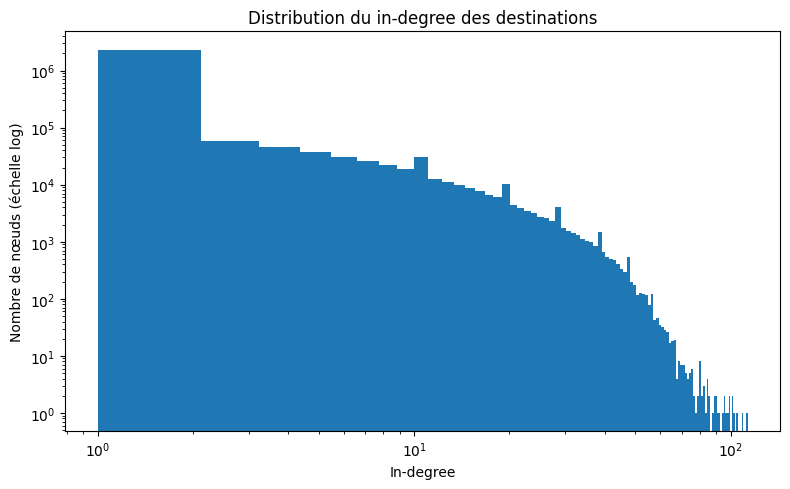

In [155]:
import matplotlib.pyplot as plt

# Visualiser la distribution du in-degree
plt.figure(figsize=(8, 5))

plt.hist(
    positive_in_degree,
    bins=100,
    log=True
)

plt.xscale("log")

plt.xlabel("In-degree")
plt.ylabel("Nombre de nœuds (échelle log)")
plt.title("Distribution du in-degree des destinations")

plt.tight_layout()
plt.show()

In [156]:
# Vérifier la cohérence des degrés
degree_checks = {
    "out_sum_edges": (
        int(out_degree.sum())
        == n_transactions
    ),
    "in_sum_edges": (
        int(in_degree.sum())
        == n_transactions
    ),
    "source_count_match": (
        nodes_with_out_degree
        == n_unique_sources
    ),
    "destination_count_match": (
        nodes_with_in_degree
        == n_unique_destinations
    ),
    "overlap_match": (
        nodes_with_both_degrees
        == n_overlap
    ),
    "no_negative_out_degree": (
        out_degree.min() >= 0
    ),
    "no_negative_in_degree": (
        in_degree.min() >= 0
    )
}

for check, value in degree_checks.items():
    print(
        f"{check:30s} : {value}"
    )

assert all(
    degree_checks.values()
)

print(
    "\nDegree analysis validated."
)

out_sum_edges                  : True
in_sum_edges                   : True
source_count_match             : True
destination_count_match        : True
overlap_match                  : True
no_negative_out_degree         : True
no_negative_in_degree          : True

Degree analysis validated.


In [157]:
print("===== DEGREE STRUCTURE =====")
print(
    "Nodes :",
    f"{n_total_nodes:,}"
)
print(
    "Edges :",
    f"{n_transactions:,}"
)

print("\n===== OUT-DEGREE =====")
print(out_degree_summary.to_string(index=False))

print("\n===== IN-DEGREE =====")
print(in_degree_summary.to_string(index=False))

print("\n===== TOTAL DEGREE =====")
print(total_degree_summary.to_string(index=False))

print("\n===== LOW DEGREE =====")
print(
    f"Degree 1 nodes : "
    f"{degree_1_nodes:,} "
    f"({degree_1_nodes / n_total_nodes * 100:.4f} %)"
)

print(
    f"Degree <= 2 nodes : "
    f"{degree_le_2_nodes:,} "
    f"({degree_le_2_nodes / n_total_nodes * 100:.4f} %)"
)

print("\n===== HUB CONCENTRATION =====")
print(
    in_degree_concentration.to_string(
        index=False
    )
)

print("\n===== PREFIX =====")
print(
    prefix_in_degree_summary.to_string(
        index=False
    )
)

print("\n===== FRAUD DESTINATION DEGREE =====")
print(
    fraud_vs_legit_degree.to_string(
        index=False
    )
)

print("\n===== DEGREE BINS =====")
print(
    degree_fraud_summary.to_string(
        index=False
    )
)

if psutil_available:
    print(
        f"\nRAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

print(
    "\nDegree and connectivity analysis completed."
)

===== DEGREE STRUCTURE =====
Nodes : 9,073,900
Edges : 6,362,620

===== OUT-DEGREE =====
quantile  out_degree
     min         1.0
     50%         1.0
     90%         1.0
     95%         1.0
     99%         1.0
   99.9%         2.0
     max         3.0

===== IN-DEGREE =====
quantile  in_degree
     min        1.0
     50%        1.0
     75%        1.0
     90%        5.0
     95%       10.0
     99%       25.0
   99.9%       44.0
     max      113.0

===== TOTAL DEGREE =====
quantile  total_degree
     min           1.0
     50%           1.0
     75%           1.0
     90%           1.0
     95%           2.0
     99%          14.0
   99.9%          35.0
     max         113.0

===== LOW DEGREE =====
Degree 1 nodes : 8,604,623 (94.8283 %)
Degree <= 2 nodes : 8,691,051 (95.7808 %)

===== HUB CONCENTRATION =====
 top_fraction_nodes_pct  nodes  edge_share_pct
                   0.01    273        0.292584
                   0.10   2723        2.182057
                   1.00  27224

In [158]:
# Libérer les objets temporaires
objects_to_remove = [
    "positive_out_degree",
    "positive_in_degree",
    "positive_total_degree",
    "fraud_mask",
    "fraud_dst_ids",
    "legit_dst_ids",
    "fraud_dst_degree",
    "legit_dst_degree",
    "dst_degree_per_edge",
    "degree_bin_index"
]

for name in objects_to_remove:
    globals().pop(
        name,
        None
    )

gc.collect()

if psutil_available:
    print(
        f"RAM disponible après nettoyage : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM disponible après nettoyage : 2.34 GB


### Section 9 - Key Findings

L'analyse des degrés confirme que le réseau PaySim est extrêmement sparse au niveau des nœuds, avec une forte asymétrie entre sources et destinations.

L'out-degree est presque toujours égal à un. Parmi les comptes apparaissant comme sources, 99 % ont un out-degree de 1 et le maximum observé n'est que de 3. Le voisinage sortant historique des sources est donc très limité.

La distribution de l'in-degree est plus riche. Si la médiane reste égale à 1, le 90e percentile atteint 5, le 95e percentile 10, le 99e percentile 25 et le maximum 113. Comme chaque couple `source → destination` est unique dans PaySim, l'in-degree correspond directement au nombre de sources distinctes ayant interagi avec une destination.

La majorité du réseau reste néanmoins composée de feuilles : **94,83 % des nœuds ont un degré total égal à 1**, 95,78 % un degré inférieur ou égal à 2 et 97,32 % un degré inférieur ou égal à 5.

La connectivité présente une concentration mesurable mais non extrême. Les 10 % de destinations ayant les plus grands in-degrees reçoivent environ **55,85 % des transactions**, tandis que les 1 % les plus connectées en reçoivent environ 14,35 %. La structure relationnelle est donc répartie sur une population significative de destinations récurrentes plutôt que concentrée sur quelques hubs géants.

Une forte différence apparaît selon le préfixe des comptes. Les destinations exclusives `C` présentent un in-degree moyen d'environ 7,36, une médiane de 4 et un maximum de 113. À l'inverse, les comptes `M` ont presque toujours un in-degree égal à 1, avec une moyenne proche de 1 et un maximum de seulement 3. La connectivité non triviale du réseau est donc principalement portée par les destinations `C`.

Les destinations associées aux transactions frauduleuses ne correspondent pas particulièrement aux plus gros hubs. Leur in-degree global est généralement inférieur à celui observé pour les transactions légitimes. Le taux de fraude selon le degré est également non monotone, avec un maximum descriptif observé pour les destinations de degré 2.

Ces statistiques de degré sont cependant calculées sur le graphe final et ne peuvent pas être utilisées directement comme features prédictives, puisqu'elles incorporent potentiellement des transactions futures. Pour une transaction au step \(t\), seuls les degrés construits à partir de \(G_{<t}\) seraient causalement admissibles.

Ces résultats renforcent l'hypothèse selon laquelle la valeur potentielle du Graph Learning dans PaySim doit principalement être recherchée dans le **voisinage historique des destinations récurrentes**, plutôt que dans l'historique des sources ou la répétition de relations exactes.

## 10. Connectivity and Connected Components Analysis

L'analyse des degrés a montré que PaySim est dominé par des nœuds faiblement connectés, avec 94,8 % des comptes de degré total égal à 1.

Cette section étudie maintenant la structure globale du réseau à travers ses composantes faiblement connexes. La direction des transactions est temporairement ignorée uniquement pour déterminer quels nœuds appartiennent au même sous-réseau.

L'objectif est de mesurer :

- le nombre de composantes connexes ;
- leur taille ;
- la taille de la plus grande composante ;
- la proportion de petits sous-graphes ;
- la concentration des transactions dans les composantes ;
- la présence éventuelle de cycles.

Cette analyse reste descriptive et n'utilise aucune topologie future comme information prédictive.

In [159]:
# Vérifier SciPy et la mémoire
import scipy
from scipy import sparse
from scipy.sparse.csgraph import connected_components

print("SciPy :", scipy.__version__)

gc.collect()

if psutil_available:
    print(
        f"RAM processus : "
        f"{process.memory_info().rss / 1024**3:.2f} GB"
    )

    available_gb = (
        psutil.virtual_memory().available / 1024**3
    )

    print(
        f"RAM disponible : "
        f"{available_gb:.2f} GB"
    )

SciPy : 1.17.1
RAM processus : 2.29 GB
RAM disponible : 2.35 GB


In [160]:
# Construire l'adjacence sparse
edge_data = np.ones(
    n_transactions,
    dtype=np.uint8
)

adjacency = sparse.csr_matrix(
    (
        edge_data,
        (src, dst)
    ),
    shape=(
        n_total_nodes,
        n_total_nodes
    ),
    dtype=np.uint8
)

del edge_data
gc.collect()

print("Shape adjacency :", adjacency.shape)
print("Arêtes stockées :", f"{adjacency.nnz:,}")
print("dtype :", adjacency.dtype)

adjacency_memory_mb = (
    adjacency.data.nbytes
    + adjacency.indices.nbytes
    + adjacency.indptr.nbytes
) / 1024**2

print(
    f"Mémoire CSR estimée : "
    f"{adjacency_memory_mb:.2f} MB"
)

assert adjacency.nnz == n_transactions

if psutil_available:
    print(
        f"RAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

Shape adjacency : (9073900, 9073900)
Arêtes stockées : 6,362,620
dtype : uint8
Mémoire CSR estimée : 64.95 MB
RAM disponible : 2.26 GB


In [161]:
# Calculer les composantes faibles
n_components, component_labels = connected_components(
    csgraph=adjacency,
    directed=True,
    connection="weak",
    return_labels=True
)

component_labels = component_labels.astype(
    np.int32,
    copy=False
)

print(
    "Nombre de composantes faibles :",
    f"{n_components:,}"
)

print(
    "Labels shape :",
    component_labels.shape
)

print(
    "Labels dtype :",
    component_labels.dtype
)

print(
    f"Mémoire labels : "
    f"{component_labels.nbytes / 1024**2:.2f} MB"
)

assert len(component_labels) == n_total_nodes

Nombre de composantes faibles : 2,711,280
Labels shape : (9073900,)
Labels dtype : int32
Mémoire labels : 34.61 MB


In [162]:
# Compter les nœuds par composante
component_node_counts = np.bincount(
    component_labels,
    minlength=n_components
)

print(
    "Somme des nœuds :",
    f"{component_node_counts.sum():,}"
)

print(
    "Taille minimale :",
    f"{component_node_counts.min():,}"
)

print(
    "Taille maximale :",
    f"{component_node_counts.max():,}"
)

largest_component_id = int(
    np.argmax(component_node_counts)
)

largest_component_nodes = int(
    component_node_counts[
        largest_component_id
    ]
)

largest_component_node_pct = (
    largest_component_nodes
    / n_total_nodes
    * 100
)

print(
    "\nPlus grande composante ID :",
    largest_component_id
)

print(
    "Nœuds plus grande composante :",
    f"{largest_component_nodes:,}"
)

print(
    f"Part des nœuds : "
    f"{largest_component_node_pct:.6f} %"
)

assert component_node_counts.sum() == n_total_nodes

Somme des nœuds : 9,073,900
Taille minimale : 2
Taille maximale : 121

Plus grande composante ID : 12900
Nœuds plus grande composante : 121
Part des nœuds : 0.001333 %


In [163]:
# Résumer la taille des composantes
component_size_quantiles = np.quantile(
    component_node_counts,
    [
        0,
        0.25,
        0.50,
        0.75,
        0.90,
        0.95,
        0.99,
        0.999,
        1.0
    ]
)

component_size_summary = pd.DataFrame({
    "quantile": [
        "min",
        "25%",
        "50%",
        "75%",
        "90%",
        "95%",
        "99%",
        "99.9%",
        "max"
    ],
    "component_nodes": component_size_quantiles
})

component_size_summary

,quantile,component_nodes
0,min,2.0
1,25%,2.0
2,50%,2.0
3,75%,2.0
4,90%,6.0
5,95%,11.0
6,99%,26.0
7,99.9%,47.0
8,max,121.0


In [164]:
# Compter les petites composantes
component_size_categories = {
    "size_2": int(
        np.count_nonzero(
            component_node_counts == 2
        )
    ),
    "size_3": int(
        np.count_nonzero(
            component_node_counts == 3
        )
    ),
    "size_4_5": int(
        np.count_nonzero(
            (component_node_counts >= 4)
            &
            (component_node_counts <= 5)
        )
    ),
    "size_6_10": int(
        np.count_nonzero(
            (component_node_counts >= 6)
            &
            (component_node_counts <= 10)
        )
    ),
    "size_11_50": int(
        np.count_nonzero(
            (component_node_counts >= 11)
            &
            (component_node_counts <= 50)
        )
    ),
    "size_gt_50": int(
        np.count_nonzero(
            component_node_counts > 50
        )
    )
}

for key, value in component_size_categories.items():
    print(
        f"{key:12s} : {value:,}"
    )

size_2       : 2,255,093
size_3       : 77,628
size_4_5     : 101,527
size_6_10    : 131,759
size_11_50   : 143,471
size_gt_50   : 1,802


In [165]:
# Vérifier les composantes isolées
isolated_components = int(
    np.count_nonzero(
        component_node_counts == 1
    )
)

print(
    "Composantes de taille 1 :",
    f"{isolated_components:,}"
)

assert isolated_components == 0

Composantes de taille 1 : 0


In [166]:
# Compter les arêtes par composante
edge_component_labels = (
    component_labels[src]
)

component_edge_counts = np.bincount(
    edge_component_labels,
    minlength=n_components
)

print(
    "Somme des arêtes :",
    f"{component_edge_counts.sum():,}"
)

print(
    "Arêtes minimum / composante :",
    f"{component_edge_counts.min():,}"
)

print(
    "Arêtes maximum / composante :",
    f"{component_edge_counts.max():,}"
)

assert component_edge_counts.sum() == n_transactions

Somme des arêtes : 6,362,620
Arêtes minimum / composante : 1
Arêtes maximum / composante : 120


In [167]:
# Mesurer la plus grande composante
largest_component_edges = int(
    component_edge_counts[
        largest_component_id
    ]
)

largest_component_edge_pct = (
    largest_component_edges
    / n_transactions
    * 100
)

print(
    "Plus grande composante :",
    largest_component_id
)

print(
    "Nœuds :",
    f"{largest_component_nodes:,}"
)

print(
    "Arêtes :",
    f"{largest_component_edges:,}"
)

print(
    f"Part des nœuds : "
    f"{largest_component_node_pct:.6f} %"
)

print(
    f"Part des arêtes : "
    f"{largest_component_edge_pct:.6f} %"
)

Plus grande composante : 12900
Nœuds : 121
Arêtes : 120
Part des nœuds : 0.001333 %
Part des arêtes : 0.001886 %


In [168]:
# Identifier les composantes avec cycles
tree_components_mask = (
    component_edge_counts
    ==
    component_node_counts - 1
)

cyclic_components_mask = (
    component_edge_counts
    >=
    component_node_counts
)

n_tree_components = int(
    tree_components_mask.sum()
)

n_cyclic_components = int(
    cyclic_components_mask.sum()
)

print(
    "Composantes arbres :",
    f"{n_tree_components:,}"
)

print(
    f"Proportion : "
    f"{n_tree_components / n_components * 100:.6f} %"
)

print(
    "\nComposantes avec au moins un cycle :",
    f"{n_cyclic_components:,}"
)

print(
    f"Proportion : "
    f"{n_cyclic_components / n_components * 100:.6f} %"
)

assert (
    n_tree_components
    + n_cyclic_components
    == n_components
)

Composantes arbres : 2,711,280
Proportion : 100.000000 %

Composantes avec au moins un cycle : 0
Proportion : 0.000000 %


In [169]:
# Mesurer l'excès d'arêtes
component_cycle_excess = (
    component_edge_counts.astype(np.int64)
    -
    component_node_counts.astype(np.int64)
    + 1
)

max_cycle_excess = int(
    component_cycle_excess.max()
)

total_cycle_excess = int(
    component_cycle_excess[
        component_cycle_excess > 0
    ].sum()
)

print(
    "Excès cyclomatique total :",
    f"{total_cycle_excess:,}"
)

print(
    "Maximum dans une composante :",
    f"{max_cycle_excess:,}"
)

Excès cyclomatique total : 0
Maximum dans une composante : 0


In [170]:
# Mesurer la part des nœuds par taille de composante
node_size_records = []

size_groups = [
    ("2", 2, 2),
    ("3-5", 3, 5),
    ("6-10", 6, 10),
    ("11-50", 11, 50),
    ("51-100", 51, 100),
    (">100", 101, None)
]

for label, low, high in size_groups:
    if high is None:
        mask = (
            component_node_counts >= low
        )
    else:
        mask = (
            (component_node_counts >= low)
            &
            (component_node_counts <= high)
        )

    components = int(
        mask.sum()
    )

    nodes = int(
        component_node_counts[
            mask
        ].sum()
    )

    edges = int(
        component_edge_counts[
            mask
        ].sum()
    )

    node_size_records.append({
        "component_size": label,
        "components": components,
        "nodes": nodes,
        "node_pct": (
            nodes
            / n_total_nodes
            * 100
        ),
        "edges": edges,
        "edge_pct": (
            edges
            / n_transactions
            * 100
        )
    })

component_size_distribution = pd.DataFrame(
    node_size_records
)

component_size_distribution

,component_size,components,nodes,node_pct,edges,edge_pct
0,2,2255093,4510186,49.705044,2255093,35.442836
1,3-5,179155,683691,7.534698,504536,7.929689
2,6-10,131759,1009407,11.124291,877648,13.793814
3,11-50,143471,2762296,30.442213,2618825,41.159538
4,51-100,1785,106431,1.172936,104646,1.644700
5,>100,17,1889,0.020818,1872,0.029422


In [171]:
# Extraire les plus grandes composantes
TOP_COMPONENTS = 20

top_component_ids = np.argpartition(
    component_node_counts,
    -TOP_COMPONENTS
)[-TOP_COMPONENTS:]

top_component_ids = top_component_ids[
    np.argsort(
        component_node_counts[
            top_component_ids
        ]
    )[::-1]
]

top_components_df = pd.DataFrame({
    "component_id": top_component_ids,
    "nodes": component_node_counts[
        top_component_ids
    ],
    "edges": component_edge_counts[
        top_component_ids
    ]
})

top_components_df["cycle_excess"] = (
    top_components_df["edges"]
    -
    top_components_df["nodes"]
    + 1
)

top_components_df

,component_id,nodes,edges,cycle_excess
0,12900,121,120,0
1,144,119,118,0
2,2524,119,118,0
3,6836,118,117,0
4,26699,118,117,0
5,19086,115,114,0
6,6333,114,113,0
7,85,114,113,0
8,13750,114,113,0
9,102,110,109,0


In [172]:
# Compter les fraudes par composante
fraud_mask = (
    edge_labels == 1
)

fraud_component_labels = (
    component_labels[
        src[fraud_mask]
    ]
)

component_fraud_counts = np.bincount(
    fraud_component_labels,
    minlength=n_components
)

fraud_components = int(
    np.count_nonzero(
        component_fraud_counts
    )
)

print(
    "Composantes contenant au moins une fraude :",
    f"{fraud_components:,}"
)

print(
    f"Proportion des composantes : "
    f"{fraud_components / n_components * 100:.6f} %"
)

print(
    "Maximum de fraudes dans une composante :",
    f"{component_fraud_counts.max():,}"
)

assert component_fraud_counts.sum() == edge_labels.sum()

Composantes contenant au moins une fraude : 8,169
Proportion des composantes : 0.301297 %
Maximum de fraudes dans une composante : 2


In [173]:
# Comparer les tailles des composantes des fraudes
fraud_component_sizes_per_edge = (
    component_node_counts[
        fraud_component_labels
    ]
)

legit_component_labels = (
    component_labels[
        src[~fraud_mask]
    ]
)

legit_component_sizes_per_edge = (
    component_node_counts[
        legit_component_labels
    ]
)

fraud_component_size_quantiles = np.quantile(
    fraud_component_sizes_per_edge,
    [0, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0]
)

legit_component_size_quantiles = np.quantile(
    legit_component_sizes_per_edge,
    [0, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0]
)

fraud_vs_legit_component_size = pd.DataFrame({
    "quantile": [
        "min",
        "50%",
        "75%",
        "90%",
        "95%",
        "99%",
        "max"
    ],
    "fraud_component_nodes":
        fraud_component_size_quantiles,
    "legit_component_nodes":
        legit_component_size_quantiles
})

fraud_vs_legit_component_size

,quantile,fraud_component_nodes,legit_component_nodes
0,min,2.0,2.0
1,50%,5.0,8.0
2,75%,13.0,19.0
3,90%,23.0,31.0
4,95%,31.0,40.0
5,99%,49.0,56.0
6,max,90.0,121.0


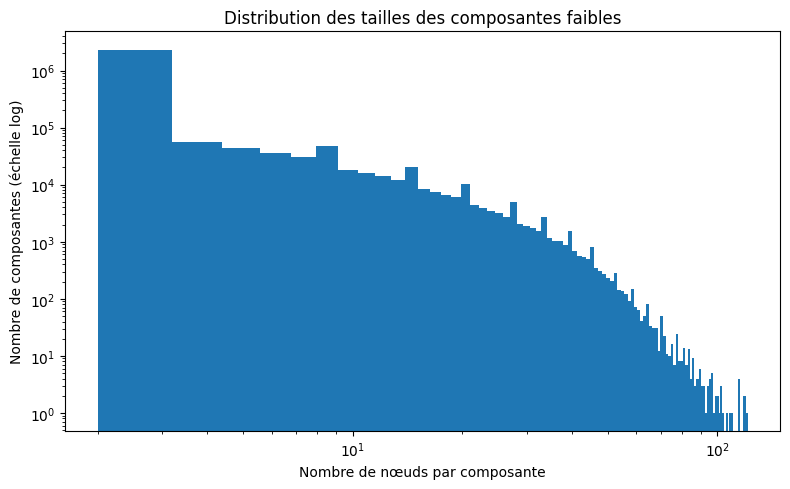

In [174]:
# Visualiser les tailles des composantes
plt.figure(figsize=(8, 5))

plt.hist(
    component_node_counts,
    bins=100,
    log=True
)

plt.xscale("log")

plt.xlabel("Nombre de nœuds par composante")
plt.ylabel("Nombre de composantes (échelle log)")
plt.title("Distribution des tailles des composantes faibles")

plt.tight_layout()
plt.show()

In [175]:
# Vérifier la cohérence des composantes
component_checks = {
    "nodes_sum": (
        int(component_node_counts.sum())
        == n_total_nodes
    ),
    "edges_sum": (
        int(component_edge_counts.sum())
        == n_transactions
    ),
    "no_isolated_nodes": (
        isolated_components == 0
    ),
    "largest_component_valid": (
        largest_component_nodes > 1
    ),
    "all_components_connected_structure": (
        np.all(
            component_edge_counts
            >= component_node_counts - 1
        )
    ),
    "tree_or_cyclic_complete": (
        n_tree_components
        + n_cyclic_components
        == n_components
    ),
    "fraud_sum": (
        int(component_fraud_counts.sum())
        == int(edge_labels.sum())
    )
}

for check, value in component_checks.items():
    print(
        f"{check:38s} : {value}"
    )

assert all(
    component_checks.values()
)

print(
    "\nConnectivity analysis validated."
)

nodes_sum                              : True
edges_sum                              : True
no_isolated_nodes                      : True
largest_component_valid                : True
all_components_connected_structure     : True
tree_or_cyclic_complete                : True
fraud_sum                              : True

Connectivity analysis validated.


In [176]:
print("===== CONNECTIVITY =====")
print(
    "Nodes :",
    f"{n_total_nodes:,}"
)
print(
    "Edges :",
    f"{n_transactions:,}"
)
print(
    "Weak components :",
    f"{n_components:,}"
)

print("\n===== LARGEST COMPONENT =====")
print(
    "Nodes :",
    f"{largest_component_nodes:,}",
    f"({largest_component_node_pct:.6f} %)"
)
print(
    "Edges :",
    f"{largest_component_edges:,}",
    f"({largest_component_edge_pct:.6f} %)"
)

print("\n===== COMPONENT SIZE =====")
print(
    component_size_summary.to_string(
        index=False
    )
)

print("\n===== SIZE DISTRIBUTION =====")
print(
    component_size_distribution.to_string(
        index=False
    )
)

print("\n===== CYCLES =====")
print(
    "Tree components :",
    f"{n_tree_components:,}",
    f"({n_tree_components / n_components * 100:.6f} %)"
)
print(
    "Cyclic components :",
    f"{n_cyclic_components:,}",
    f"({n_cyclic_components / n_components * 100:.6f} %)"
)
print(
    "Total cycle excess :",
    f"{total_cycle_excess:,}"
)

print("\n===== FRAUD =====")
print(
    "Fraud components :",
    f"{fraud_components:,}"
)
print(
    "Max frauds / component :",
    f"{component_fraud_counts.max():,}"
)

print("\n===== FRAUD VS LEGIT COMPONENT SIZE =====")
print(
    fraud_vs_legit_component_size.to_string(
        index=False
    )
)

if psutil_available:
    print(
        f"\nRAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

print(
    "\nConnectivity and connected components analysis completed."
)

===== CONNECTIVITY =====
Nodes : 9,073,900
Edges : 6,362,620
Weak components : 2,711,280

===== LARGEST COMPONENT =====
Nodes : 121 (0.001333 %)
Edges : 120 (0.001886 %)

===== COMPONENT SIZE =====
quantile  component_nodes
     min              2.0
     25%              2.0
     50%              2.0
     75%              2.0
     90%              6.0
     95%             11.0
     99%             26.0
   99.9%             47.0
     max            121.0

===== SIZE DISTRIBUTION =====
component_size  components   nodes  node_pct   edges  edge_pct
             2     2255093 4510186 49.705044 2255093 35.442836
           3-5      179155  683691  7.534698  504536  7.929689
          6-10      131759 1009407 11.124291  877648 13.793814
         11-50      143471 2762296 30.442213 2618825 41.159538
        51-100        1785  106431  1.172936  104646  1.644700
          >100          17    1889  0.020818    1872  0.029422

===== CYCLES =====
Tree components : 2,711,280 (100.000000 %)
Cyclic 

In [177]:
# Libérer les objets lourds temporaires
objects_to_remove = [
    "adjacency",
    "edge_component_labels",
    "tree_components_mask",
    "cyclic_components_mask",
    "component_cycle_excess",
    "fraud_mask",
    "fraud_component_labels",
    "fraud_component_sizes_per_edge",
    "legit_component_labels",
    "legit_component_sizes_per_edge"
]

for name in objects_to_remove:
    globals().pop(
        name,
        None
    )

gc.collect()

if psutil_available:
    print(
        f"RAM disponible après nettoyage : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM disponible après nettoyage : 2.18 GB


### Section 10 - Key Findings

L'analyse de connectivité révèle que le réseau PaySim est extrêmement fragmenté. Les **9 073 900 nœuds** et **6 362 620 arêtes** sont répartis dans **2 711 280 composantes faiblement connexes**.

Aucune giant component n'existe. La plus grande composante ne contient que **121 nœuds et 120 arêtes**, soit environ 0,0013 % des nœuds et 0,0019 % des transactions.

La composante typique est particulièrement petite. Les 25e, 50e et 75e percentiles sont tous égaux à deux nœuds. Au total, **2 255 093 composantes sont constituées de seulement deux comptes**, représentant près de 49,7 % de tous les nœuds et 35,4 % des transactions.

Une part importante des transactions appartient néanmoins à des sous-graphes légèrement plus grands. Les composantes de 11 à 50 nœuds regroupent environ 30,4 % des nœuds et 41,2 % des arêtes, tandis que celles de 6 à 10 nœuds concentrent encore environ 13,8 % des transactions.

La propriété structurelle la plus forte est l'absence totale de cycles. Les **2 711 280 composantes sont toutes des arbres**, avec exactement \(E = V - 1\) dans chaque composante. Aucun excès cyclomatique n'est observé sur l'ensemble du graphe.

Cette structure est cohérente avec les analyses précédentes : les relations source-destination sont toutes uniques, aucune relation réciproque n'existe et très peu de comptes apparaissent dans les deux rôles. PaySim peut donc être décrit comme une immense forêt de petits sous-réseaux acycliques plutôt que comme un réseau transactionnel globalement interconnecté.

Les fraudes sont également très dispersées. Seules 8 169 composantes contiennent au moins une transaction frauduleuse et aucune composante n'en contient plus de deux. Les transactions frauduleuses appartiennent en moyenne à des composantes légèrement plus petites que les transactions légitimes.

Ces résultats limitent la profondeur relationnelle réellement disponible pour le message passing. Une architecture GNN profonde semble peu justifiée dans un réseau dominé par de petits arbres et des feuilles. Des modèles peu profonds capables d'exploiter principalement le voisinage local des destinations semblent a priori plus cohérents avec la structure observée.

La forme exacte de ces arbres doit néanmoins encore être caractérisée avant de conclure qu'une seule couche de voisinage suffit dans la majorité des cas.

## 11. Tree Shape and Message-Passing Depth Analysis

L'analyse de connectivité a montré que le graphe PaySim est une forêt composée exclusivement d'arbres.

Cette section caractérise la forme de ces arbres afin d'estimer la profondeur relationnelle réellement disponible pour les futurs GNN.

Une composante est considérée comme une étoile lorsque son degré maximal est égal à \(V-1\), où \(V\) représente son nombre de nœuds. Dans ce cas, toutes les feuilles sont directement reliées à un unique centre et le diamètre de la composante est au maximum égal à deux.

L'analyse distingue les paires isolées, les étoiles non triviales et les arbres non étoilés. Elle étudie également le rôle du nœud central et la contribution des rares comptes apparaissant à la fois comme source et destination.

In [178]:
# Vérifier la mémoire disponible
gc.collect()

if psutil_available:
    print(
        f"RAM processus : "
        f"{process.memory_info().rss / 1024**3:.2f} GB"
    )

    print(
        f"RAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

print("Composantes :", f"{n_components:,}")
print("Nœuds :", f"{n_total_nodes:,}")

RAM processus : 2.39 GB
RAM disponible : 2.29 GB
Composantes : 2,711,280
Nœuds : 9,073,900


In [179]:
# Calculer le degré maximal par composante
component_max_degree = np.zeros(
    n_components,
    dtype=np.int32
)

np.maximum.at(
    component_max_degree,
    component_labels,
    total_degree
)

print(
    "Degré maximal global :",
    int(component_max_degree.max())
)

print(
    f"Mémoire component_max_degree : "
    f"{component_max_degree.nbytes / 1024**2:.2f} MB"
)

assert (
    component_max_degree.max()
    == total_degree.max()
)

Degré maximal global : 113
Mémoire component_max_degree : 10.34 MB


In [180]:
# Identifier les composantes en étoile
star_component_mask = (
    component_max_degree
    ==
    component_node_counts - 1
)

pair_component_mask = (
    component_node_counts == 2
)

nontrivial_star_mask = (
    star_component_mask
    &
    (component_node_counts >= 3)
)

nonstar_component_mask = (
    ~star_component_mask
)

n_star_components = int(
    star_component_mask.sum()
)

n_pair_components = int(
    pair_component_mask.sum()
)

n_nontrivial_stars = int(
    nontrivial_star_mask.sum()
)

n_nonstar_components = int(
    nonstar_component_mask.sum()
)

print(
    "Étoiles totales :",
    f"{n_star_components:,}"
)

print(
    "Paires isolées :",
    f"{n_pair_components:,}"
)

print(
    "Étoiles non triviales :",
    f"{n_nontrivial_stars:,}"
)

print(
    "Arbres non étoilés :",
    f"{n_nonstar_components:,}"
)

print(
    f"\nProportion de composantes étoiles : "
    f"{n_star_components / n_components * 100:.6f} %"
)

Étoiles totales : 2,702,425
Paires isolées : 2,255,093
Étoiles non triviales : 447,332
Arbres non étoilés : 8,855

Proportion de composantes étoiles : 99.673401 %


In [181]:
# Résumer les formes des composantes
shape_records = []

shape_groups = [
    (
        "Pair",
        pair_component_mask
    ),
    (
        "Non-trivial star",
        nontrivial_star_mask
    ),
    (
        "Non-star tree",
        nonstar_component_mask
    )
]

for label, mask in shape_groups:
    components = int(
        mask.sum()
    )

    nodes = int(
        component_node_counts[
            mask
        ].sum()
    )

    edges = int(
        component_edge_counts[
            mask
        ].sum()
    )

    shape_records.append({
        "shape": label,
        "components": components,
        "component_pct": (
            components / n_components * 100
        ),
        "nodes": nodes,
        "node_pct": (
            nodes / n_total_nodes * 100
        ),
        "edges": edges,
        "edge_pct": (
            edges / n_transactions * 100
        )
    })

component_shape_summary = pd.DataFrame(
    shape_records
)

component_shape_summary

,shape,components,component_pct,nodes,node_pct,edges,edge_pct
0,Pair,2255093,83.174478,4510186,49.705044,2255093,35.442836
1,Non-trivial star,447332,16.498923,4330203,47.721520,3882871,61.026291
2,Non-star tree,8855,0.326599,233511,2.573436,224656,3.530873


In [182]:
# Identifier les nœuds internes
internal_node_ids = np.flatnonzero(
    total_degree > 1
)

internal_component_labels = (
    component_labels[
        internal_node_ids
    ]
)

component_internal_counts = np.bincount(
    internal_component_labels,
    minlength=n_components
).astype(np.int16)

print(
    "Nœuds internes totaux :",
    f"{len(internal_node_ids):,}"
)

print(
    "Maximum de nœuds internes "
    "dans une composante :",
    int(component_internal_counts.max())
)

print(
    f"Mémoire component_internal_counts : "
    f"{component_internal_counts.nbytes / 1024**2:.2f} MB"
)

Nœuds internes totaux : 469,277
Maximum de nœuds internes dans une composante : 8
Mémoire component_internal_counts : 5.17 MB


In [183]:
# Résumer les nœuds internes
internal_structure_records = []

internal_groups = [
    (
        "0 internal nodes",
        component_internal_counts == 0
    ),
    (
        "1 internal node",
        component_internal_counts == 1
    ),
    (
        "2 internal nodes",
        component_internal_counts == 2
    ),
    (
        "3-5 internal nodes",
        (
            (component_internal_counts >= 3)
            &
            (component_internal_counts <= 5)
        )
    ),
    (
        ">5 internal nodes",
        component_internal_counts > 5
    )
]

for label, mask in internal_groups:
    components = int(
        mask.sum()
    )

    nodes = int(
        component_node_counts[
            mask
        ].sum()
    )

    edges = int(
        component_edge_counts[
            mask
        ].sum()
    )

    internal_structure_records.append({
        "internal_structure": label,
        "components": components,
        "component_pct": (
            components / n_components * 100
        ),
        "nodes": nodes,
        "node_pct": (
            nodes / n_total_nodes * 100
        ),
        "edges": edges,
        "edge_pct": (
            edges / n_transactions * 100
        )
    })

internal_structure_summary = pd.DataFrame(
    internal_structure_records
)

internal_structure_summary

,internal_structure,components,component_pct,nodes,node_pct,edges,edge_pct
0,0 internal nodes,2255093,83.174478,4510186,49.705044,2255093,35.442836
1,1 internal node,447332,16.498923,4330203,47.721520,3882871,61.026291
2,2 internal nodes,5037,0.185779,99984,1.101886,94947,1.492263
3,3-5 internal nodes,3803,0.140266,132448,1.459659,128645,2.021887
4,>5 internal nodes,15,0.000553,1079,0.011891,1064,0.016723


In [184]:
# Vérifier la forme des arbres
pair_internal_ok = bool(
    np.all(
        component_internal_counts[
            pair_component_mask
        ]
        == 0
    )
)

star_internal_ok = bool(
    np.all(
        component_internal_counts[
            nontrivial_star_mask
        ]
        == 1
    )
)

nonstar_internal_ok = bool(
    np.all(
        component_internal_counts[
            nonstar_component_mask
        ]
        >= 2
    )
)

print(
    "Paires sans nœud interne :",
    pair_internal_ok
)

print(
    "Étoiles avec un seul centre :",
    star_internal_ok
)

print(
    "Arbres non étoilés avec >=2 internes :",
    nonstar_internal_ok
)

assert pair_internal_ok
assert star_internal_ok
assert nonstar_internal_ok

print(
    "\nStructure interne des arbres : OK"
)

Paires sans nœud interne : True
Étoiles avec un seul centre : True
Arbres non étoilés avec >=2 internes : True

Structure interne des arbres : OK


In [185]:
# Identifier les centres des étoiles
internal_star_mask = (
    nontrivial_star_mask[
        internal_component_labels
    ]
)

star_center_ids = (
    internal_node_ids[
        internal_star_mask
    ]
)

star_center_roles = (
    node_role_code[
        star_center_ids
    ]
)

star_center_role_counts = np.bincount(
    star_center_roles,
    minlength=3
)

star_center_role_summary = pd.DataFrame({
    "role_code": [0, 1, 2],
    "role": [
        "Source only",
        "Destination only",
        "Both"
    ],
    "star_centers": star_center_role_counts
})

star_center_role_summary["percentage"] = (
    star_center_role_summary["star_centers"]
    / len(star_center_ids)
    * 100
)

star_center_role_summary

,role_code,role,star_centers,percentage
0,0,Source only,1210,0.270493
1,1,Destination only,445484,99.586884
2,2,Both,638,0.142623


In [186]:
# Classer la direction des étoiles
center_in = in_degree[
    star_center_ids
]

center_out = out_degree[
    star_center_ids
]

convergent_star = (
    (center_in > 0)
    &
    (center_out == 0)
)

divergent_star = (
    (center_out > 0)
    &
    (center_in == 0)
)

mixed_star = (
    (center_in > 0)
    &
    (center_out > 0)
)

star_direction_summary = pd.DataFrame({
    "star_type": [
        "Convergent",
        "Divergent",
        "Mixed"
    ],
    "components": [
        int(convergent_star.sum()),
        int(divergent_star.sum()),
        int(mixed_star.sum())
    ]
})

star_direction_summary["percentage"] = (
    star_direction_summary["components"]
    / len(star_center_ids)
    * 100
)

star_direction_summary

,star_type,components,percentage
0,Convergent,445484,99.586884
1,Divergent,1210,0.270493
2,Mixed,638,0.142623


In [187]:
# Identifier les composantes avec un nœud Both
both_node_ids = np.flatnonzero(
    node_role_code == 2
)

both_component_counts = np.bincount(
    component_labels[
        both_node_ids
    ],
    minlength=n_components
)

components_with_both_mask = (
    both_component_counts > 0
)

n_components_with_both = int(
    components_with_both_mask.sum()
)

nonstar_with_both = int(
    np.count_nonzero(
        nonstar_component_mask
        &
        components_with_both_mask
    )
)

star_with_both = int(
    np.count_nonzero(
        star_component_mask
        &
        components_with_both_mask
    )
)

print(
    "Nœuds Both :",
    f"{len(both_node_ids):,}"
)

print(
    "Composantes contenant un Both :",
    f"{n_components_with_both:,}"
)

print(
    "Arbres non étoilés contenant un Both :",
    f"{nonstar_with_both:,}"
)

print(
    "Étoiles contenant un Both :",
    f"{star_with_both:,}"
)

if n_nonstar_components > 0:
    print(
        f"\nPart des arbres non étoilés "
        f"avec un Both : "
        f"{nonstar_with_both / n_nonstar_components * 100:.6f} %"
    )

Nœuds Both : 1,769
Composantes contenant un Both : 1,762
Arbres non étoilés contenant un Both : 1,124
Étoiles contenant un Both : 638

Part des arbres non étoilés avec un Both : 12.693394 %


In [188]:
# Étudier les arbres non étoilés
nonstar_sizes = (
    component_node_counts[
        nonstar_component_mask
    ]
)

if len(nonstar_sizes) > 0:
    nonstar_size_quantiles = np.quantile(
        nonstar_sizes,
        [
            0,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
            1.0
        ]
    )

    nonstar_size_summary = pd.DataFrame({
        "quantile": [
            "min",
            "50%",
            "75%",
            "90%",
            "95%",
            "99%",
            "max"
        ],
        "nonstar_component_nodes":
            nonstar_size_quantiles
    })
else:
    nonstar_size_summary = pd.DataFrame()

nonstar_size_summary

,quantile,nonstar_component_nodes
0,min,4.0
1,50%,23.0
2,75%,36.0
3,90%,49.0
4,95%,58.0
5,99%,78.0
6,max,121.0


In [189]:
# Mesurer la couverture des étoiles
star_nodes = int(
    component_node_counts[
        star_component_mask
    ].sum()
)

star_edges = int(
    component_edge_counts[
        star_component_mask
    ].sum()
)

star_node_pct = (
    star_nodes / n_total_nodes * 100
)

star_edge_pct = (
    star_edges / n_transactions * 100
)

print(
    "Nœuds dans des composantes étoiles :",
    f"{star_nodes:,}"
)

print(
    f"Part des nœuds : "
    f"{star_node_pct:.6f} %"
)

print(
    "\nArêtes dans des composantes étoiles :",
    f"{star_edges:,}"
)

print(
    f"Part des arêtes : "
    f"{star_edge_pct:.6f} %"
)

Nœuds dans des composantes étoiles : 8,840,389
Part des nœuds : 97.426564 %

Arêtes dans des composantes étoiles : 6,137,964
Part des arêtes : 96.469127 %


In [190]:
# Résumer la profondeur structurelle
depth_proxy_records = []

depth_groups = [
    (
        "1 hop sufficient",
        pair_component_mask
    ),
    (
        "<=2 hops sufficient",
        nontrivial_star_mask
    ),
    (
        ">2 hops may be useful",
        nonstar_component_mask
    )
]

for label, mask in depth_groups:
    components = int(
        mask.sum()
    )

    nodes = int(
        component_node_counts[
            mask
        ].sum()
    )

    edges = int(
        component_edge_counts[
            mask
        ].sum()
    )

    depth_proxy_records.append({
        "structural_depth": label,
        "components": components,
        "nodes": nodes,
        "node_pct": (
            nodes / n_total_nodes * 100
        ),
        "edges": edges,
        "edge_pct": (
            edges / n_transactions * 100
        )
    })

message_passing_depth_summary = pd.DataFrame(
    depth_proxy_records
)

message_passing_depth_summary

,structural_depth,components,nodes,node_pct,edges,edge_pct
0,1 hop sufficient,2255093,4510186,49.705044,2255093,35.442836
1,<=2 hops sufficient,447332,4330203,47.721520,3882871,61.026291
2,>2 hops may be useful,8855,233511,2.573436,224656,3.530873


In [191]:
# Ajouter la forme aux grandes composantes
top_components_shape_df = (
    top_components_df.copy()
)

top_ids = (
    top_components_shape_df[
        "component_id"
    ].to_numpy()
)

top_components_shape_df[
    "max_degree"
] = component_max_degree[
    top_ids
]

top_components_shape_df[
    "internal_nodes"
] = component_internal_counts[
    top_ids
]

top_components_shape_df[
    "is_star"
] = star_component_mask[
    top_ids
]

top_components_shape_df[
    "has_both_node"
] = components_with_both_mask[
    top_ids
]

top_components_shape_df

,component_id,nodes,edges,cycle_excess,max_degree,internal_nodes,is_star,has_both_node
0,12900,121,120,0,54,5,False,False
1,144,119,118,0,102,3,False,False
2,2524,119,118,0,73,3,False,False
3,6836,118,117,0,50,7,False,False
4,26699,118,117,0,46,7,False,False
5,19086,115,114,0,50,5,False,False
6,6333,114,113,0,61,4,False,True
7,85,114,113,0,113,1,True,False
8,13750,114,113,0,46,5,False,False
9,102,110,109,0,109,1,True,False


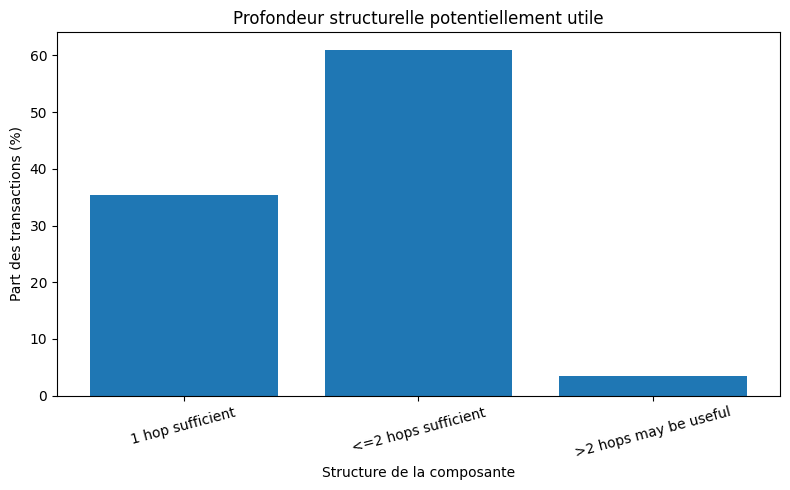

In [192]:
# Visualiser la profondeur structurelle
plt.figure(figsize=(8, 5))

plt.bar(
    message_passing_depth_summary[
        "structural_depth"
    ],
    message_passing_depth_summary[
        "edge_pct"
    ]
)

plt.ylabel("Part des transactions (%)")
plt.xlabel("Structure de la composante")
plt.title(
    "Profondeur structurelle potentiellement utile"
)

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [193]:
# Vérifier la cohérence des formes
tree_shape_checks = {
    "all_components_classified": (
        n_star_components
        + n_nonstar_components
        == n_components
    ),
    "star_split_complete": (
        n_pair_components
        + n_nontrivial_stars
        == n_star_components
    ),
    "pair_internal_valid": (
        pair_internal_ok
    ),
    "star_internal_valid": (
        star_internal_ok
    ),
    "nonstar_internal_valid": (
        nonstar_internal_ok
    ),
    "shape_nodes_sum": (
        int(
            component_shape_summary[
                "nodes"
            ].sum()
        )
        == n_total_nodes
    ),
    "shape_edges_sum": (
        int(
            component_shape_summary[
                "edges"
            ].sum()
        )
        == n_transactions
    ),
    "depth_edges_sum": (
        int(
            message_passing_depth_summary[
                "edges"
            ].sum()
        )
        == n_transactions
    ),
    "star_centers_match": (
        len(star_center_ids)
        == n_nontrivial_stars
    )
}

for check, value in tree_shape_checks.items():
    print(
        f"{check:32s} : {value}"
    )

assert all(
    tree_shape_checks.values()
)

print(
    "\nTree shape analysis validated."
)

all_components_classified        : True
star_split_complete              : True
pair_internal_valid              : True
star_internal_valid              : True
nonstar_internal_valid           : True
shape_nodes_sum                  : True
shape_edges_sum                  : True
depth_edges_sum                  : True
star_centers_match               : True

Tree shape analysis validated.


In [194]:
print("===== TREE SHAPE =====")
print(
    "Components :",
    f"{n_components:,}"
)
print(
    "Stars :",
    f"{n_star_components:,}",
    f"({n_star_components / n_components * 100:.4f} %)"
)
print(
    "Non-star trees :",
    f"{n_nonstar_components:,}",
    f"({n_nonstar_components / n_components * 100:.4f} %)"
)

print("\n===== SHAPE DISTRIBUTION =====")
print(
    component_shape_summary.to_string(
        index=False
    )
)

print("\n===== INTERNAL NODES =====")
print(
    internal_structure_summary.to_string(
        index=False
    )
)

print("\n===== STAR CENTER ROLES =====")
print(
    star_center_role_summary.to_string(
        index=False
    )
)

print("\n===== STAR DIRECTION =====")
print(
    star_direction_summary.to_string(
        index=False
    )
)

print("\n===== BOTH-ROLE NODES =====")
print(
    "Both nodes :",
    f"{len(both_node_ids):,}"
)
print(
    "Components with Both :",
    f"{n_components_with_both:,}"
)
print(
    "Non-star with Both :",
    f"{nonstar_with_both:,}"
)

print("\n===== MESSAGE PASSING DEPTH =====")
print(
    message_passing_depth_summary.to_string(
        index=False
    )
)

print("\n===== NON-STAR SIZE =====")
print(
    nonstar_size_summary.to_string(
        index=False
    )
)

if psutil_available:
    print(
        f"\nRAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

print(
    "\nTree shape and message-passing depth analysis completed."
)

===== TREE SHAPE =====
Components : 2,711,280
Stars : 2,702,425 (99.6734 %)
Non-star trees : 8,855 (0.3266 %)

===== SHAPE DISTRIBUTION =====
           shape  components  component_pct   nodes  node_pct   edges  edge_pct
            Pair     2255093      83.174478 4510186 49.705044 2255093 35.442836
Non-trivial star      447332      16.498923 4330203 47.721520 3882871 61.026291
   Non-star tree        8855       0.326599  233511  2.573436  224656  3.530873

===== INTERNAL NODES =====
internal_structure  components  component_pct   nodes  node_pct   edges  edge_pct
  0 internal nodes     2255093      83.174478 4510186 49.705044 2255093 35.442836
   1 internal node      447332      16.498923 4330203 47.721520 3882871 61.026291
  2 internal nodes        5037       0.185779   99984  1.101886   94947  1.492263
3-5 internal nodes        3803       0.140266  132448  1.459659  128645  2.021887
 >5 internal nodes          15       0.000553    1079  0.011891    1064  0.016723

===== STAR CENTER

In [195]:
# Libérer les objets temporaires
objects_to_remove = [
    "component_max_degree",
    "star_component_mask",
    "pair_component_mask",
    "nontrivial_star_mask",
    "nonstar_component_mask",
    "internal_node_ids",
    "internal_component_labels",
    "component_internal_counts",
    "internal_star_mask",
    "star_center_ids",
    "star_center_roles",
    "center_in",
    "center_out",
    "convergent_star",
    "divergent_star",
    "mixed_star",
    "both_component_counts",
    "components_with_both_mask",
    "nonstar_sizes"
]

for name in objects_to_remove:
    globals().pop(
        name,
        None
    )

gc.collect()

if psutil_available:
    print(
        f"RAM disponible après nettoyage : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM disponible après nettoyage : 2.26 GB


### Section 11 - Key Findings

L'analyse de la forme des composantes confirme que la structure transactionnelle PaySim est presque entièrement composée de paires et d'étoiles.

Sur les 2 711 280 composantes faiblement connexes, **2 702 425, soit environ 99,67 %, sont des composantes en étoile**. Les paires isolées représentent environ 83,17 % des composantes, tandis que les étoiles non triviales en représentent 16,50 %. Les arbres non étoilés ne constituent que 0,33 % des composantes.

Cette dominance reste forte lorsqu'on considère les transactions. Les paires contiennent environ 35,44 % des arêtes et les étoiles non triviales environ 61,03 %. Ainsi, **96,47 % des transactions appartiennent à une composante dont la structure complète est couverte en au plus deux hops**. Les arbres potentiellement plus profonds ne représentent que 3,53 % des transactions.

Les étoiles non triviales sont presque exclusivement convergentes. Parmi leurs 447 332 centres, **445 484, soit environ 99,59 %, sont des comptes apparaissant uniquement comme destinations**. Les étoiles divergentes et mixtes restent marginales.

Le motif structurel dominant peut donc être résumé comme un ensemble de nouvelles sources distinctes convergeant vers une destination récurrente. Ce résultat est cohérent avec l'analyse du cold-start, où la configuration `New → Known` domine Validation et Test.

Les arbres non étoilés restent très minoritaires et relativement simples. Le nombre maximal de nœuds internes observé dans une composante est égal à huit. Les rares nœuds apparaissant à la fois comme source et destination contribuent à certaines de ces structures, mais seulement environ 12,7 % des arbres non étoilés contiennent un tel nœud.

Ces résultats limitent fortement la profondeur de message passing nécessaire. Une architecture GNN profonde n'est pas structurellement justifiée comme baseline principale. Le futur notebook GNN devra privilégier un modèle peu profond, avec une comparaison entre une et deux couches de message passing.

Il faut néanmoins distinguer la profondeur du graphe final de la profondeur utile au moment de la prédiction. Dans le protocole causal, l'arête courante n'appartient pas encore à \(G_{<t}\). Une nouvelle source reste donc isolée avant la prédiction, tandis que la destination peut disposer d'un voisinage historique. Dans les nombreuses étoiles convergentes, une seule couche d'agrégation sur la destination peut ainsi déjà capturer l'essentiel du contexte disponible.

La comparaison future avec LightGBM Core devra finalement déterminer si l'agrégation explicite des caractéristiques des voisins historiques de la destination apporte une information supplémentaire par rapport aux agrégats tabulaires causaux déjà construits.

## 12. Temporal Graph Evolution and Snapshot Granularity

La construction du graphe doit préserver la dynamique temporelle des transactions tout en restant compatible avec les contraintes de mémoire et le protocole causal.

Pour une prédiction au step \(t\), l'état autorisé du réseau est \(G_{<t}\), c'est-à-dire l'ensemble des événements observés avant le step courant. Il n'est donc ni nécessaire ni souhaitable de matérialiser indépendamment un graphe cumulatif complet pour chacun des 743 steps.

Cette section analyse la distribution des événements dans le temps, la croissance du graphe, le nombre de nœuds actifs et nouveaux ainsi que plusieurs granularités de fenêtres temporelles.

L'objectif est de déterminer si les futurs modèles doivent s'appuyer principalement sur une représentation événementielle, sur des snapshots dérivés à la demande, ou sur des fenêtres temporelles plus larges.

In [196]:
# Libérer les gros objets de connectivité
objects_to_remove = [
    "component_labels",
    "component_node_counts",
    "component_edge_counts"
]

for name in objects_to_remove:
    globals().pop(name, None)

gc.collect()

if psutil_available:
    print(
        f"RAM processus : "
        f"{process.memory_info().rss / 1024**3:.2f} GB"
    )

    print(
        f"RAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM processus : 2.33 GB
RAM disponible : 2.22 GB


In [197]:
# Compter les événements par step
step_values = np.arange(
    1,
    744,
    dtype=np.int16
)

edges_per_step = np.bincount(
    edge_steps.astype(np.int32),
    minlength=744
)[1:744].astype(np.int32)

frauds_per_step = np.bincount(
    edge_steps.astype(np.int32),
    weights=edge_labels,
    minlength=744
)[1:744].astype(np.int32)

print(
    "Nombre de steps :",
    len(edges_per_step)
)

print(
    "Total transactions :",
    f"{edges_per_step.sum():,}"
)

print(
    "Total fraudes :",
    f"{frauds_per_step.sum():,}"
)

print(
    "Transactions min / step :",
    f"{edges_per_step.min():,}"
)

print(
    "Transactions max / step :",
    f"{edges_per_step.max():,}"
)

print(
    "Fraudes min / step :",
    f"{frauds_per_step.min():,}"
)

print(
    "Fraudes max / step :",
    f"{frauds_per_step.max():,}"
)

assert edges_per_step.sum() == n_transactions
assert frauds_per_step.sum() == edge_labels.sum()

Nombre de steps : 743
Total transactions : 6,362,620
Total fraudes : 8,213
Transactions min / step : 2
Transactions max / step : 51,352
Fraudes min / step : 0
Fraudes max / step : 40


In [198]:
# Calculer les frontières des steps
step_end_positions = np.cumsum(
    edges_per_step,
    dtype=np.int64
)

step_start_positions = np.empty(
    743,
    dtype=np.int64
)

step_start_positions[0] = 0
step_start_positions[1:] = (
    step_end_positions[:-1]
)

active_nodes_per_step = np.empty(
    743,
    dtype=np.int32
)

# Compter les nœuds actifs
for i in range(743):
    start = int(step_start_positions[i])
    end = int(step_end_positions[i])

    step_nodes = np.concatenate([
        src[start:end],
        dst[start:end]
    ])

    active_nodes_per_step[i] = np.unique(
        step_nodes
    ).size

    del step_nodes

gc.collect()

print(
    "Nœuds actifs min / step :",
    f"{active_nodes_per_step.min():,}"
)

print(
    "Nœuds actifs max / step :",
    f"{active_nodes_per_step.max():,}"
)

print(
    "Nœuds actifs médiane :",
    f"{int(np.median(active_nodes_per_step)):,}"
)

Nœuds actifs min / step : 4
Nœuds actifs max / step : 95,589
Nœuds actifs médiane : 1,044


In [199]:
# Compter les nouveaux nœuds
new_nodes_by_step = np.bincount(
    first_seen_step.astype(np.int32),
    minlength=744
)[1:744].astype(np.int32)

print(
    "Total nouveaux nœuds :",
    f"{new_nodes_by_step.sum():,}"
)

print(
    "Nouveaux nœuds min / step :",
    f"{new_nodes_by_step.min():,}"
)

print(
    "Nouveaux nœuds max / step :",
    f"{new_nodes_by_step.max():,}"
)

print(
    "Step avec le plus de nouveaux nœuds :",
    int(
        np.argmax(new_nodes_by_step) + 1
    )
)

assert (
    new_nodes_by_step.sum()
    == n_total_nodes
)

Total nouveaux nœuds : 9,073,900
Nouveaux nœuds min / step : 4
Nouveaux nœuds max / step : 71,291
Step avec le plus de nouveaux nœuds : 19


In [200]:

# Calculer la croissance cumulative
cumulative_edges_after = np.cumsum(
    edges_per_step,
    dtype=np.int64
)

cumulative_nodes_after = np.cumsum(
    new_nodes_by_step,
    dtype=np.int64
)

history_edges_before = np.empty(
    743,
    dtype=np.int64
)

history_nodes_before = np.empty(
    743,
    dtype=np.int64
)

history_edges_before[0] = 0
history_nodes_before[0] = 0

history_edges_before[1:] = (
    cumulative_edges_after[:-1]
)

history_nodes_before[1:] = (
    cumulative_nodes_after[:-1]
)

print(
    "Historique avant step 1 :",
    int(history_edges_before[0]),
    "arêtes /",
    int(history_nodes_before[0]),
    "nœuds"
)

print(
    "Graphe final :",
    f"{cumulative_edges_after[-1]:,}",
    "arêtes /",
    f"{cumulative_nodes_after[-1]:,}",
    "nœuds"
)

assert (
    cumulative_edges_after[-1]
    == n_transactions
)

assert (
    cumulative_nodes_after[-1]
    == n_total_nodes
)

Historique avant step 1 : 0 arêtes / 0 nœuds
Graphe final : 6,362,620 arêtes / 9,073,900 nœuds


In [201]:
# Définir les splits par step
step_split = np.where(
    step_values <= 334,
    "Train",
    np.where(
        step_values <= 392,
        "Validation",
        "Test"
    )
)

temporal_step_summary = pd.DataFrame({
    "step": step_values,
    "split": step_split,
    "edges": edges_per_step,
    "frauds": frauds_per_step,
    "active_nodes": active_nodes_per_step,
    "new_nodes": new_nodes_by_step,
    "history_edges_before": history_edges_before,
    "history_nodes_before": history_nodes_before,
    "cumulative_edges_after": cumulative_edges_after,
    "cumulative_nodes_after": cumulative_nodes_after
})

temporal_step_summary["fraud_rate_pct"] = (
    temporal_step_summary["frauds"]
    / temporal_step_summary["edges"]
    * 100
)

temporal_step_summary.head()

,step,split,edges,frauds,active_nodes,new_nodes,history_edges_before,history_nodes_before,cumulative_edges_after,cumulative_nodes_after,fraud_rate_pct
0,1,Train,2708,16,4341,4341,0,0,2708,4341,0.590842
1,2,Train,1014,8,1768,1640,2708,4341,3722,5981,0.788955
2,3,Train,552,4,1002,895,3722,5981,4274,6876,0.724638
3,4,Train,565,10,1013,901,4274,6876,4839,7777,1.769912
4,5,Train,665,6,1231,1122,4839,7777,5504,8899,0.902256


In [202]:
temporal_step_summary.tail()

,step,split,edges,frauds,active_nodes,new_nodes,history_edges_before,history_nodes_before,cumulative_edges_after,cumulative_nodes_after,fraud_rate_pct
738,739,Test,10,10,20,15,6362560,9073802,6362570,9073817,100.0
739,740,Test,6,6,12,10,6362570,9073817,6362576,9073827,100.0
740,741,Test,22,22,44,37,6362576,9073827,6362598,9073864,100.0
741,742,Test,14,14,28,24,6362598,9073864,6362612,9073888,100.0
742,743,Test,8,8,16,12,6362612,9073888,6362620,9073900,100.0


In [203]:
# Vérifier les frontières
boundary_steps = [
    1,
    334,
    335,
    392,
    393,
    743
]

temporal_boundaries = (
    temporal_step_summary[
        temporal_step_summary["step"].isin(
            boundary_steps
        )
    ]
    [
        [
            "step",
            "split",
            "edges",
            "active_nodes",
            "new_nodes",
            "history_edges_before",
            "history_nodes_before",
            "cumulative_edges_after",
            "cumulative_nodes_after"
        ]
    ]
)

temporal_boundaries

,step,split,edges,active_nodes,new_nodes,history_edges_before,history_nodes_before,cumulative_edges_after,cumulative_nodes_after
0,1,Train,2708,4341,4341,0,0,2708,4341
333,334,Train,12016,23993,18620,4759371,6782019,4771387,6800639
334,335,Validation,10456,20887,16501,4771387,6800639,4781843,6817140
391,392,Validation,10,20,16,5563783,7930947,5563793,7930963
392,393,Test,19269,38375,27542,5563793,7930963,5583062,7958505
742,743,Test,8,16,12,6362612,9073888,6362620,9073900


In [204]:
# Vérifier les historiques aux frontières
train_nodes_end = int(
    np.count_nonzero(
        first_seen_step <= 334
    )
)

validation_nodes_end = int(
    np.count_nonzero(
        first_seen_step <= 392
    )
)

history_step_335_edges = int(
    history_edges_before[334]
)

history_step_335_nodes = int(
    history_nodes_before[334]
)

history_step_393_edges = int(
    history_edges_before[392]
)

history_step_393_nodes = int(
    history_nodes_before[392]
)

print("===== AVANT VALIDATION =====")
print(
    "Arêtes attendues :",
    f"{train_edges:,}"
)
print(
    "Arêtes observées :",
    f"{history_step_335_edges:,}"
)
print(
    "Nœuds observés :",
    f"{history_step_335_nodes:,}"
)

print("\n===== AVANT TEST =====")
print(
    "Arêtes attendues :",
    f"{train_edges + val_edges:,}"
)
print(
    "Arêtes observées :",
    f"{history_step_393_edges:,}"
)
print(
    "Nœuds observés :",
    f"{history_step_393_nodes:,}"
)

assert (
    history_step_335_edges
    == train_edges
)

assert (
    history_step_335_nodes
    == train_nodes_end
)

assert (
    history_step_393_edges
    == train_edges + val_edges
)

assert (
    history_step_393_nodes
    == validation_nodes_end
)

print(
    "\nCroissance rolling aux frontières : OK"
)

===== AVANT VALIDATION =====
Arêtes attendues : 4,771,387
Arêtes observées : 4,771,387
Nœuds observés : 6,800,639

===== AVANT TEST =====
Arêtes attendues : 5,563,793
Arêtes observées : 5,563,793
Nœuds observés : 7,930,963

Croissance rolling aux frontières : OK


In [205]:
# Résumer les steps par split
split_temporal_records = []

for split_name in [
    "Train",
    "Validation",
    "Test"
]:
    part = temporal_step_summary[
        temporal_step_summary["split"]
        == split_name
    ]

    split_temporal_records.append({
        "split": split_name,
        "steps": len(part),
        "edges_total": int(
            part["edges"].sum()
        ),
        "edges_min": int(
            part["edges"].min()
        ),
        "edges_median": float(
            part["edges"].median()
        ),
        "edges_p95": float(
            part["edges"].quantile(0.95)
        ),
        "edges_max": int(
            part["edges"].max()
        ),
        "active_nodes_median": float(
            part["active_nodes"].median()
        ),
        "active_nodes_max": int(
            part["active_nodes"].max()
        ),
        "new_nodes_total": int(
            part["new_nodes"].sum()
        ),
        "new_nodes_median": float(
            part["new_nodes"].median()
        ),
        "fraud_steps": int(
            (part["frauds"] > 0).sum()
        )
    })

split_temporal_summary = pd.DataFrame(
    split_temporal_records
)

split_temporal_summary

,split,steps,edges_total,edges_min,edges_median,edges_p95,edges_max,active_nodes_median,active_nodes_max,new_nodes_total,new_nodes_median,fraud_steps
0,Train,334,4771387,2,6593.5,40623.05,51352,12430.5,95589,6800639,10594.0,334
1,Validation,58,792406,6,9223.5,38143.45,44787,18427.0,88544,1130324,14509.0,57
2,Test,351,798827,2,22.0,8494.50,45155,44.0,89476,1142937,35.0,350


In [206]:
# Identifier les steps les plus chargés
top_edge_steps = (
    temporal_step_summary
    .nlargest(
        10,
        "edges"
    )
    [
        [
            "step",
            "split",
            "edges",
            "active_nodes",
            "new_nodes",
            "frauds",
            "fraud_rate_pct"
        ]
    ]
)

top_edge_steps

,step,split,edges,active_nodes,new_nodes,frauds,fraud_rate_pct
18,19,Train,51352,92489,71291,11,0.021421
17,18,Train,49579,88904,69510,16,0.032272
186,187,Train,49083,95589,68841,10,0.020374
234,235,Train,47491,93181,66414,10,0.021057
306,307,Train,46968,92613,65812,16,0.034066
162,163,Train,46352,89811,64762,8,0.017259
138,139,Train,46054,88597,64286,4,0.008685
402,403,Test,45155,89476,63437,16,0.035434
42,43,Train,45060,85222,62864,13,0.028850
354,355,Validation,44787,88544,62794,8,0.017862


In [207]:
# Identifier les steps avec le plus de nouveaux nœuds
top_new_node_steps = (
    temporal_step_summary
    .nlargest(
        10,
        "new_nodes"
    )
    [
        [
            "step",
            "split",
            "edges",
            "active_nodes",
            "new_nodes",
            "frauds"
        ]
    ]
)

top_new_node_steps

,step,split,edges,active_nodes,new_nodes,frauds
18,19,Train,51352,92489,71291,11
17,18,Train,49579,88904,69510,16
186,187,Train,49083,95589,68841,10
234,235,Train,47491,93181,66414,10
306,307,Train,46968,92613,65812,16
162,163,Train,46352,89811,64762,8
138,139,Train,46054,88597,64286,4
402,403,Test,45155,89476,63437,16
42,43,Train,45060,85222,62864,13
354,355,Validation,44787,88544,62794,8


In [208]:
# Estimer le coût des snapshots cumulatifs
event_edge_bytes = (
    n_transactions
    * 2
    * np.dtype(np.int32).itemsize
)

event_edge_mb = (
    event_edge_bytes / 1024**2
)

cumulative_edge_copies = int(
    history_edges_before.sum()
)

cumulative_snapshot_bytes = (
    cumulative_edge_copies
    * 2
    * np.dtype(np.int32).itemsize
)

cumulative_snapshot_gb = (
    cumulative_snapshot_bytes
    / 1024**3
)

duplication_factor = (
    cumulative_edge_copies
    / n_transactions
)

print(
    "Stockage src/dst event-based :",
    f"{event_edge_mb:.2f} MB"
)

print(
    "Copies d'arêtes si tous G_<t "
    "sont matérialisés :",
    f"{cumulative_edge_copies:,}"
)

print(
    "Stockage src/dst cumulatif naïf :",
    f"{cumulative_snapshot_gb:.2f} GB"
)

print(
    f"Facteur de duplication : "
    f"{duplication_factor:.2f}x"
)

Stockage src/dst event-based : 48.54 MB
Copies d'arêtes si tous G_<t sont matérialisés : 3,178,782,477
Stockage src/dst cumulatif naïf : 23.68 GB
Facteur de duplication : 499.60x


In [209]:
# Comparer les snapshots disjoints
disjoint_snapshot_edges = int(
    edges_per_step.sum()
)

disjoint_snapshot_mb = (
    disjoint_snapshot_edges
    * 2
    * np.dtype(np.int32).itemsize
    / 1024**2
)

print(
    "Snapshots disjoints :",
    len(edges_per_step)
)

print(
    "Arêtes stockées au total :",
    f"{disjoint_snapshot_edges:,}"
)

print(
    "src/dst théorique :",
    f"{disjoint_snapshot_mb:.2f} MB"
)

print(
    "Duplication des arêtes :",
    disjoint_snapshot_edges
    != n_transactions
)

assert (
    disjoint_snapshot_edges
    == n_transactions
)

Snapshots disjoints : 743
Arêtes stockées au total : 6,362,620
src/dst théorique : 48.54 MB
Duplication des arêtes : False


In [210]:
# Définir les périodes officielles
split_ranges = {
    "Train": (1, 334),
    "Validation": (335, 392),
    "Test": (393, 743)
}

window_sizes = [
    1,
    6,
    12,
    24
]

window_records = []

# Construire les fenêtres
for split_name, (
    split_start,
    split_end
) in split_ranges.items():

    for window_size in window_sizes:
        start_step = split_start

        while start_step <= split_end:
            end_step = min(
                start_step
                + window_size
                - 1,
                split_end
            )

            row_slice = slice(
                start_step - 1,
                end_step
            )

            window_records.append({
                "split": split_name,
                "window_steps": window_size,
                "step_start": start_step,
                "step_end": end_step,
                "edges": int(
                    edges_per_step[
                        row_slice
                    ].sum()
                ),
                "new_nodes": int(
                    new_nodes_by_step[
                        row_slice
                    ].sum()
                ),
                "frauds": int(
                    frauds_per_step[
                        row_slice
                    ].sum()
                )
            })

            start_step = (
                end_step + 1
            )

temporal_windows_df = pd.DataFrame(
    window_records
)

temporal_windows_df.head()

,split,window_steps,step_start,step_end,edges,new_nodes,frauds
0,Train,1,1,1,2708,4341,16
1,Train,1,2,2,1014,1640,8
2,Train,1,3,3,552,895,4
3,Train,1,4,4,565,901,10
4,Train,1,5,5,665,1122,6


In [211]:
# Résumer les fenêtres
window_summary_records = []

for split_name in [
    "Train",
    "Validation",
    "Test"
]:
    for window_size in window_sizes:
        part = temporal_windows_df[
            (
                temporal_windows_df["split"]
                == split_name
            )
            &
            (
                temporal_windows_df["window_steps"]
                == window_size
            )
        ]

        window_summary_records.append({
            "split": split_name,
            "window_steps": window_size,
            "windows": len(part),
            "edges_min": int(
                part["edges"].min()
            ),
            "edges_median": float(
                part["edges"].median()
            ),
            "edges_p95": float(
                part["edges"].quantile(
                    0.95
                )
            ),
            "edges_max": int(
                part["edges"].max()
            ),
            "new_nodes_median": float(
                part["new_nodes"].median()
            ),
            "windows_with_fraud": int(
                (part["frauds"] > 0).sum()
            ),
            "fraud_window_pct": float(
                (part["frauds"] > 0).mean()
                * 100
            )
        })

snapshot_window_summary = pd.DataFrame(
    window_summary_records
)

snapshot_window_summary

,split,window_steps,windows,edges_min,edges_median,edges_p95,edges_max,new_nodes_median,windows_with_fraud,fraud_window_pct
0,Train,1,334,2,6593.5,40623.05,51352,10594.0,334,100.000000
1,Train,6,56,44,107086.0,192413.25,259020,152218.0,56,100.000000
2,Train,12,28,130,127020.0,336398.75,392144,179946.5,28,100.000000
3,Train,24,14,1070,417889.0,496893.95,574255,596518.5,14,100.000000
4,Validation,1,58,6,9223.5,38143.45,44787,14509.0,57,98.275862
5,Validation,6,10,44,40374.0,174315.75,176577,57516.5,10,100.000000
6,Validation,12,5,13548,55042.0,342955.20,348129,80453.0,5,100.000000
7,Validation,24,3,13548,375687.0,400422.60,403171,535520.0,3,100.000000
8,Test,1,351,2,22.0,8494.50,45155,35.0,350,99.715100
9,Test,6,59,44,4844.0,33888.50,216700,6968.0,59,100.000000


In [212]:
# Résumer les granularités globalement
granularity_records = []

for window_size in window_sizes:
    part = temporal_windows_df[
        temporal_windows_df["window_steps"]
        == window_size
    ]

    granularity_records.append({
        "window_steps": window_size,
        "windows_total": len(part),
        "edges_median": float(
            part["edges"].median()
        ),
        "edges_p95": float(
            part["edges"].quantile(
                0.95
            )
        ),
        "edges_max": int(
            part["edges"].max()
        ),
        "new_nodes_median": float(
            part["new_nodes"].median()
        ),
        "fraud_window_pct": float(
            (part["frauds"] > 0).mean()
            * 100
        )
    })

granularity_summary = pd.DataFrame(
    granularity_records
)

granularity_summary

,window_steps,windows_total,edges_median,edges_p95,edges_max,new_nodes_median,fraud_window_pct
0,1,743,529.0,36885.70,51352,825.0,99.730821
1,6,125,7938.0,186089.60,259020,12399.0,100.000000
2,12,63,38030.0,338987.50,392144,53782.0,100.000000
3,24,32,53992.0,452157.45,574255,77534.0,100.000000


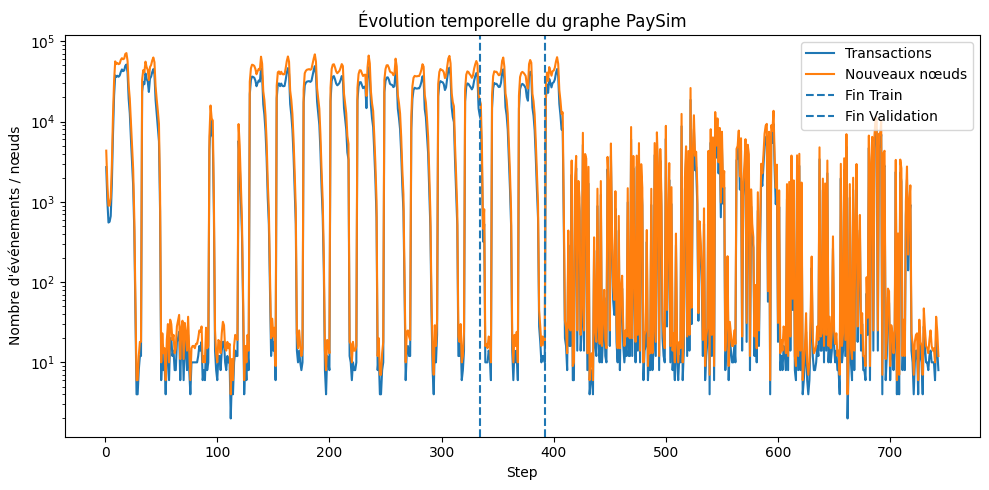

In [213]:
# Visualiser l'évolution temporelle
plt.figure(figsize=(10, 5))

plt.plot(
    step_values,
    edges_per_step,
    label="Transactions"
)

plt.plot(
    step_values,
    new_nodes_by_step,
    label="Nouveaux nœuds"
)

plt.axvline(
    334,
    linestyle="--",
    label="Fin Train"
)

plt.axvline(
    392,
    linestyle="--",
    label="Fin Validation"
)

plt.yscale("log")

plt.xlabel("Step")
plt.ylabel("Nombre d'événements / nœuds")
plt.title(
    "Évolution temporelle du graphe PaySim"
)

plt.legend()
plt.tight_layout()
plt.show()

In [214]:
# Définir les positions de fin d'historique
history_end_index = (
    history_edges_before.copy()
)

event_based_protocol = {
    "canonical_storage": "event-based",
    "events_sorted_by_step": bool(
        np.all(
            edge_steps[1:]
            >= edge_steps[:-1]
        )
    ),
    "history_is_contiguous_prefix": True,
    "same_step_excluded_from_history": True,
    "cumulative_snapshots_materialized": False,
    "snapshots_derivable_on_demand": True,
    "split_boundaries_preserved": True
}

event_based_protocol

{'canonical_storage': 'event-based',
 'events_sorted_by_step': True,
 'history_is_contiguous_prefix': True,
 'same_step_excluded_from_history': True,
 'cumulative_snapshots_materialized': False,
 'snapshots_derivable_on_demand': True,
 'split_boundaries_preserved': True}

In [215]:
# Vérifier plusieurs contextes rolling
audit_steps = [
    1,
    2,
    334,
    335,
    392,
    393,
    743
]

rolling_context_records = []

for step in audit_steps:
    idx = step - 1

    history_end = int(
        history_end_index[idx]
    )

    query_start = int(
        step_start_positions[idx]
    )

    query_end = int(
        step_end_positions[idx]
    )

    rolling_context_records.append({
        "step": step,
        "history_edges": history_end,
        "query_edges": query_end - query_start,
        "history_end_equals_query_start": (
            history_end == query_start
        )
    })

rolling_context_audit = pd.DataFrame(
    rolling_context_records
)

rolling_context_audit

,step,history_edges,query_edges,history_end_equals_query_start
0,1,0,2708,True
1,2,2708,1014,True
2,334,4759371,12016,True
3,335,4771387,10456,True
4,392,5563783,10,True
5,393,5563793,19269,True
6,743,6362612,8,True


In [216]:
# Vérifier les slices rolling
rolling_prefix_ok = bool(
    rolling_context_audit[
        "history_end_equals_query_start"
    ].all()
)

print(
    "Préfixes rolling cohérents :",
    rolling_prefix_ok
)

assert rolling_prefix_ok

print(
    "Représentation event-based rolling : OK"
)

Préfixes rolling cohérents : True
Représentation event-based rolling : OK


In [217]:
# Vérifier la cohérence temporelle
temporal_checks = {
    "743_steps": (
        len(edges_per_step) == 743
    ),
    "edges_sum": (
        int(edges_per_step.sum())
        == n_transactions
    ),
    "frauds_sum": (
        int(frauds_per_step.sum())
        == int(edge_labels.sum())
    ),
    "nodes_sum": (
        int(new_nodes_by_step.sum())
        == n_total_nodes
    ),
    "train_boundary_edges": (
        history_step_335_edges
        == train_edges
    ),
    "validation_boundary_edges": (
        history_step_393_edges
        == train_edges + val_edges
    ),
    "chronological_events": (
        event_based_protocol[
            "events_sorted_by_step"
        ]
    ),
    "rolling_prefix_valid": (
        rolling_prefix_ok
    ),
    "disjoint_edges_complete": (
        disjoint_snapshot_edges
        == n_transactions
    )
}

for check, value in temporal_checks.items():
    print(
        f"{check:32s} : {value}"
    )

assert all(
    temporal_checks.values()
)

print(
    "\nTemporal graph evolution validated."
)

743_steps                        : True
edges_sum                        : True
frauds_sum                       : True
nodes_sum                        : True
train_boundary_edges             : True
validation_boundary_edges        : True
chronological_events             : True
rolling_prefix_valid             : True
disjoint_edges_complete          : True

Temporal graph evolution validated.


In [218]:
print("===== TEMPORAL GRAPH =====")
print(
    "Steps :",
    len(edges_per_step)
)
print(
    "Transactions :",
    f"{n_transactions:,}"
)
print(
    "Nodes :",
    f"{n_total_nodes:,}"
)

print("\n===== STEP LOAD =====")
print(
    split_temporal_summary.to_string(
        index=False
    )
)

print("\n===== BOUNDARIES =====")
print(
    temporal_boundaries.to_string(
        index=False
    )
)

print("\n===== SNAPSHOT STORAGE =====")
print(
    f"Event-based src/dst : "
    f"{event_edge_mb:.2f} MB"
)
print(
    f"Cumulative naive snapshots : "
    f"{cumulative_snapshot_gb:.2f} GB"
)
print(
    f"Duplication factor : "
    f"{duplication_factor:.2f}x"
)

print("\n===== GRANULARITY =====")
print(
    granularity_summary.to_string(
        index=False
    )
)

print("\n===== EVENT-BASED PROTOCOL =====")
for key, value in (
    event_based_protocol.items()
):
    print(
        f"{key:35s} : {value}"
    )

if psutil_available:
    print(
        f"\nRAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

print(
    "\nTemporal graph evolution and snapshot granularity analysis completed."
)

===== TEMPORAL GRAPH =====
Steps : 743
Transactions : 6,362,620
Nodes : 9,073,900

===== STEP LOAD =====
     split  steps  edges_total  edges_min  edges_median  edges_p95  edges_max  active_nodes_median  active_nodes_max  new_nodes_total  new_nodes_median  fraud_steps
     Train    334      4771387          2        6593.5   40623.05      51352              12430.5             95589          6800639           10594.0          334
Validation     58       792406          6        9223.5   38143.45      44787              18427.0             88544          1130324           14509.0           57
      Test    351       798827          2          22.0    8494.50      45155                 44.0             89476          1142937              35.0          350

===== BOUNDARIES =====
 step      split  edges  active_nodes  new_nodes  history_edges_before  history_nodes_before  cumulative_edges_after  cumulative_nodes_after
    1      Train   2708          4341       4341                     0

In [219]:
print("===== TEMPORAL GRAPH =====")
print(
    "Steps :",
    len(edges_per_step)
)
print(
    "Transactions :",
    f"{n_transactions:,}"
)
print(
    "Nodes :",
    f"{n_total_nodes:,}"
)

print("\n===== STEP LOAD =====")
print(
    split_temporal_summary.to_string(
        index=False
    )
)

print("\n===== BOUNDARIES =====")
print(
    temporal_boundaries.to_string(
        index=False
    )
)

print("\n===== SNAPSHOT STORAGE =====")
print(
    f"Event-based src/dst : "
    f"{event_edge_mb:.2f} MB"
)
print(
    f"Cumulative naive snapshots : "
    f"{cumulative_snapshot_gb:.2f} GB"
)
print(
    f"Duplication factor : "
    f"{duplication_factor:.2f}x"
)

print("\n===== GRANULARITY =====")
print(
    granularity_summary.to_string(
        index=False
    )
)

print("\n===== EVENT-BASED PROTOCOL =====")
for key, value in (
    event_based_protocol.items()
):
    print(
        f"{key:35s} : {value}"
    )

if psutil_available:
    print(
        f"\nRAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

print(
    "\nTemporal graph evolution and snapshot granularity analysis completed."
)

===== TEMPORAL GRAPH =====
Steps : 743
Transactions : 6,362,620
Nodes : 9,073,900

===== STEP LOAD =====
     split  steps  edges_total  edges_min  edges_median  edges_p95  edges_max  active_nodes_median  active_nodes_max  new_nodes_total  new_nodes_median  fraud_steps
     Train    334      4771387          2        6593.5   40623.05      51352              12430.5             95589          6800639           10594.0          334
Validation     58       792406          6        9223.5   38143.45      44787              18427.0             88544          1130324           14509.0           57
      Test    351       798827          2          22.0    8494.50      45155                 44.0             89476          1142937              35.0          350

===== BOUNDARIES =====
 step      split  edges  active_nodes  new_nodes  history_edges_before  history_nodes_before  cumulative_edges_after  cumulative_nodes_after
    1      Train   2708          4341       4341                     0

In [220]:
# Libérer les objets techniques
objects_to_remove = [
    "step_start_positions",
    "step_end_positions"
]

for name in objects_to_remove:
    globals().pop(
        name,
        None
    )

gc.collect()

if psutil_available:
    print(
        f"RAM disponible après nettoyage : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM disponible après nettoyage : 3.11 GB


### Section 12 - Key Findings

L'analyse temporelle confirme que la représentation événementielle constitue le format le plus adapté au graphe PaySim.

Les 6 362 620 transactions sont réparties sur 743 steps avec une très forte variabilité de charge. Le nombre de transactions par step varie de 2 à 51 352. Cette variabilité diffère également fortement selon les splits : la médiane atteint environ 6 594 transactions en Train et 9 224 en Validation, mais seulement 22 en Test. Le drift temporel observé précédemment ne concerne donc pas uniquement le taux de fraude ; il affecte également la densité événementielle du réseau.

L'arrivée de nouveaux nœuds suit fortement cette activité transactionnelle. Elle varie de 4 à 71 291 nouveaux comptes par step et reste présente jusqu'au dernier step, confirmant le caractère continuellement inductif du problème.

Le protocole rolling a été validé aux frontières des splits. Avant le step 335, l'historique contient exactement les 4 771 387 transactions Train et 6 800 639 nœuds observés. Avant le step 393, il contient 5 563 793 transactions et 7 930 963 nœuds. Grâce à l'ordre chronologique du dataset, \(G_{<t}\) correspond à un préfixe contigu des tableaux d'événements.

La matérialisation de snapshots cumulatifs est exclue pour des raisons de mémoire. Les tableaux `src` et `dst` événementiels occupent environ 48,54 MB, tandis que sauvegarder indépendamment tous les contextes \(G_{<t}\) nécessiterait environ 3,18 milliards de copies d'arêtes, soit approximativement 23,68 GB rien que pour leurs extrémités. Le facteur de duplication atteindrait environ 499,6.

Les snapshots disjoints par step ne dupliquent pas les arêtes, mais fragmenteraient les mêmes 6,36 millions d'événements en 743 objets sans faciliter l'accès au contexte historique. Ils sont donc mieux considérés comme des vues dérivées que comme le format de stockage principal.

L'agrégation en fenêtres de 6, 12 ou 24 steps réduit le nombre de snapshots mais augmente fortement leur taille, jusqu'à plus de 574 000 transactions pour certaines fenêtres de 24 steps. Une telle agrégation ferait également perdre une partie de l'ordre causal entre les différents steps contenus dans la fenêtre.

Le **step natif est donc conservé comme granularité temporelle canonique**, particulièrement pour le futur Dynamic Graph Learning. Les fenêtres multi-steps pourront être testées ultérieurement comme choix expérimental, mais elles ne remplaceront pas les timestamps originaux.

Le format canonique retenu est ainsi un **temporal interaction graph event-based**, dans lequel chaque transaction est stockée une seule fois sous la forme `(src, dst, step, edge_features, label)`. Les snapshots statiques ou historiques pourront être dérivés à la demande.

Pour toute prédiction au step \(t\), la topologie disponible restera strictement \(G_{<t}\). Les arêtes du step courant ne seront intégrées au graphe qu'après leur prédiction, conformément au protocole rolling défini précédemment.

## 13. Graph Feature Sets and Model Input Audit

Cette section définit les entrées autorisées pour les futurs modèles Graph Neural Networks.

Le graphe possède trois sources d'information distinctes :

1. la topologie historique \(G_{<t}\) ;
2. les attributs de la transaction courante à prédire ;
3. certaines informations historiques causales déjà calculées pendant le Feature Engineering.

Les identifiants de nœuds restent exclusivement administratifs. Les propriétés calculées sur le graphe final, telles que les degrés globaux, les composantes, les rôles finaux ou les statistiques utilisant des arêtes futures, sont interdites comme features prédictives.

Les listes officielles Graph Core, Graph Full et PaySim-sensitive sont récupérées depuis `feature_engineering_metadata.json`.

L'objectif est également de définir une politique reproductible pour les variables catégorielles, les valeurs manquantes et les nouveaux nœuds.

In [221]:
# Récupérer les listes officielles
feature_sets = metadata["feature_sets"]

graph_core = feature_sets["graph_core"]
graph_full = feature_sets["graph_full"]
graph_sensitive = feature_sets["graph_sensitive"]

graph_core_edge = feature_sets[
    "graph_core_edge"
]

graph_node_history = feature_sets[
    "graph_node_history"
]

categorical_features = feature_sets[
    "categorical"
]

print("Graph Core :", len(graph_core))
print("Graph Full :", len(graph_full))
print("Graph Sensitive :", len(graph_sensitive))
print("Graph Core Edge :", len(graph_core_edge))
print("Graph Node History :", len(graph_node_history))
print("Categorical :", categorical_features)

Graph Core : 15
Graph Full : 24
Graph Sensitive : 9
Graph Core Edge : 9
Graph Node History : 6
Categorical : ['type']


In [222]:
# Vérifier la décomposition du Core
core_edge_set = set(
    graph_core_edge
)

node_history_set = set(
    graph_node_history
)

core_set = set(
    graph_core
)

full_set = set(
    graph_full
)

sensitive_set = set(
    graph_sensitive
)

core_decomposition_ok = (
    core_edge_set
    | node_history_set
) == core_set

core_groups_disjoint = (
    core_edge_set
    .isdisjoint(node_history_set)
)

full_core_difference = [
    feature
    for feature in graph_full
    if feature not in core_set
]

sensitive_matches_difference = (
    set(full_core_difference)
    == sensitive_set
)

print(
    "Core Edge ∪ Node History = Core :",
    core_decomposition_ok
)

print(
    "Core Edge ∩ Node History vide :",
    core_groups_disjoint
)

print(
    "Full - Core = Sensitive :",
    sensitive_matches_difference
)

print("\nGraph Core Edge :")
print(graph_core_edge)

print("\nGraph Node History :")
print(graph_node_history)

print("\nFull - Core :")
print(full_core_difference)

assert core_decomposition_ok
assert core_groups_disjoint
assert sensitive_matches_difference

print(
    "\nDécomposition des feature sets : OK"
)

Core Edge ∪ Node History = Core : True
Core Edge ∩ Node History vide : True
Full - Core = Sensitive : True

Graph Core Edge :
['amount', 'log_amount', 'type', 'origin_balance_change', 'destination_balance_change', 'origin_zero_before', 'origin_zero_after', 'destination_zero_before', 'destination_zero_after']

Graph Node History :
['orig_prev_transactions', 'dest_prev_transactions', 'orig_prev_volume', 'dest_prev_volume', 'orig_time_since_last', 'dest_time_since_last']

Full - Core :
['amount_to_oldbalance_ratio', 'origin_balance_residual', 'destination_balance_residual', 'origin_emptied', 'amount_equals_oldbalance', 'cycle_sin', 'cycle_cos', 'simulated_day', 'dest_active_last_24']

Décomposition des feature sets : OK


In [223]:
# Auditer les features Graph Full
feature_audit_records = []

for feature in graph_full:
    series = df_graph[feature]

    missing_count = int(
        series.isna().sum()
    )

    if pd.api.types.is_numeric_dtype(
        series.dtype
    ):
        values = series.to_numpy(
            copy=False
        )

        inf_count = int(
            np.isinf(values).sum()
        )

        feature_min = (
            float(np.nanmin(values))
            if missing_count < len(values)
            else np.nan
        )

        feature_max = (
            float(np.nanmax(values))
            if missing_count < len(values)
            else np.nan
        )
    else:
        inf_count = 0
        feature_min = np.nan
        feature_max = np.nan

    feature_audit_records.append({
        "feature": feature,
        "dtype": str(series.dtype),
        "missing_count": missing_count,
        "missing_pct": (
            missing_count
            / n_transactions
            * 100
        ),
        "inf_count": inf_count,
        "min": feature_min,
        "max": feature_max
    })

feature_input_audit = pd.DataFrame(
    feature_audit_records
)

feature_input_audit

,feature,dtype,missing_count,missing_pct,inf_count,min,max
0,amount,float64,0,0.000000,0,0.000000e+00,9.244552e+07
1,log_amount,float32,0,0.000000,0,0.000000e+00,1.834213e+01
2,type,category,0,0.000000,0,NaN,NaN
3,origin_balance_change,float32,0,0.000000,0,-1.915268e+06,1.000000e+07
4,destination_balance_change,float32,0,0.000000,0,-1.306083e+07,1.056878e+08
5,origin_zero_before,int8,0,0.000000,0,0.000000e+00,1.000000e+00
6,origin_zero_after,int8,0,0.000000,0,0.000000e+00,1.000000e+00
7,destination_zero_before,int8,0,0.000000,0,0.000000e+00,1.000000e+00
8,destination_zero_after,int8,0,0.000000,0,0.000000e+00,1.000000e+00
9,orig_prev_transactions,int16,0,0.000000,0,0.000000e+00,2.000000e+00


In [224]:
# Identifier les features particulières
features_with_missing = (
    feature_input_audit[
        feature_input_audit[
            "missing_count"
        ] > 0
    ]
    .copy()
)

features_with_inf = (
    feature_input_audit[
        feature_input_audit[
            "inf_count"
        ] > 0
    ]
    .copy()
)

float64_features = (
    feature_input_audit[
        feature_input_audit[
            "dtype"
        ] == "float64"
    ]
    ["feature"]
    .tolist()
)

print(
    "Features avec NaN :",
    len(features_with_missing)
)

print(
    "Features avec Inf :",
    len(features_with_inf)
)

print(
    "Features float64 :",
    float64_features
)

print("\nFeatures avec NaN :")
print(
    features_with_missing[
        [
            "feature",
            "dtype",
            "missing_count",
            "missing_pct"
        ]
    ].to_string(index=False)
)

Features avec NaN : 3
Features avec Inf : 0
Features float64 : ['amount']

Features avec NaN :
                   feature   dtype  missing_count  missing_pct
      orig_time_since_last float32        6353354    99.854368
      dest_time_since_last float32        2769903    43.534000
amount_to_oldbalance_ratio float32        2102449    33.043762


In [225]:
# Vérifier l'absence d'infini
assert features_with_inf.empty

print(
    "\nAucune valeur infinie : OK"
)


Aucune valeur infinie : OK


In [226]:
# Récupérer la sémantique des NaN
missing_semantics = metadata[
    "missing_value_semantics"
]

missing_semantic_records = []

for feature in (
    features_with_missing["feature"]
):
    missing_semantic_records.append({
        "feature": feature,
        "missing_pct": float(
            feature_input_audit.loc[
                feature_input_audit[
                    "feature"
                ] == feature,
                "missing_pct"
            ].iloc[0]
        ),
        "semantic": (
            missing_semantics.get(
                feature,
                "Not documented"
            )
        )
    })

missing_semantics_graph = pd.DataFrame(
    missing_semantic_records
)

missing_semantics_graph

,feature,missing_pct,semantic
0,orig_time_since_last,99.854368,No previous origin transaction
1,dest_time_since_last,43.534000,No previous destination transaction
2,amount_to_oldbalance_ratio,33.043762,oldbalanceOrg == 0


In [227]:
# Vérifier la documentation des NaN
undocumented_missing = (
    missing_semantics_graph[
        missing_semantics_graph[
            "semantic"
        ] == "Not documented"
    ]
)

print(
    "NaN non documentés :",
    len(undocumented_missing)
)

assert undocumented_missing.empty

print(
    "Sémantique des valeurs manquantes : OK"
)

NaN non documentés : 0
Sémantique des valeurs manquantes : OK


In [228]:
# Mesurer les NaN par split
missing_split_records = []

split_slices = {
    "Train": slice(
        0,
        train_end
    ),
    "Validation": val_slice,
    "Test": test_slice
}

for feature in (
    features_with_missing["feature"]
):
    values = df_graph[
        feature
    ]

    for split_name, split_slice in (
        split_slices.items()
    ):
        split_values = values.iloc[
            split_slice
        ]

        missing_count = int(
            split_values.isna().sum()
        )

        missing_split_records.append({
            "feature": feature,
            "split": split_name,
            "missing_count": missing_count,
            "missing_pct": (
                missing_count
                / len(split_values)
                * 100
            )
        })

missing_by_split = pd.DataFrame(
    missing_split_records
)

missing_by_split

,feature,split,missing_count,missing_pct
0,orig_time_since_last,Train,4766097,99.889131
1,orig_time_since_last,Validation,790568,99.768048
2,orig_time_since_last,Test,796689,99.732358
3,dest_time_since_last,Train,2081472,43.624045
4,dest_time_since_last,Validation,341191,43.057599
5,dest_time_since_last,Test,347240,43.468736
6,amount_to_oldbalance_ratio,Train,1587080,33.262445
7,amount_to_oldbalance_ratio,Validation,264774,33.413932
8,amount_to_oldbalance_ratio,Test,250595,31.370372


In [229]:
# Définir les indicateurs de missingness
core_missing_features = [
    feature
    for feature in graph_core
    if feature in (
        features_with_missing[
            "feature"
        ].tolist()
    )
]

full_missing_features = (
    features_with_missing[
        "feature"
    ].tolist()
)

core_missing_indicators = [
    f"{feature}_missing"
    for feature in core_missing_features
]

full_missing_indicators = [
    f"{feature}_missing"
    for feature in full_missing_features
]

missing_input_policy = {
    "imputation_value": 0.0,
    "add_missing_indicator": True,
    "core_missing_features":
        core_missing_features,
    "core_missing_indicators":
        core_missing_indicators,
    "full_missing_features":
        full_missing_features,
    "full_missing_indicators":
        full_missing_indicators,
    "imputation_stage":
        "model preprocessing / batch construction"
}

missing_input_policy

{'imputation_value': 0.0,
 'add_missing_indicator': True,
 'core_missing_features': ['orig_time_since_last', 'dest_time_since_last'],
 'core_missing_indicators': ['orig_time_since_last_missing',
  'dest_time_since_last_missing'],
 'full_missing_features': ['orig_time_since_last',
  'dest_time_since_last',
  'amount_to_oldbalance_ratio'],
 'full_missing_indicators': ['orig_time_since_last_missing',
  'dest_time_since_last_missing',
  'amount_to_oldbalance_ratio_missing'],
 'imputation_stage': 'model preprocessing / batch construction'}

In [230]:
# Auditer la variable type
if isinstance(
    df_graph["type"].dtype,
    pd.CategoricalDtype
):
    type_categories = (
        df_graph["type"]
        .cat.categories
        .tolist()
    )
else:
    type_categories = sorted(
        df_graph["type"]
        .dropna()
        .unique()
        .tolist()
    )

type_mapping = {
    category: code
    for code, category
    in enumerate(type_categories)
}

print(
    "Catégories type :",
    type_categories
)

print(
    "Nombre :",
    len(type_categories)
)

print(
    "Mapping proposé :",
    type_mapping
)

assert len(type_categories) == 5

Catégories type : ['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER']
Nombre : 5
Mapping proposé : {'CASH_IN': 0, 'CASH_OUT': 1, 'DEBIT': 2, 'PAYMENT': 3, 'TRANSFER': 4}


In [231]:
# Définir la politique catégorielle
categorical_input_policy = {
    "feature": "type",
    "storage": "integer category code",
    "recommended_dtype": "int8",
    "categories": type_categories,
    "mapping": type_mapping,
    "baseline_model_encoding":
        "one-hot on batch",
    "optional_dynamic_encoding":
        "small embedding",
    "store_global_one_hot_matrix":
        False
}

categorical_input_policy

{'feature': 'type',
 'storage': 'integer category code',
 'recommended_dtype': 'int8',
 'categories': ['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER'],
 'mapping': {'CASH_IN': 0,
  'CASH_OUT': 1,
  'DEBIT': 2,
  'PAYMENT': 3,
  'TRANSFER': 4},
 'baseline_model_encoding': 'one-hot on batch',
 'optional_dynamic_encoding': 'small embedding',
 'store_global_one_hot_matrix': False}

In [232]:
# Définir les informations non prédictives
forbidden_model_inputs = {
    "isFraud",
    "split",
    "step",
    "nameOrig",
    "nameDest",
    "src",
    "dst",
    "src_id",
    "dst_id",
    "node_id",
    "raw_id",
    "first_seen_step",
    "last_seen_step",
    "first_split_code",
    "node_role_code",
    "component_id",
    "in_degree",
    "out_degree",
    "total_degree"
}

forbidden_core = sorted(
    set(graph_core)
    &
    forbidden_model_inputs
)

forbidden_full = sorted(
    set(graph_full)
    &
    forbidden_model_inputs
)

print(
    "Features interdites Graph Core :",
    forbidden_core
)

print(
    "Features interdites Graph Full :",
    forbidden_full
)

assert not forbidden_core
assert not forbidden_full

print(
    "\nFeature leakage audit : OK"
)

Features interdites Graph Core : []
Features interdites Graph Full : []

Feature leakage audit : OK


In [233]:
# Définir les variantes GNN
gnn_input_variants = pd.DataFrame([
    {
        "variant": "GNN Core Edge",
        "query_features":
            len(graph_core_edge),
        "uses_precomputed_history":
            False,
        "uses_topology": True,
        "uses_sensitive": False,
        "purpose":
            "Isolate explicit topology value"
    },
    {
        "variant": "GNN Core",
        "query_features":
            len(graph_core),
        "uses_precomputed_history":
            True,
        "uses_topology": True,
        "uses_sensitive": False,
        "purpose":
            "Main prudent GNN baseline"
    },
    {
        "variant": "GNN Full",
        "query_features":
            len(graph_full),
        "uses_precomputed_history":
            True,
        "uses_topology": True,
        "uses_sensitive": True,
        "purpose":
            "PaySim-sensitive secondary experiment"
    }
])

gnn_input_variants

,variant,query_features,uses_precomputed_history,uses_topology,uses_sensitive,purpose
0,GNN Core Edge,9,False,True,False,Isolate explicit topology value
1,GNN Core,15,True,True,False,Main prudent GNN baseline
2,GNN Full,24,True,True,True,PaySim-sensitive secondary experiment


In [234]:
# Estimer les dimensions des entrées
n_type_categories = len(
    type_categories
)

variant_specs = [
    (
        "GNN Core Edge",
        graph_core_edge,
        []
    ),
    (
        "GNN Core",
        graph_core,
        core_missing_indicators
    ),
    (
        "GNN Full",
        graph_full,
        full_missing_indicators
    )
]

model_dimension_records = []

for (
    variant,
    features,
    missing_indicators
) in variant_specs:

    numeric_count = sum(
        feature != "type"
        for feature in features
    )

    float_dimension = (
        numeric_count
        + n_type_categories
        + len(missing_indicators)
    )

    full_matrix_mb = (
        n_transactions
        * float_dimension
        * np.dtype(np.float32).itemsize
        / 1024**2
    )

    model_dimension_records.append({
        "variant": variant,
        "numeric_features":
            numeric_count,
        "type_one_hot_dim":
            n_type_categories,
        "missing_indicators":
            len(missing_indicators),
        "model_float_dim":
            float_dimension,
        "dense_full_matrix_mb":
            full_matrix_mb
    })

model_input_dimension_summary = pd.DataFrame(
    model_dimension_records
)

model_input_dimension_summary

,variant,numeric_features,type_one_hot_dim,missing_indicators,model_float_dim,dense_full_matrix_mb
0,GNN Core Edge,8,5,0,13,315.529099
1,GNN Core,14,5,2,21,509.700851
2,GNN Full,23,5,3,31,752.415543


In [235]:
# Estimer le coût des embeddings d'identité
embedding_dimensions = [
    16,
    32,
    64
]

identity_embedding_records = []

for embedding_dim in (
    embedding_dimensions
):
    memory_gb = (
        n_total_nodes
        * embedding_dim
        * np.dtype(np.float32).itemsize
        / 1024**3
    )

    identity_embedding_records.append({
        "embedding_dim":
            embedding_dim,
        "nodes":
            n_total_nodes,
        "float32_memory_gb":
            memory_gb
    })

identity_embedding_memory = pd.DataFrame(
    identity_embedding_records
)

identity_embedding_memory

,embedding_dim,nodes,float32_memory_gb
0,16,9073900,0.540847
1,32,9073900,1.081693
2,64,9073900,2.163386


In [236]:
# Définir la politique des nœuds
node_input_policy = {
    "node_id":
        "administrative index only",
    "raw_id":
        "never predictive",
    "raw_id_prefix":
        "analysis only, not Core model input",
    "global_node_role":
        "audit only",
    "global_degree":
        "audit only",
    "component_membership":
        "audit only",
    "identity_embedding_default":
        False,
    "static_global_node_matrix":
        False,
    "historical_representation":
        "built causally from G_<t",
    "cold_start_initial_state":
        "shared non-ID-based state",
    "exact_cold_start_mechanism":
        "to be selected in GNN notebook"
}

node_input_policy

{'node_id': 'administrative index only',
 'raw_id': 'never predictive',
 'raw_id_prefix': 'analysis only, not Core model input',
 'global_node_role': 'audit only',
 'global_degree': 'audit only',
 'component_membership': 'audit only',
 'identity_embedding_default': False,
 'static_global_node_matrix': False,
 'historical_representation': 'built causally from G_<t',
 'cold_start_initial_state': 'shared non-ID-based state',
 'exact_cold_start_mechanism': 'to be selected in GNN notebook'}

In [237]:
# Définir le schéma logique des entrées
graph_model_input_policy = {
    "task":
        "edge classification",
    "historical_topology":
        "G_<t only",
    "query_edge":
        "step == t",
    "query_edge_in_adjacency_before_prediction":
        False,
    "node_ids":
        "indexing only",
    "current_edge_features":
        graph_core_edge,
    "causal_history_features":
        graph_node_history,
    "core_features":
        graph_core,
    "full_features":
        graph_full,
    "sensitive_features":
        graph_sensitive,
    "categorical_policy":
        categorical_input_policy,
    "missing_policy":
        missing_input_policy,
    "global_graph_statistics_as_features":
        False,
    "dense_global_feature_matrix_required":
        False
}

print(
    "Task :",
    graph_model_input_policy["task"]
)

print(
    "Topology :",
    graph_model_input_policy[
        "historical_topology"
    ]
)

print(
    "Current edge features :",
    len(graph_core_edge)
)

print(
    "Historical context features :",
    len(graph_node_history)
)

print(
    "Graph Core :",
    len(graph_core)
)

print(
    "Graph Full :",
    len(graph_full)
)

print(
    "Sensitive :",
    len(graph_sensitive)
)

Task : edge classification
Topology : G_<t only
Current edge features : 9
Historical context features : 6
Graph Core : 15
Graph Full : 24
Sensitive : 9


In [238]:
# Vérifier la politique finale
feature_input_checks = {
    "core_count_15":
        len(graph_core) == 15,
    "full_count_24":
        len(graph_full) == 24,
    "sensitive_count_9":
        len(graph_sensitive) == 9,
    "core_decomposition":
        core_decomposition_ok,
    "core_groups_disjoint":
        core_groups_disjoint,
    "sensitive_difference":
        sensitive_matches_difference,
    "no_core_forbidden":
        len(forbidden_core) == 0,
    "no_full_forbidden":
        len(forbidden_full) == 0,
    "no_infinite_values":
        features_with_inf.empty,
    "missing_semantics_documented":
        undocumented_missing.empty,
    "type_has_5_categories":
        len(type_categories) == 5,
    "identity_embedding_disabled":
        node_input_policy[
            "identity_embedding_default"
        ] is False,
    "global_stats_disabled":
        graph_model_input_policy[
            "global_graph_statistics_as_features"
        ] is False
}

for check, value in (
    feature_input_checks.items()
):
    print(
        f"{check:34s} : {value}"
    )

assert all(
    feature_input_checks.values()
)

print(
    "\nGraph model input audit validated."
)

core_count_15                      : True
full_count_24                      : True
sensitive_count_9                  : True
core_decomposition                 : True
core_groups_disjoint               : True
sensitive_difference               : True
no_core_forbidden                  : True
no_full_forbidden                  : True
no_infinite_values                 : True
missing_semantics_documented       : True
type_has_5_categories              : True
identity_embedding_disabled        : True
global_stats_disabled              : True

Graph model input audit validated.


In [239]:
print("===== GRAPH FEATURE SETS =====")
print(
    "Graph Core Edge :",
    len(graph_core_edge)
)
print(
    graph_core_edge
)

print(
    "\nGraph Node History :",
    len(graph_node_history)
)
print(
    graph_node_history
)

print(
    "\nGraph Core :",
    len(graph_core)
)

print(
    "Graph Full :",
    len(graph_full)
)

print(
    "Graph Sensitive :",
    len(graph_sensitive)
)

print("\n===== MISSING VALUES =====")
print(
    missing_semantics_graph.to_string(
        index=False
    )
)

print("\n===== MISSING BY SPLIT =====")
print(
    missing_by_split.to_string(
        index=False
    )
)

print("\n===== GNN VARIANTS =====")
print(
    gnn_input_variants.to_string(
        index=False
    )
)

print("\n===== MODEL DIMENSIONS =====")
print(
    model_input_dimension_summary.to_string(
        index=False
    )
)

print("\n===== IDENTITY EMBEDDING MEMORY =====")
print(
    identity_embedding_memory.to_string(
        index=False
    )
)

print("\n===== NODE POLICY =====")
for key, value in (
    node_input_policy.items()
):
    print(
        f"{key:30s} : {value}"
    )

if psutil_available:
    print(
        f"\nRAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

print(
    "\nGraph feature sets and model input audit completed."
)

===== GRAPH FEATURE SETS =====
Graph Core Edge : 9
['amount', 'log_amount', 'type', 'origin_balance_change', 'destination_balance_change', 'origin_zero_before', 'origin_zero_after', 'destination_zero_before', 'destination_zero_after']

Graph Node History : 6
['orig_prev_transactions', 'dest_prev_transactions', 'orig_prev_volume', 'dest_prev_volume', 'orig_time_since_last', 'dest_time_since_last']

Graph Core : 15
Graph Full : 24
Graph Sensitive : 9

===== MISSING VALUES =====
                   feature  missing_pct                            semantic
      orig_time_since_last    99.854368      No previous origin transaction
      dest_time_since_last    43.534000 No previous destination transaction
amount_to_oldbalance_ratio    33.043762                  oldbalanceOrg == 0

===== MISSING BY SPLIT =====
                   feature      split  missing_count  missing_pct
      orig_time_since_last      Train        4766097    99.889131
      orig_time_since_last Validation         790568 

In [240]:
# Libérer les objets temporaires
objects_to_remove = [
    "feature_audit_records",
    "missing_split_records",
    "model_dimension_records",
    "identity_embedding_records"
]

for name in objects_to_remove:
    globals().pop(
        name,
        None
    )

gc.collect()

if psutil_available:
    print(
        f"RAM disponible après nettoyage : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM disponible après nettoyage : 4.36 GB


### Section 13 - Key Findings

L'audit des entrées confirme une séparation propre entre les informations transactionnelles, les historiques causaux et les variables spécifiques au simulateur.

Le jeu `Graph Core` contient 15 features et se décompose exactement en **9 attributs de transaction courante (`Graph Core Edge`)** et **6 variables historiques causales (`Graph Node History`)**, sans chevauchement. Le jeu `Graph Full` contient 24 variables et sa différence avec `Graph Core` correspond exactement aux 9 features identifiées comme PaySim-sensitive.

Cette décomposition permettra trois expériences distinctes dans le futur notebook GNN : `GNN Core Edge`, destiné à isoler autant que possible la valeur de la topologie explicite ; `GNN Core`, qui constituera la baseline GNN prudente principale ; et `GNN Full`, conservé comme expérience secondaire sensible aux particularités de PaySim.

Trois features présentent des valeurs manquantes : `orig_time_since_last` (99,85 %), `dest_time_since_last` (43,53 %) et `amount_to_oldbalance_ratio` (33,04 %). Ces valeurs sont sémantiquement définies et ne correspondent pas à des données corrompues. Les deux premières indiquent l'absence d'historique transactionnel de l'endpoint concerné, tandis que la troisième correspond à `oldbalanceOrg == 0`.

La missingness des historiques est très cohérente avec l'analyse structurelle précédente. L'absence presque systématique de `orig_time_since_last` reflète le cold-start massif côté source, tandis que la proportion de valeurs manquantes de `dest_time_since_last` est proche de la proportion de nouvelles destinations observée en rolling.

Pour éviter toute ambiguïté, les valeurs manquantes seront imputées à zéro uniquement lors du preprocessing ou de la construction des batches, accompagnées d'un indicateur binaire de missingness. Les indicateurs relatifs aux historiques causaux appartiendront au Core, tandis que celui associé à `amount_to_oldbalance_ratio` restera exclusivement dans la variante Full.

Aucune valeur infinie n'est présente. `amount` est la seule feature encore stockée en `float64` dans le dataset Graph-ready ; elle sera convertie en `float32` pour les tenseurs GNN sans modifier l'artefact source.

La variable catégorielle `type` possède cinq modalités. Elle sera stockée sous forme de code entier `int8` et encodée à la volée, avec un One-Hot Encoding à cinq dimensions comme choix initial pour le baseline GNN.

Les dimensions finales après preprocessing restent compactes : environ 13 dimensions pour `GNN Core Edge`, 21 pour `GNN Core` et 31 pour `GNN Full`. Il n'est donc pas nécessaire de matérialiser une matrice globale dense ; les représentations pourront être construites par batch.

Les identifiants de comptes et de nœuds restent exclusivement administratifs. Les identifiants bruts, `node_id`, les préfixes C/M, les rôles globaux, les degrés calculés sur le graphe final et les composantes connexes sont exclus des features prédictives.

Les embeddings appris directement par identité de nœud ne seront pas utilisés par défaut. Outre leur coût mémoire important sur plus de 9 millions de nœuds, ils seraient mal adaptés au caractère fortement inductif de PaySim, où presque toutes les sources futures sont nouvelles au moment de leur transaction.

Les nouveaux nœuds devront donc être initialisés avec une représentation partagée et indépendante de leur identité. Le mécanisme exact sera choisi dans le notebook GNN.

Le schéma logique retenu pour une prédiction au step \(t\) reste ainsi : topologie historique \(G_{<t}\), features de la transaction courante, contexte historique causal éventuellement disponible, et aucun signal provenant de la topologie future ou des propriétés globales finales du graphe.

## 14. Memory-Efficient Graph Artifact Design

Les analyses précédentes ont défini la représentation, le protocole causal et les entrées des futurs modèles. Cette section conçoit maintenant les artefacts graph à exporter sans encore écrire de données sur disque.

L'objectif est de minimiser la duplication tout en permettant un chargement efficace dans les futurs notebooks GNN.

Le fichier `paysim_graph_ready.parquet` reste la source officielle des attributs transactionnels. Les nouveaux artefacts doivent donc principalement fournir :

- le mapping compact des nœuds ;
- les métadonnées temporelles nécessaires au cold-start ;
- les extrémités numériques des événements ;
- les timestamps et labels ;
- les offsets permettant de reconstruire efficacement \(G_{<t}\) et \(E_t\) ;
- les règles du protocole dans un fichier JSON.

Les matrices de features Graph Core et Graph Full ne seront pas dupliquées à ce stade.

In [241]:
# Vérifier les objets nécessaires
required_artifact_objects = [
    "src",
    "dst",
    "edge_steps",
    "edge_labels",
    "source_uniques",
    "destination_only_uniques",
    "first_seen_step",
    "last_seen_step",
    "history_edges_before",
    "edges_per_step"
]

artifact_object_status = {
    name: name in globals()
    for name in required_artifact_objects
}

for name, available in artifact_object_status.items():
    print(
        f"{name:28s} : {available}"
    )

assert all(
    artifact_object_status.values()
)

print(
    "\nObjets nécessaires aux artefacts : OK"
)

src                          : True
dst                          : True
edge_steps                   : True
edge_labels                  : True
source_uniques               : True
destination_only_uniques     : True
first_seen_step              : True
last_seen_step               : True
history_edges_before         : True
edges_per_step               : True

Objets nécessaires aux artefacts : OK


In [242]:
from pathlib import Path

# Définir les chemins
GRAPH_READY_PATH = Path(
    "../data/processed/paysim_graph_ready.parquet"
)

GRAPH_METADATA_SOURCE_PATH = Path(
    "../data/processed/feature_engineering_metadata.json"
)

GRAPH_OUTPUT_DIR = Path(
    "../data/graph"
)

NODE_TABLE_PATH = (
    GRAPH_OUTPUT_DIR
    / "paysim_nodes.parquet"
)

SRC_ARRAY_PATH = (
    GRAPH_OUTPUT_DIR
    / "paysim_src.npy"
)

DST_ARRAY_PATH = (
    GRAPH_OUTPUT_DIR
    / "paysim_dst.npy"
)

STEP_ARRAY_PATH = (
    GRAPH_OUTPUT_DIR
    / "paysim_step.npy"
)

LABEL_ARRAY_PATH = (
    GRAPH_OUTPUT_DIR
    / "paysim_label.npy"
)

STEP_OFFSETS_PATH = (
    GRAPH_OUTPUT_DIR
    / "paysim_step_offsets.npy"
)

GRAPH_CONSTRUCTION_METADATA_PATH = (
    GRAPH_OUTPUT_DIR
    / "graph_construction_metadata.json"
)

print(
    "Dossier cible :",
    GRAPH_OUTPUT_DIR
)

print(
    "Aucun fichier créé à cette étape."
)

Dossier cible : ..\data\graph
Aucun fichier créé à cette étape.


In [243]:
# Mesurer les fichiers existants
graph_ready_file_mb = (
    GRAPH_READY_PATH.stat().st_size
    / 1024**2
)

metadata_source_kb = (
    GRAPH_METADATA_SOURCE_PATH.stat().st_size
    / 1024
)

print(
    f"Graph-ready Parquet : "
    f"{graph_ready_file_mb:.2f} MB"
)

print(
    f"Feature Engineering metadata : "
    f"{metadata_source_kb:.2f} KB"
)

if psutil_available:
    print(
        f"RAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

Graph-ready Parquet : 303.16 MB
Feature Engineering metadata : 9.55 KB
RAM disponible : 4.79 GB


In [244]:
# Estimer les arrays événementiels
event_array_specs = pd.DataFrame([
    {
        "array": "src",
        "dtype": "int32",
        "elements": n_transactions,
        "memory_mb": (
            n_transactions
            * np.dtype(np.int32).itemsize
            / 1024**2
        )
    },
    {
        "array": "dst",
        "dtype": "int32",
        "elements": n_transactions,
        "memory_mb": (
            n_transactions
            * np.dtype(np.int32).itemsize
            / 1024**2
        )
    },
    {
        "array": "step",
        "dtype": "int16",
        "elements": n_transactions,
        "memory_mb": (
            n_transactions
            * np.dtype(np.int16).itemsize
            / 1024**2
        )
    },
    {
        "array": "label",
        "dtype": "int8",
        "elements": n_transactions,
        "memory_mb": (
            n_transactions
            * np.dtype(np.int8).itemsize
            / 1024**2
        )
    }
])

event_array_specs

,array,dtype,elements,memory_mb
0,src,int32,6362620,24.271469
1,dst,int32,6362620,24.271469
2,step,int16,6362620,12.135735
3,label,int8,6362620,6.067867


In [245]:
# Résumer la mémoire événementielle
minimal_event_mb = (
    event_array_specs[
        "memory_mb"
    ].sum()
)

print(
    f"Arrays événementiels minimaux : "
    f"{minimal_event_mb:.2f} MB"
)

Arrays événementiels minimaux : 66.75 MB


In [246]:
# Construire les offsets temporels
step_offsets = np.empty(
    744,
    dtype=np.int64
)

step_offsets[0] = 0

step_offsets[1:] = np.cumsum(
    edges_per_step,
    dtype=np.int64
)

print(
    "Shape step_offsets :",
    step_offsets.shape
)

print(
    "dtype :",
    step_offsets.dtype
)

print(
    f"Mémoire : "
    f"{step_offsets.nbytes / 1024:.2f} KB"
)

print(
    "Premier offset :",
    int(step_offsets[0])
)

print(
    "Dernier offset :",
    int(step_offsets[-1])
)

assert step_offsets[0] == 0
assert step_offsets[-1] == n_transactions

print(
    "\nStep offsets : OK"
)

Shape step_offsets : (744,)
dtype : int64
Mémoire : 5.81 KB
Premier offset : 0
Dernier offset : 6362620

Step offsets : OK


In [247]:
# Vérifier quelques steps
offset_audit_steps = [
    1,
    334,
    335,
    392,
    393,
    743
]

offset_records = []

for step in offset_audit_steps:
    query_start = int(
        step_offsets[
            step - 1
        ]
    )

    query_end = int(
        step_offsets[
            step
        ]
    )

    offset_records.append({
        "step": step,
        "history_edges": query_start,
        "query_start": query_start,
        "query_end": query_end,
        "query_edges": (
            query_end
            - query_start
        ),
        "expected_edges": int(
            edges_per_step[
                step - 1
            ]
        )
    })

step_offset_audit = pd.DataFrame(
    offset_records
)

step_offset_audit

,step,history_edges,query_start,query_end,query_edges,expected_edges
0,1,0,0,2708,2708,2708
1,334,4759371,4759371,4771387,12016,12016
2,335,4771387,4771387,4781843,10456,10456
3,392,5563783,5563783,5563793,10,10
4,393,5563793,5563793,5583062,19269,19269
5,743,6362612,6362612,6362620,8,8


In [248]:
# Valider les offsets
offsets_valid = bool(
    (
        step_offset_audit[
            "query_edges"
        ]
        ==
        step_offset_audit[
            "expected_edges"
        ]
    ).all()
)

print(
    "Offsets temporels valides :",
    offsets_valid
)

assert offsets_valid

Offsets temporels valides : True


In [249]:
# Estimer la mémoire des raw IDs
def memory_mb(obj):
    if hasattr(obj, "memory_usage"):
        value = obj.memory_usage(
            deep=True
        )

        if hasattr(value, "sum"):
            value = value.sum()

        return float(
            value / 1024**2
        )

    return float(
        obj.nbytes / 1024**2
    )


source_raw_mb = memory_mb(
    source_uniques
)

destination_only_raw_mb = memory_mb(
    destination_only_uniques
)

raw_id_estimated_mb = (
    source_raw_mb
    + destination_only_raw_mb
)

print(
    f"Raw IDs sources : "
    f"{source_raw_mb:.2f} MB"
)

print(
    f"Raw IDs destination-only : "
    f"{destination_only_raw_mb:.2f} MB"
)

print(
    f"Raw IDs totaux estimés : "
    f"{raw_id_estimated_mb:.2f} MB"
)

Raw IDs sources : 111.98 MB
Raw IDs destination-only : 47.96 MB
Raw IDs totaux estimés : 159.94 MB


In [250]:
# Estimer la table des nœuds
node_table_specs = pd.DataFrame([
    {
        "column": "raw_id",
        "dtype": "string",
        "memory_mb": raw_id_estimated_mb,
        "role": "administrative mapping"
    },
    {
        "column": "node_id",
        "dtype": "int32",
        "memory_mb": (
            n_total_nodes
            * np.dtype(np.int32).itemsize
            / 1024**2
        ),
        "role": "administrative index"
    },
    {
        "column": "first_seen_step",
        "dtype": "int16",
        "memory_mb": (
            n_total_nodes
            * np.dtype(np.int16).itemsize
            / 1024**2
        ),
        "role": "causal node visibility"
    },
    {
        "column": "last_seen_step",
        "dtype": "int16",
        "memory_mb": (
            n_total_nodes
            * np.dtype(np.int16).itemsize
            / 1024**2
        ),
        "role": "audit only"
    }
])

node_table_specs

,column,dtype,memory_mb,role
0,raw_id,string,159.939287,administrative mapping
1,node_id,int32,34.614182,administrative index
2,first_seen_step,int16,17.307091,causal node visibility
3,last_seen_step,int16,17.307091,audit only


In [251]:
# Résumer la table des nœuds
node_table_estimated_mb = (
    node_table_specs[
        "memory_mb"
    ].sum()
)

print(
    f"Table nœuds estimée en mémoire : "
    f"{node_table_estimated_mb:.2f} MB"
)

print(
    "Nombre de nœuds :",
    f"{n_total_nodes:,}"
)

Table nœuds estimée en mémoire : 229.17 MB
Nombre de nœuds : 9,073,900


In [252]:
# Documenter les colonnes dérivables
derived_node_fields = {
    "first_seen_split":
        "derive from first_seen_step",
    "node_role":
        "audit only, not required by model",
    "raw_id_prefix":
        "analysis only",
    "global_in_degree":
        "forbidden predictive input",
    "global_out_degree":
        "forbidden predictive input",
    "component_id":
        "audit only"
}

for key, value in (
    derived_node_fields.items()
):
    print(
        f"{key:24s} : {value}"
    )

first_seen_split         : derive from first_seen_step
node_role                : audit only, not required by model
raw_id_prefix            : analysis only
global_in_degree         : forbidden predictive input
global_out_degree        : forbidden predictive input
component_id             : audit only


In [253]:
# Estimer les features déjà stockées
def feature_set_memory_mb(
    dataframe,
    features
):
    total_bytes = 0

    for feature in features:
        total_bytes += dataframe[
            feature
        ].memory_usage(
            index=False,
            deep=True
        )

    return (
        total_bytes / 1024**2
    )


graph_core_existing_mb = (
    feature_set_memory_mb(
        df_graph,
        graph_core
    )
)

graph_full_existing_mb = (
    feature_set_memory_mb(
        df_graph,
        graph_full
    )
)

print(
    f"Graph Core déjà présent : "
    f"{graph_core_existing_mb:.2f} MB"
)

print(
    f"Graph Full déjà présent : "
    f"{graph_full_existing_mb:.2f} MB"
)

print(
    "\nDécision : aucune copie physique "
    "des feature sets."
)

Graph Core déjà présent : 273.05 MB
Graph Full déjà présent : 424.75 MB

Décision : aucune copie physique des feature sets.


In [254]:
# Comparer les formats
storage_options = pd.DataFrame([
    {
        "object": "Node mapping + temporal metadata",
        "chosen_format": "Parquet",
        "reason":
            "Mixed strings and compact numeric columns"
    },
    {
        "object": "src / dst / step / label",
        "chosen_format": "Separate .npy",
        "reason":
            "Memory mapping and contiguous temporal slicing"
    },
    {
        "object": "Step offsets",
        "chosen_format": ".npy",
        "reason":
            "Direct G_<t and E_t slicing"
    },
    {
        "object": "Graph Core / Full features",
        "chosen_format":
            "Reference existing Parquet",
        "reason":
            "Avoid duplicating edge features"
    },
    {
        "object": "Protocol and schemas",
        "chosen_format": "JSON",
        "reason":
            "Small, readable and framework-agnostic"
    },
    {
        "object": "Cumulative snapshots",
        "chosen_format": "Not stored",
        "reason":
            "23.68 GB naive duplication"
    }
])

storage_options

,object,chosen_format,reason
0,Node mapping + temporal metadata,Parquet,Mixed strings and compact numeric columns
1,src / dst / step / label,Separate .npy,Memory mapping and contiguous temporal slicing
2,Step offsets,.npy,Direct G_<t and E_t slicing
3,Graph Core / Full features,Reference existing Parquet,Avoid duplicating edge features
4,Protocol and schemas,JSON,"Small, readable and framework-agnostic"
5,Cumulative snapshots,Not stored,23.68 GB naive duplication


### Array Storage Decision

Les tableaux événementiels seront sauvegardés dans des fichiers `.npy` séparés plutôt que regroupés dans une archive `.npz`.

Ce choix permet :

- de charger uniquement les tableaux nécessaires ;
- d'utiliser le memory mapping NumPy ;
- d'effectuer des slices temporelles sans charger toutes les données en RAM ;
- de conserver les dtypes compacts `int32`, `int16` et `int8`.

Le passage en `int64` requis par certaines opérations PyTorch sera effectué uniquement au niveau des batches ou des tenseurs réellement utilisés.

Les arrays conservent exactement l'ordre des lignes de `paysim_graph_ready.parquet`. La position `i` dans les arrays représente donc la transaction située à la position `i` dans l'artefact Graph-ready.

In [256]:
# Vérifier l'alignement des événements
alignment_positions = [
    0,
    1,
    train_end - 1,
    train_end,
    val_slice.stop - 1,
    test_slice.start,
    n_transactions - 1
]

alignment_records = []

for pos in alignment_positions:
    parquet_step = int(
        df_graph[
            "step"
        ].iloc[pos]
    )

    parquet_label = int(
        df_graph[
            "isFraud"
        ].iloc[pos]
    )

    alignment_records.append({
        "row": pos,
        "step_array": int(
            edge_steps[pos]
        ),
        "step_parquet": parquet_step,
        "step_ok": (
            int(edge_steps[pos])
            == parquet_step
        ),
        "label_array": int(
            edge_labels[pos]
        ),
        "label_parquet": parquet_label,
        "label_ok": (
            int(edge_labels[pos])
            == parquet_label
        )
    })

event_alignment_audit = pd.DataFrame(
    alignment_records
)

event_alignment_audit

,row,step_array,step_parquet,step_ok,label_array,label_parquet,label_ok
0,0,1,1,True,0,0,True
1,1,1,1,True,0,0,True
2,4771386,334,334,True,0,0,True
3,4771387,335,335,True,0,0,True
4,5563792,392,392,True,1,1,True
5,5563793,393,393,True,0,0,True
6,6362619,743,743,True,1,1,True


In [257]:
# Valider l'alignement
event_alignment_valid = bool(
    event_alignment_audit[
        [
            "step_ok",
            "label_ok"
        ]
    ].all().all()
)

print(
    "Alignement arrays / Parquet :",
    event_alignment_valid
)

assert event_alignment_valid

Alignement arrays / Parquet : True


In [258]:
# Définir les offsets des splits
split_offsets = {
    "Train": {
        "row_start": 0,
        "row_end_exclusive":
            train_end,
        "step_start": 1,
        "step_end": 334
    },
    "Validation": {
        "row_start":
            val_slice.start,
        "row_end_exclusive":
            val_slice.stop,
        "step_start": 335,
        "step_end": 392
    },
    "Test": {
        "row_start":
            test_slice.start,
        "row_end_exclusive":
            test_slice.stop,
        "step_start": 393,
        "step_end": 743
    }
}

split_offsets

{'Train': {'row_start': 0,
  'row_end_exclusive': 4771387,
  'step_start': 1,
  'step_end': 334},
 'Validation': {'row_start': 4771387,
  'row_end_exclusive': 5563793,
  'step_start': 335,
  'step_end': 392},
 'Test': {'row_start': 5563793,
  'row_end_exclusive': 6362620,
  'step_start': 393,
  'step_end': 743}}

In [259]:
# Définir le schéma des nœuds
node_artifact_schema = {
    "filename":
        NODE_TABLE_PATH.name,
    "format":
        "parquet",
    "rows":
        n_total_nodes,
    "columns": {
        "raw_id":
            "string",
        "node_id":
            "int32",
        "first_seen_step":
            "int16",
        "last_seen_step":
            "int16"
    },
    "node_id_order":
        "sources first, then destination-only",
    "node_id_deterministic":
        True,
    "first_seen_split":
        "derived from first_seen_step",
    "model_feature_columns":
        [],
    "audit_only_columns": [
        "last_seen_step"
    ]
}

node_artifact_schema

{'filename': 'paysim_nodes.parquet',
 'format': 'parquet',
 'rows': 9073900,
 'columns': {'raw_id': 'string',
  'node_id': 'int32',
  'first_seen_step': 'int16',
  'last_seen_step': 'int16'},
 'node_id_order': 'sources first, then destination-only',
 'node_id_deterministic': True,
 'first_seen_split': 'derived from first_seen_step',
 'model_feature_columns': [],
 'audit_only_columns': ['last_seen_step']}

In [260]:
# Définir le schéma événementiel
event_artifact_schema = {
    "rows":
        n_transactions,
    "canonical_order":
        "chronological graph-ready row order",
    "arrays": {
        "src": {
            "file":
                SRC_ARRAY_PATH.name,
            "dtype":
                "int32"
        },
        "dst": {
            "file":
                DST_ARRAY_PATH.name,
            "dtype":
                "int32"
        },
        "step": {
            "file":
                STEP_ARRAY_PATH.name,
            "dtype":
                "int16"
        },
        "label": {
            "file":
                LABEL_ARRAY_PATH.name,
            "dtype":
                "int8"
        },
        "step_offsets": {
            "file":
                STEP_OFFSETS_PATH.name,
            "dtype":
                "int64",
            "length":
                744
        }
    },
    "split_array_stored":
        False,
    "transaction_index_stored":
        False,
    "edge_features_stored":
        False,
    "edge_feature_source":
        GRAPH_READY_PATH.name
}

event_artifact_schema

{'rows': 6362620,
 'canonical_order': 'chronological graph-ready row order',
 'arrays': {'src': {'file': 'paysim_src.npy', 'dtype': 'int32'},
  'dst': {'file': 'paysim_dst.npy', 'dtype': 'int32'},
  'step': {'file': 'paysim_step.npy', 'dtype': 'int16'},
  'label': {'file': 'paysim_label.npy', 'dtype': 'int8'},
  'step_offsets': {'file': 'paysim_step_offsets.npy',
   'dtype': 'int64',
   'length': 744}},
 'split_array_stored': False,
 'transaction_index_stored': False,
 'edge_features_stored': False,
 'edge_feature_source': 'paysim_graph_ready.parquet'}

In [261]:
# Estimer le stockage ajouté
step_offsets_mb = (
    step_offsets.nbytes
    / 1024**2
)

planned_added_memory_mb = (
    node_table_estimated_mb
    + minimal_event_mb
    + step_offsets_mb
)

artifact_memory_summary = pd.DataFrame([
    {
        "artifact":
            "Node table",
        "estimated_mb":
            node_table_estimated_mb
    },
    {
        "artifact":
            "Event arrays",
        "estimated_mb":
            minimal_event_mb
    },
    {
        "artifact":
            "Step offsets",
        "estimated_mb":
            step_offsets_mb
    },
    {
        "artifact":
            "Duplicated edge features",
        "estimated_mb":
            0.0
    }
])

artifact_memory_summary

,artifact,estimated_mb
0,Node table,229.167650
1,Event arrays,66.746540
2,Step offsets,0.005676
3,Duplicated edge features,0.000000


In [262]:
print(
    f"Ajout logique estimé : "
    f"{planned_added_memory_mb:.2f} MB"
)

print(
    f"Parquet Graph-ready existant : "
    f"{graph_ready_file_mb:.2f} MB"
)

print(
    "Features dupliquées : 0 MB"
)

Ajout logique estimé : 295.92 MB
Parquet Graph-ready existant : 303.16 MB
Features dupliquées : 0 MB


In [263]:
# Définir la structure de metadata
graph_metadata_sections = [
    "project",
    "dataset",
    "graph_representation",
    "node_mapping",
    "event_storage",
    "temporal_protocol",
    "split",
    "cold_start",
    "feature_sets",
    "model_input_policy",
    "categorical_policy",
    "missing_value_policy",
    "artifact_files",
    "validation"
]

print(
    "Sections metadata :",
    len(graph_metadata_sections)
)

for section in graph_metadata_sections:
    print(
        "-",
        section
    )

Sections metadata : 14
- project
- dataset
- graph_representation
- node_mapping
- event_storage
- temporal_protocol
- split
- cold_start
- feature_sets
- model_input_policy
- categorical_policy
- missing_value_policy
- artifact_files
- validation


In [264]:
# Définir le plan final
graph_artifact_plan = {
    "output_directory":
        str(GRAPH_OUTPUT_DIR),

    "node_table":
        node_artifact_schema,

    "event_storage":
        event_artifact_schema,

    "edge_features": {
        "duplicated":
            False,
        "source":
            str(GRAPH_READY_PATH),
        "row_alignment":
            "exact positional alignment"
    },

    "split_storage": {
        "stored_array":
            False,
        "derived_from":
            "step",
        "offsets":
            split_offsets
    },

    "temporal_access": {
        "step_offsets_stored":
            True,
        "history_G_lt":
            "events[:step_offsets[t-1]]",
        "query_E_t":
            "events[step_offsets[t-1]:step_offsets[t]]"
    },

    "cumulative_snapshots": {
        "stored":
            False,
        "derived_on_demand":
            True
    },

    "framework_specific_objects": {
        "pytorch_geometric":
            False,
        "dgl":
            False
    }
}

graph_artifact_plan

{'output_directory': '..\\data\\graph',
 'node_table': {'filename': 'paysim_nodes.parquet',
  'format': 'parquet',
  'rows': 9073900,
  'columns': {'raw_id': 'string',
   'node_id': 'int32',
   'first_seen_step': 'int16',
   'last_seen_step': 'int16'},
  'node_id_order': 'sources first, then destination-only',
  'node_id_deterministic': True,
  'first_seen_split': 'derived from first_seen_step',
  'model_feature_columns': [],
  'audit_only_columns': ['last_seen_step']},
 'event_storage': {'rows': 6362620,
  'canonical_order': 'chronological graph-ready row order',
  'arrays': {'src': {'file': 'paysim_src.npy', 'dtype': 'int32'},
   'dst': {'file': 'paysim_dst.npy', 'dtype': 'int32'},
   'step': {'file': 'paysim_step.npy', 'dtype': 'int16'},
   'label': {'file': 'paysim_label.npy', 'dtype': 'int8'},
   'step_offsets': {'file': 'paysim_step_offsets.npy',
    'dtype': 'int64',
    'length': 744}},
  'split_array_stored': False,
  'transaction_index_stored': False,
  'edge_features_stored'

In [265]:
# Vérifier le design
artifact_design_checks = {
    "node_count_valid":
        n_total_nodes == 9073900,

    "event_count_valid":
        n_transactions == 6362620,

    "src_int32":
        src.dtype == np.int32,

    "dst_int32":
        dst.dtype == np.int32,

    "step_compact":
        np.dtype(edge_steps.dtype).itemsize == 2,

    "label_compact":
        np.dtype(edge_labels.dtype).itemsize == 1,

    "step_offsets_valid":
        step_offsets[-1]
        == n_transactions,

    "event_alignment_valid":
        event_alignment_valid,

    "no_split_array":
        event_artifact_schema[
            "split_array_stored"
        ] is False,

    "no_transaction_index":
        event_artifact_schema[
            "transaction_index_stored"
        ] is False,

    "no_feature_duplication":
        event_artifact_schema[
            "edge_features_stored"
        ] is False,

    "no_cumulative_snapshots":
        graph_artifact_plan[
            "cumulative_snapshots"
        ]["stored"] is False,

    "framework_agnostic":
        (
            graph_artifact_plan[
                "framework_specific_objects"
            ]["pytorch_geometric"]
            is False
            and
            graph_artifact_plan[
                "framework_specific_objects"
            ]["dgl"]
            is False
        )
}

for check, value in (
    artifact_design_checks.items()
):
    print(
        f"{check:32s} : {value}"
    )

assert all(
    artifact_design_checks.values()
)

print(
    "\nGraph artifact design validated."
)

node_count_valid                 : True
event_count_valid                : True
src_int32                        : True
dst_int32                        : True
step_compact                     : True
label_compact                    : True
step_offsets_valid               : True
event_alignment_valid            : True
no_split_array                   : True
no_transaction_index             : True
no_feature_duplication           : True
no_cumulative_snapshots          : True
framework_agnostic               : True

Graph artifact design validated.


In [266]:
print("===== NODE ARTIFACT =====")
print(
    "Rows :",
    f"{n_total_nodes:,}"
)
print(
    "Columns :",
    list(
        node_artifact_schema[
            "columns"
        ].keys()
    )
)
print(
    f"Estimated memory : "
    f"{node_table_estimated_mb:.2f} MB"
)

print("\n===== EVENT ARTIFACTS =====")
print(
    event_array_specs.to_string(
        index=False
    )
)

print(
    f"\nMinimal events total : "
    f"{minimal_event_mb:.2f} MB"
)

print(
    f"Step offsets : "
    f"{step_offsets.nbytes / 1024:.2f} KB"
)

print("\n===== FEATURE STORAGE =====")
print(
    "Existing Graph-ready :",
    f"{graph_ready_file_mb:.2f} MB"
)
print(
    "Graph Core duplicated : False"
)
print(
    "Graph Full duplicated : False"
)

print("\n===== STORAGE DECISIONS =====")
print(
    storage_options.to_string(
        index=False
    )
)

print("\n===== TOTAL ADDED STORAGE ESTIMATE =====")
print(
    artifact_memory_summary.to_string(
        index=False
    )
)

print(
    f"\nEstimated logical addition : "
    f"{planned_added_memory_mb:.2f} MB"
)

if psutil_available:
    print(
        f"\nRAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

print(
    "\nMemory-efficient graph artifact design completed."
)

===== NODE ARTIFACT =====
Rows : 9,073,900
Columns : ['raw_id', 'node_id', 'first_seen_step', 'last_seen_step']
Estimated memory : 229.17 MB

===== EVENT ARTIFACTS =====
array dtype  elements  memory_mb
  src int32   6362620  24.271469
  dst int32   6362620  24.271469
 step int16   6362620  12.135735
label  int8   6362620   6.067867

Minimal events total : 66.75 MB
Step offsets : 5.81 KB

===== FEATURE STORAGE =====
Existing Graph-ready : 303.16 MB
Graph Core duplicated : False
Graph Full duplicated : False

===== STORAGE DECISIONS =====
                          object              chosen_format                                         reason
Node mapping + temporal metadata                    Parquet      Mixed strings and compact numeric columns
        src / dst / step / label              Separate .npy Memory mapping and contiguous temporal slicing
                    Step offsets                       .npy                    Direct G_<t and E_t slicing
      Graph Core / Full feat

### Section 14 - Key Findings

La conception des artefacts confirme qu'une représentation graph complète peut être ajoutée au projet avec un coût mémoire et disque limité, sans dupliquer les features transactionnelles déjà présentes dans `paysim_graph_ready.parquet`.

Les quatre arrays événementiels minimaux `src`, `dst`, `step` et `label` représentent les 6 362 620 transactions en seulement environ **66,75 MB** avec des dtypes compacts (`int32`, `int16` et `int8`). Leur ordre correspond exactement à celui des lignes du dataset Graph-ready, ce qui permet d'utiliser directement la position d'un événement comme index transactionnel.

Un tableau `step_offsets` de seulement 744 valeurs permet de reconstruire efficacement les contextes temporels. Pour un step \(t\), l'historique autorisé \(G_{<t}\) correspond au préfixe `events[:step_offsets[t-1]]`, tandis que les transactions à prédire sont accessibles via `events[step_offsets[t-1]:step_offsets[t]]`. Les offsets ont été validés aux principales frontières temporelles du dataset.

Aucun array supplémentaire pour le split ou l'index transactionnel n'est nécessaire. Les splits sont déterminés de manière exacte par les steps et par des offsets de lignes connus.

Les features Graph Core et Graph Full ne seront pas exportées dans un nouvel artefact. Elles occupent déjà respectivement environ 273 MB et 425 MB en mémoire dans le dataset Graph-ready, et leur duplication n'apporterait aucune information supplémentaire. `paysim_graph_ready.parquet`, dont la taille physique actuelle est d'environ 303 MB, reste donc la source officielle des attributs transactionnels.

La table des nœuds contiendra uniquement `raw_id`, `node_id`, `first_seen_step` et `last_seen_step`. Sa taille mémoire logique est estimée à environ **229 MB** pour les 9 073 900 nœuds. Les informations dérivables ou uniquement descriptives, telles que le split de première apparition, le préfixe C/M, les degrés globaux, les rôles finaux ou les composantes connexes, ne seront pas ajoutées.

L'ensemble des nouveaux artefacts représente ainsi environ **296 MB de stockage logique non compressé**, dont aucune duplication des edge features.

Les arrays seront sauvegardés dans des fichiers `.npy` séparés afin de permettre le memory mapping et le chargement indépendant des structures réellement nécessaires. Aucun objet PyTorch Geometric, DGL ou NetworkX ne sera utilisé comme format maître. Les artefacts resteront donc framework-agnostic et pourront être convertis à la demande dans les notebooks de modélisation.

Enfin, l'alignement positionnel entre les arrays événementiels et le dataset Graph-ready a été explicitement validé. Les métadonnées finales devront également conserver une empreinte du fichier Graph-ready source afin de détecter toute modification ultérieure susceptible de casser cet alignement.

## 15. Graph Artifact Construction

Cette section matérialise les artefacts graph définis précédemment.

Le stockage reste framework-agnostic :

- les nœuds sont enregistrés dans une table Parquet compacte ;
- les événements sont enregistrés dans des arrays NumPy séparés ;
- les offsets temporels permettent d'accéder directement à \(G_{<t}\) et \(E_t\) ;
- les edge features restent dans `paysim_graph_ready.parquet` ;
- les décisions méthodologiques et schémas sont documentés dans un fichier JSON.

La table des 9 millions de nœuds est écrite par blocs afin de limiter les allocations mémoire.

Des empreintes SHA-256 sont également conservées pour garantir que les futurs notebooks utilisent exactement les mêmes artefacts sources.

In [267]:
# Créer le dossier graph
GRAPH_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(
    "Dossier graph :",
    GRAPH_OUTPUT_DIR.resolve()
)

print(
    "Existe :",
    GRAPH_OUTPUT_DIR.exists()
)

print("\nFichiers présents avant export :")

existing_files = sorted(
    path.name
    for path in GRAPH_OUTPUT_DIR.iterdir()
    if path.is_file()
)

if existing_files:
    for filename in existing_files:
        print("-", filename)
else:
    print("Aucun fichier.")

Dossier graph : C:\Users\bouza\OneDrive\Bureau\MobileMoney-Fraud-GNN\data\graph
Existe : True

Fichiers présents avant export :
Aucun fichier.


In [268]:
import hashlib
from datetime import datetime, timezone

# Calculer le SHA-256 d'un fichier
def sha256_file(
    path,
    chunk_size=8 * 1024 * 1024
):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        while True:
            chunk = file.read(
                chunk_size
            )

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()


# Calculer les empreintes sources
graph_ready_sha256 = sha256_file(
    GRAPH_READY_PATH
)

feature_metadata_sha256 = sha256_file(
    GRAPH_METADATA_SOURCE_PATH
)

print(
    "Graph-ready SHA-256 :",
    graph_ready_sha256
)

print(
    "FE metadata SHA-256 :",
    feature_metadata_sha256
)

Graph-ready SHA-256 : 784a781f76165e1af98d47c4a219f5288d14fb2aba0a5b04b70577b9426ca8d3
FE metadata SHA-256 : 582fec6989bdfd7fe2940cebaa0fed54344c9480f812ec3ea4f2dea9a0d3ce96


In [269]:
# Préparer un array d'export
def prepare_export_array(
    array,
    dtype
):
    target_dtype = np.dtype(
        dtype
    )

    if (
        array.dtype == target_dtype
        and array.flags.c_contiguous
    ):
        return array

    return np.ascontiguousarray(
        array,
        dtype=target_dtype
    )


# Préparer les arrays
src_export = prepare_export_array(
    src,
    np.int32
)

dst_export = prepare_export_array(
    dst,
    np.int32
)

step_export = prepare_export_array(
    edge_steps,
    np.int16
)

label_export = prepare_export_array(
    edge_labels,
    np.int8
)

offsets_export = prepare_export_array(
    step_offsets,
    np.int64
)

export_array_summary = pd.DataFrame([
    {
        "array": "src",
        "shape": src_export.shape,
        "dtype": str(src_export.dtype),
        "memory_mb": src_export.nbytes / 1024**2
    },
    {
        "array": "dst",
        "shape": dst_export.shape,
        "dtype": str(dst_export.dtype),
        "memory_mb": dst_export.nbytes / 1024**2
    },
    {
        "array": "step",
        "shape": step_export.shape,
        "dtype": str(step_export.dtype),
        "memory_mb": step_export.nbytes / 1024**2
    },
    {
        "array": "label",
        "shape": label_export.shape,
        "dtype": str(label_export.dtype),
        "memory_mb": label_export.nbytes / 1024**2
    },
    {
        "array": "step_offsets",
        "shape": offsets_export.shape,
        "dtype": str(offsets_export.dtype),
        "memory_mb": offsets_export.nbytes / 1024**2
    }
])

export_array_summary

,array,shape,dtype,memory_mb
0,src,"(6362620,)",int32,24.271469
1,dst,"(6362620,)",int32,24.271469
2,step,"(6362620,)",int16,12.135735
3,label,"(6362620,)",int8,6.067867
4,step_offsets,"(744,)",int64,0.005676


In [270]:
# Sauvegarder les arrays
np.save(
    SRC_ARRAY_PATH,
    src_export,
    allow_pickle=False
)

np.save(
    DST_ARRAY_PATH,
    dst_export,
    allow_pickle=False
)

np.save(
    STEP_ARRAY_PATH,
    step_export,
    allow_pickle=False
)

np.save(
    LABEL_ARRAY_PATH,
    label_export,
    allow_pickle=False
)

np.save(
    STEP_OFFSETS_PATH,
    offsets_export,
    allow_pickle=False
)

print(
    "Arrays NumPy sauvegardés."
)

Arrays NumPy sauvegardés.


In [271]:
# Mesurer les fichiers NumPy
numpy_artifact_paths = {
    "src": SRC_ARRAY_PATH,
    "dst": DST_ARRAY_PATH,
    "step": STEP_ARRAY_PATH,
    "label": LABEL_ARRAY_PATH,
    "step_offsets": STEP_OFFSETS_PATH
}

numpy_file_records = []

for name, path in (
    numpy_artifact_paths.items()
):
    numpy_file_records.append({
        "artifact": name,
        "file": path.name,
        "exists": path.exists(),
        "size_mb": (
            path.stat().st_size
            / 1024**2
        )
    })

numpy_file_summary = pd.DataFrame(
    numpy_file_records
)

numpy_file_summary

,artifact,file,exists,size_mb
0,src,paysim_src.npy,True,24.271591
1,dst,paysim_dst.npy,True,24.271591
2,step,paysim_step.npy,True,12.135857
3,label,paysim_label.npy,True,6.067989
4,step_offsets,paysim_step_offsets.npy,True,0.005798


In [272]:
# Recharger les arrays en memory mapping
src_mmap = np.load(
    SRC_ARRAY_PATH,
    mmap_mode="r",
    allow_pickle=False
)

dst_mmap = np.load(
    DST_ARRAY_PATH,
    mmap_mode="r",
    allow_pickle=False
)

step_mmap = np.load(
    STEP_ARRAY_PATH,
    mmap_mode="r",
    allow_pickle=False
)

label_mmap = np.load(
    LABEL_ARRAY_PATH,
    mmap_mode="r",
    allow_pickle=False
)

offsets_mmap = np.load(
    STEP_OFFSETS_PATH,
    mmap_mode="r",
    allow_pickle=False
)

print(
    "src :",
    src_mmap.shape,
    src_mmap.dtype
)

print(
    "dst :",
    dst_mmap.shape,
    dst_mmap.dtype
)

print(
    "step :",
    step_mmap.shape,
    step_mmap.dtype
)

print(
    "label :",
    label_mmap.shape,
    label_mmap.dtype
)

print(
    "offsets :",
    offsets_mmap.shape,
    offsets_mmap.dtype
)

src : (6362620,) int32
dst : (6362620,) int32
step : (6362620,) int16
label : (6362620,) int8
offsets : (744,) int64


In [273]:
# Comparer deux arrays par blocs
def arrays_equal_chunked(
    original,
    reloaded,
    chunk_size=1_000_000
):
    if (
        original.shape
        != reloaded.shape
    ):
        return False

    if (
        original.dtype
        != reloaded.dtype
    ):
        return False

    for start in range(
        0,
        len(original),
        chunk_size
    ):
        end = min(
            start + chunk_size,
            len(original)
        )

        if not np.array_equal(
            original[start:end],
            reloaded[start:end]
        ):
            return False

    return True


# Valider les arrays exportés
array_reload_checks = {
    "src":
        arrays_equal_chunked(
            src_export,
            src_mmap
        ),
    "dst":
        arrays_equal_chunked(
            dst_export,
            dst_mmap
        ),
    "step":
        arrays_equal_chunked(
            step_export,
            step_mmap
        ),
    "label":
        arrays_equal_chunked(
            label_export,
            label_mmap
        ),
    "step_offsets":
        np.array_equal(
            offsets_export,
            offsets_mmap
        )
}

for name, value in (
    array_reload_checks.items()
):
    print(
        f"{name:20s} : {value}"
    )

assert all(
    array_reload_checks.values()
)

print(
    "\nReload NumPy : OK"
)

src                  : True
dst                  : True
step                 : True
label                : True
step_offsets         : True

Reload NumPy : OK


In [274]:
# Vérifier les données rechargées
event_reload_checks = {
    "n_edges":
        len(src_mmap)
        == n_transactions,
    "src_range":
        (
            int(src_mmap.min()) >= 0
            and
            int(src_mmap.max())
            < n_total_nodes
        ),
    "dst_range":
        (
            int(dst_mmap.min()) >= 0
            and
            int(dst_mmap.max())
            < n_total_nodes
        ),
    "step_range":
        (
            int(step_mmap.min()) == 1
            and
            int(step_mmap.max()) == 743
        ),
    "fraud_count":
        int(label_mmap.sum())
        == 8213,
    "offset_start":
        int(offsets_mmap[0]) == 0,
    "offset_end":
        int(offsets_mmap[-1])
        == n_transactions,
    "offset_monotonic":
        bool(
            np.all(
                offsets_mmap[1:]
                >= offsets_mmap[:-1]
            )
        )
}

for check, value in (
    event_reload_checks.items()
):
    print(
        f"{check:24s} : {value}"
    )

assert all(
    event_reload_checks.values()
)

print(
    "\nEvent arrays export validated."
)

n_edges                  : True
src_range                : True
dst_range                : True
step_range               : True
fraud_count              : True
offset_start             : True
offset_end               : True
offset_monotonic         : True

Event arrays export validated.


In [277]:
import pyarrow as pa
import pyarrow.parquet as pq

print(
    "PyArrow :",
    pa.__version__
)

gc.collect()

if psutil_available:
    print(
        f"RAM processus : "
        f"{process.memory_info().rss / 1024**3:.2f} GB"
    )

    print(
        f"RAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

PyArrow : 24.0.0
RAM processus : 0.76 GB
RAM disponible : 3.75 GB


In [279]:
# Supprimer un fichier incomplet éventuel
if NODE_TABLE_PATH.exists():
    NODE_TABLE_PATH.unlink()

# Définir le schéma Parquet
node_arrow_schema = pa.schema([
    ("raw_id", pa.string()),
    ("node_id", pa.int32()),
    ("first_seen_step", pa.int16()),
    ("last_seen_step", pa.int16())
])

NODE_CHUNK_SIZE = 1_000_000

n_source_mapping = len(
    source_uniques
)


# Convertir une tranche de raw IDs
def raw_id_arrow_slice(
    start,
    end
):
    if end <= n_source_mapping:
        values = source_uniques[
            start:end
        ]

        return pa.array(
            values.array,
            type=pa.string()
        )

    if start >= n_source_mapping:
        local_start = (
            start
            - n_source_mapping
        )

        local_end = (
            end
            - n_source_mapping
        )

        values = destination_only_uniques[
            local_start:local_end
        ]

        return pa.array(
            values.array,
            type=pa.string()
        )

    # Gérer le bloc traversant la frontière
    source_values = source_uniques[
        start:n_source_mapping
    ]

    destination_values = destination_only_uniques[
        0:end - n_source_mapping
    ]

    source_array = pa.array(
        source_values.array,
        type=pa.string()
    )

    destination_array = pa.array(
        destination_values.array,
        type=pa.string()
    )

    return pa.chunked_array([
        source_array,
        destination_array
    ])


# Écrire la table nœuds par blocs
with pq.ParquetWriter(
    NODE_TABLE_PATH,
    node_arrow_schema,
    compression="zstd",
    use_dictionary=False
) as writer:

    for start in range(
        0,
        n_total_nodes,
        NODE_CHUNK_SIZE
    ):
        end = min(
            start + NODE_CHUNK_SIZE,
            n_total_nodes
        )

        raw_chunk = raw_id_arrow_slice(
            start,
            end
        )

        node_id_chunk = np.arange(
            start,
            end,
            dtype=np.int32
        )

        first_chunk = first_seen_step[
            start:end
        ].astype(
            np.int16,
            copy=False
        )

        last_chunk = last_seen_step[
            start:end
        ].astype(
            np.int16,
            copy=False
        )

        node_chunk_table = pa.Table.from_arrays(
            [
                raw_chunk,
                pa.array(
                    node_id_chunk,
                    type=pa.int32()
                ),
                pa.array(
                    first_chunk,
                    type=pa.int16()
                ),
                pa.array(
                    last_chunk,
                    type=pa.int16()
                )
            ],
            schema=node_arrow_schema
        )

        writer.write_table(
            node_chunk_table
        )

        print(
            f"Nœuds écrits : "
            f"{end:,} / "
            f"{n_total_nodes:,}"
        )

        del raw_chunk
        del node_id_chunk
        del first_chunk
        del last_chunk
        del node_chunk_table

        gc.collect()

print(
    "\npaysim_nodes.parquet sauvegardé."
)

Nœuds écrits : 1,000,000 / 9,073,900
Nœuds écrits : 2,000,000 / 9,073,900
Nœuds écrits : 3,000,000 / 9,073,900
Nœuds écrits : 4,000,000 / 9,073,900
Nœuds écrits : 5,000,000 / 9,073,900
Nœuds écrits : 6,000,000 / 9,073,900
Nœuds écrits : 7,000,000 / 9,073,900
Nœuds écrits : 8,000,000 / 9,073,900
Nœuds écrits : 9,000,000 / 9,073,900
Nœuds écrits : 9,073,900 / 9,073,900

paysim_nodes.parquet sauvegardé.


In [280]:
# Inspecter le Parquet nœuds
node_parquet = pq.ParquetFile(
    NODE_TABLE_PATH
)

node_parquet_rows = (
    node_parquet.metadata.num_rows
)

node_parquet_columns = (
    node_parquet.metadata.num_columns
)

node_parquet_row_groups = (
    node_parquet.metadata.num_row_groups
)

node_parquet_size_mb = (
    NODE_TABLE_PATH.stat().st_size
    / 1024**2
)

print(
    "Lignes :",
    f"{node_parquet_rows:,}"
)

print(
    "Colonnes :",
    node_parquet_columns
)

print(
    "Row groups :",
    node_parquet_row_groups
)

print(
    f"Taille physique : "
    f"{node_parquet_size_mb:.2f} MB"
)

print("\nSchéma :")
print(
    node_parquet.schema_arrow
)

assert (
    node_parquet_rows
    == n_total_nodes
)

assert (
    node_parquet_columns
    == 4
)

Lignes : 9,073,900
Colonnes : 4
Row groups : 10
Taille physique : 70.22 MB

Schéma :
raw_id: string
node_id: int32
first_seen_step: int16
last_seen_step: int16


In [281]:
# Vérifier quelques nœuds
node_sample_ids = [
    0,
    n_source_mapping - 1,
    n_source_mapping,
    n_total_nodes - 1
]

node_sample_table = pq.read_table(
    NODE_TABLE_PATH,
    filters=[
        (
            "node_id",
            "in",
            node_sample_ids
        )
    ]
)

node_sample_df = (
    node_sample_table
    .to_pandas()
    .sort_values(
        "node_id"
    )
    .reset_index(
        drop=True
    )
)

node_sample_df

,raw_id,node_id,first_seen_step,last_seen_step
0,C1231006815,0,1,1
1,C1280323807,6353306,743,743
2,M1979787155,6353307,1,1
3,C2080388513,9073899,743,743


In [285]:
# Vérifier le mapping échantillonné
expected_raw_ids = [
    str(source_uniques[0]),
    str(source_uniques[-1]),
    str(destination_only_uniques[0]),
    str(destination_only_uniques[-1])
]

node_sample_mapping_valid = (
    node_sample_df[
        "raw_id"
    ].tolist()
    == expected_raw_ids
)

print(
    "Mapping Parquet valide :",
    node_sample_mapping_valid
)

assert node_sample_mapping_valid

Mapping Parquet valide : True


In [286]:
# Lister les artefacts produits
artifact_paths = {
    "nodes": NODE_TABLE_PATH,
    "src": SRC_ARRAY_PATH,
    "dst": DST_ARRAY_PATH,
    "step": STEP_ARRAY_PATH,
    "label": LABEL_ARRAY_PATH,
    "step_offsets": STEP_OFFSETS_PATH
}

artifact_file_records = []

for name, path in artifact_paths.items():
    artifact_file_records.append({
        "artifact": name,
        "filename": path.name,
        "size_mb": (
            path.stat().st_size
            / 1024**2
        ),
        "sha256": sha256_file(path)
    })

artifact_file_manifest = pd.DataFrame(
    artifact_file_records
)

artifact_file_manifest

,artifact,filename,size_mb,sha256
0,nodes,paysim_nodes.parquet,70.224843,777ca88ac15b83d79d078e4233e3a0647a7ee8dbab53bc...
1,src,paysim_src.npy,24.271591,371faa5323f12f093eaa0a2f7a5f7f82386d554c0cfcb2...
2,dst,paysim_dst.npy,24.271591,f7c60ca50dd13ed7256b56081e889d87c42a26cfccda97...
3,step,paysim_step.npy,12.135857,e5233d6eac115b08248542f3a09ff3531ee4afcd145d58...
4,label,paysim_label.npy,6.067989,49be9696111f9634f11d30f384fc0b561c09bc0a8c982c...
5,step_offsets,paysim_step_offsets.npy,0.005798,a2c4b7c40c3f486cf89858c71d40be47c21917874b3ccf...


In [287]:
# Convertir les objets pour JSON
def json_safe(value):
    if isinstance(value, dict):
        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            json_safe(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return value.as_posix()

    if isinstance(value, pd.DataFrame):
        return value.to_dict(
            orient="records"
        )

    return value

In [288]:
# Construire le manifeste des fichiers
artifact_manifest_dict = {
    row["artifact"]: {
        "filename": row["filename"],
        "size_mb": row["size_mb"],
        "sha256": row["sha256"]
    }
    for row in artifact_file_records
}


# Construire la metadata graph
graph_construction_metadata = {
    "project": {
        "title":
            "Détection de fraude Mobile Money via Graph Learning dynamique",
        "notebook":
            "05_graph_construction.ipynb",
        "created_at_utc":
            datetime.now(
                timezone.utc
            ).isoformat()
    },

    "dataset": {
        "name":
            "PaySim",
        "transactions":
            n_transactions,
        "nodes":
            n_total_nodes,
        "frauds":
            int(edge_labels.sum()),
        "steps": {
            "min": 1,
            "max": 743
        }
    },

    "graph_representation": {
        "node":
            "PaySim account",
        "edge":
            "individual transaction",
        "source_column":
            "nameOrig",
        "destination_column":
            "nameDest",
        "directed":
            True,
        "multigraph_model":
            True,
        "observed_repeated_pairs":
            0,
        "observed_reciprocal_relations":
            0,
        "task":
            "edge classification",
        "canonical_temporal_form":
            "event-based"
    },

    "node_mapping": {
        "strategy":
            "sources first, then destination-only",
        "deterministic":
            True,
        "dtype":
            "int32",
        "n_nodes":
            n_total_nodes,
        "n_source_nodes":
            len(source_uniques),
        "n_destination_only_nodes":
            len(destination_only_uniques),
        "raw_ids_predictive":
            False,
        "node_table_schema":
            node_artifact_schema
    },

    "event_storage":
        event_artifact_schema,

    "temporal_protocol": {
        "history_for_step_t":
            "step < t",
        "query_batch":
            "step == t",
        "same_step_edges_in_context":
            False,
        "future_edges_in_context":
            False,
        "update_topology_after_prediction":
            True,
        "automatic_online_retraining":
            False,
        "canonical_granularity":
            "native PaySim step",
        "step_offsets_rule": {
            "history_G_lt":
                "events[:step_offsets[t-1]]",
            "query_E_t":
                "events[step_offsets[t-1]:step_offsets[t]]"
        }
    },

    "split":
        split_offsets,

    "cold_start": {
        "setting":
            "strongly inductive",
        "node_visibility":
            "first_seen_step < t",
        "identity_embedding_default":
            False,
        "new_node_state":
            "shared non-ID-based state",
        "exact_initialization":
            "to be selected in GNN notebook"
    },

    "feature_sets": {
        "graph_core_edge":
            graph_core_edge,
        "graph_node_history":
            graph_node_history,
        "graph_core":
            graph_core,
        "graph_full":
            graph_full,
        "graph_sensitive":
            graph_sensitive
    },

    "model_input_policy":
        graph_model_input_policy,

    "categorical_policy":
        categorical_input_policy,

    "missing_value_policy":
        missing_input_policy,

    "artifact_files": {
        "output_directory":
            GRAPH_OUTPUT_DIR.as_posix(),

        "source_files": {
            "graph_ready": {
                "path":
                    GRAPH_READY_PATH.as_posix(),
                "rows":
                    n_transactions,
                "columns":
                    int(df_graph.shape[1]),
                "size_mb":
                    graph_ready_file_mb,
                "sha256":
                    graph_ready_sha256
            },

            "feature_engineering_metadata": {
                "path":
                    GRAPH_METADATA_SOURCE_PATH.as_posix(),
                "sha256":
                    feature_metadata_sha256
            }
        },

        "generated_files":
            artifact_manifest_dict,

        "edge_features_duplicated":
            False
    },

    "validation": {
        "event_alignment":
            True,
        "step_offsets":
            True,
        "node_mapping_sample":
            bool(
                node_sample_mapping_valid
            ),
        "numpy_reload":
            bool(
                all(
                    array_reload_checks.values()
                )
            ),
        "framework_agnostic":
            True,
        "cumulative_snapshots_stored":
            False
    }
}

graph_construction_metadata = json_safe(
    graph_construction_metadata
)

print(
    "Sections metadata :",
    len(graph_construction_metadata)
)

print(
    list(
        graph_construction_metadata.keys()
    )
)

Sections metadata : 14
['project', 'dataset', 'graph_representation', 'node_mapping', 'event_storage', 'temporal_protocol', 'split', 'cold_start', 'feature_sets', 'model_input_policy', 'categorical_policy', 'missing_value_policy', 'artifact_files', 'validation']


In [289]:
# Sauvegarder la metadata
with open(
    GRAPH_CONSTRUCTION_METADATA_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        graph_construction_metadata,
        file,
        ensure_ascii=False,
        indent=2
    )

print(
    "Metadata sauvegardée :",
    GRAPH_CONSTRUCTION_METADATA_PATH
)

print(
    f"Taille : "
    f"{GRAPH_CONSTRUCTION_METADATA_PATH.stat().st_size / 1024:.2f} KB"
)

Metadata sauvegardée : ..\data\graph\graph_construction_metadata.json
Taille : 12.16 KB


In [290]:
# Recharger la metadata
with open(
    GRAPH_CONSTRUCTION_METADATA_PATH,
    "r",
    encoding="utf-8"
) as file:
    reloaded_graph_metadata = json.load(
        file
    )

print(
    "Sections :",
    len(
        reloaded_graph_metadata
    )
)

for key in reloaded_graph_metadata.keys():
    print(
        "-",
        key
    )

Sections : 14
- project
- dataset
- graph_representation
- node_mapping
- event_storage
- temporal_protocol
- split
- cold_start
- feature_sets
- model_input_policy
- categorical_policy
- missing_value_policy
- artifact_files
- validation


In [291]:
# Vérifier la metadata
metadata_reload_checks = {
    "transactions":
        reloaded_graph_metadata[
            "dataset"
        ]["transactions"]
        == n_transactions,

    "nodes":
        reloaded_graph_metadata[
            "dataset"
        ]["nodes"]
        == n_total_nodes,

    "frauds":
        reloaded_graph_metadata[
            "dataset"
        ]["frauds"]
        == 8213,

    "event_based":
        reloaded_graph_metadata[
            "graph_representation"
        ]["canonical_temporal_form"]
        == "event-based",

    "graph_ready_hash":
        reloaded_graph_metadata[
            "artifact_files"
        ]["source_files"][
            "graph_ready"
        ]["sha256"]
        == graph_ready_sha256,

    "feature_metadata_hash":
        reloaded_graph_metadata[
            "artifact_files"
        ]["source_files"][
            "feature_engineering_metadata"
        ]["sha256"]
        == feature_metadata_sha256,

    "no_feature_duplication":
        reloaded_graph_metadata[
            "artifact_files"
        ]["edge_features_duplicated"]
        is False,

    "numpy_reload":
        reloaded_graph_metadata[
            "validation"
        ]["numpy_reload"]
        is True
}

for check, value in metadata_reload_checks.items():
    print(
        f"{check:30s} : {value}"
    )

assert all(
    metadata_reload_checks.values()
)

print(
    "\nGraph metadata reload : OK"
)

transactions                   : True
nodes                          : True
frauds                         : True
event_based                    : True
graph_ready_hash               : True
feature_metadata_hash          : True
no_feature_duplication         : True
numpy_reload                   : True

Graph metadata reload : OK


In [292]:
# Construire l'inventaire final
final_artifact_paths = [
    NODE_TABLE_PATH,
    SRC_ARRAY_PATH,
    DST_ARRAY_PATH,
    STEP_ARRAY_PATH,
    LABEL_ARRAY_PATH,
    STEP_OFFSETS_PATH,
    GRAPH_CONSTRUCTION_METADATA_PATH
]

final_inventory_records = []

for path in final_artifact_paths:
    final_inventory_records.append({
        "file": path.name,
        "exists": path.exists(),
        "size_mb": (
            path.stat().st_size
            / 1024**2
        )
        if path.exists()
        else np.nan
    })

final_artifact_inventory = pd.DataFrame(
    final_inventory_records
)

final_artifact_inventory

,file,exists,size_mb
0,paysim_nodes.parquet,True,70.224843
1,paysim_src.npy,True,24.271591
2,paysim_dst.npy,True,24.271591
3,paysim_step.npy,True,12.135857
4,paysim_label.npy,True,6.067989
5,paysim_step_offsets.npy,True,0.005798
6,graph_construction_metadata.json,True,0.011875


In [293]:
# Calculer la taille totale
all_artifacts_exist = bool(
    final_artifact_inventory[
        "exists"
    ].all()
)

total_graph_artifacts_mb = float(
    final_artifact_inventory[
        "size_mb"
    ].sum()
)

print(
    "Tous les artefacts existent :",
    all_artifacts_exist
)

print(
    "Nombre d'artefacts :",
    len(
        final_artifact_inventory
    )
)

print(
    f"Taille physique totale : "
    f"{total_graph_artifacts_mb:.2f} MB"
)

assert all_artifacts_exist

Tous les artefacts existent : True
Nombre d'artefacts : 7
Taille physique totale : 136.99 MB


In [294]:
# Valider la construction
artifact_construction_checks = {
    "all_files_exist":
        all_artifacts_exist,

    "numpy_arrays_valid":
        all(
            array_reload_checks.values()
        ),

    "event_structure_valid":
        all(
            event_reload_checks.values()
        ),

    "node_rows_valid":
        node_parquet_rows
        == n_total_nodes,

    "node_columns_valid":
        node_parquet_columns
        == 4,

    "node_mapping_valid":
        node_sample_mapping_valid,

    "metadata_valid":
        all(
            metadata_reload_checks.values()
        ),

    "graph_ready_source_exists":
        GRAPH_READY_PATH.exists(),

    "no_edge_feature_copy":
        reloaded_graph_metadata[
            "artifact_files"
        ]["edge_features_duplicated"]
        is False
}

for check, value in artifact_construction_checks.items():
    print(
        f"{check:32s} : {value}"
    )

assert all(
    artifact_construction_checks.values()
)

print(
    "\nGraph artifact construction validated."
)

all_files_exist                  : True
numpy_arrays_valid               : True
event_structure_valid            : True
node_rows_valid                  : True
node_columns_valid               : True
node_mapping_valid               : True
metadata_valid                   : True
graph_ready_source_exists        : True
no_edge_feature_copy             : True

Graph artifact construction validated.


In [295]:
print(
    "===== GRAPH ARTIFACT CONSTRUCTION ====="
)

print(
    "Nodes :",
    f"{n_total_nodes:,}"
)

print(
    "Events :",
    f"{n_transactions:,}"
)

print(
    "Frauds :",
    f"{int(edge_labels.sum()):,}"
)

print(
    "\n===== NODE TABLE ====="
)

print(
    "Rows :",
    f"{node_parquet_rows:,}"
)

print(
    "Columns :",
    node_parquet_columns
)

print(
    "Row groups :",
    node_parquet_row_groups
)

print(
    f"Physical size : "
    f"{node_parquet_size_mb:.2f} MB"
)

print(
    "\n===== NUMPY ARTIFACTS ====="
)

print(
    numpy_file_summary.to_string(
        index=False
    )
)

print(
    "\n===== FILE INVENTORY ====="
)

print(
    final_artifact_inventory.to_string(
        index=False
    )
)

print(
    f"\nTotal physical graph artifacts : "
    f"{total_graph_artifacts_mb:.2f} MB"
)

print(
    "\n===== SOURCE INTEGRITY ====="
)

print(
    "Graph-ready SHA-256 :",
    graph_ready_sha256
)

print(
    "FE metadata SHA-256 :",
    feature_metadata_sha256
)

print(
    "\n===== STORAGE POLICY ====="
)

print(
    "Edge features duplicated : False"
)

print(
    "Cumulative snapshots stored : False"
)

print(
    "Framework-specific objects stored : False"
)

if psutil_available:
    print(
        f"\nRAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

print(
    "\nGraph artifact construction completed."
)

===== GRAPH ARTIFACT CONSTRUCTION =====
Nodes : 9,073,900
Events : 6,362,620
Frauds : 8,213

===== NODE TABLE =====
Rows : 9,073,900
Columns : 4
Row groups : 10
Physical size : 70.22 MB

===== NUMPY ARTIFACTS =====
    artifact                    file  exists   size_mb
         src          paysim_src.npy    True 24.271591
         dst          paysim_dst.npy    True 24.271591
        step         paysim_step.npy    True 12.135857
       label        paysim_label.npy    True  6.067989
step_offsets paysim_step_offsets.npy    True  0.005798

===== FILE INVENTORY =====
                            file  exists   size_mb
            paysim_nodes.parquet    True 70.224843
                  paysim_src.npy    True 24.271591
                  paysim_dst.npy    True 24.271591
                 paysim_step.npy    True 12.135857
                paysim_label.npy    True  6.067989
         paysim_step_offsets.npy    True  0.005798
graph_construction_metadata.json    True  0.011875

Total physical gra

In [296]:
# Supprimer les objets temporaires
objects_to_remove = [
    "node_sample_table",
    "node_sample_df",
    "node_parquet",
    "artifact_file_records",
    "final_inventory_records"
]

for name in objects_to_remove:
    globals().pop(
        name,
        None
    )

gc.collect()

if psutil_available:
    print(
        f"RAM disponible après nettoyage : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM disponible après nettoyage : 3.64 GB


### Section 15 - Key Findings

Les artefacts graph ont été construits avec succès selon le design framework-agnostic défini précédemment.

La table `paysim_nodes.parquet` contient les **9 073 900 nœuds** avec quatre attributs uniquement : `raw_id`, `node_id`, `first_seen_step` et `last_seen_step`. Le fichier est organisé en 10 row groups et sa taille physique est d'environ **70,22 MB**, nettement inférieure à son estimation mémoire grâce à la compression Parquet.

Les **6 362 620 événements transactionnels** sont représentés par quatre arrays NumPy compacts : `src`, `dst`, `step` et `label`. Un cinquième tableau, `step_offsets`, permet d'accéder directement aux événements d'un step et au contexte historique \(G_{<t}\). Les arrays ont été rechargés avec succès en memory mapping et leur contenu, leurs dtypes, leurs plages de valeurs et leurs dimensions ont été validés.

L'ensemble des artefacts produits représente seulement **136,99 MB sur disque**. Aucun attribut Graph Core ou Graph Full n'a été dupliqué : `paysim_graph_ready.parquet` reste la source officielle des edge features.

Le mapping des nœuds a également été vérifié après export, notamment aux frontières entre les comptes sources et les destinations exclusives. L'alignement positionnel entre les arrays événementiels et le dataset Graph-ready reste garanti.

Le fichier `graph_construction_metadata.json` documente la représentation du graphe, le mapping, le protocole temporel, les splits, le cold-start, les feature sets, les politiques de missing values et d'encodage catégoriel ainsi que les fichiers générés.

Des empreintes SHA-256 du dataset Graph-ready et du fichier de métadonnées du Feature Engineering sont conservées afin de détecter toute modification ultérieure susceptible de casser l'alignement entre les artefacts.

La construction reste volontairement indépendante de PyTorch Geometric, DGL ou NetworkX. Les objets spécifiques aux frameworks seront créés uniquement à la demande dans les notebooks de modélisation.

Tous les contrôles de construction, de rechargement, d'intégrité et d'absence de duplication ont été validés.

## 16. Artifact Validation and Cold Reload Test

Cette section simule le démarrage d'un futur notebook GNN dans une session indépendante.

Les validations précédentes ont contrôlé les artefacts au moment de leur création. L'objectif est maintenant de vérifier qu'ils peuvent être rechargés uniquement depuis le disque, sans dépendre d'objets encore présents en mémoire dans `05_graph_construction.ipynb`.

Le test couvre :

- l'existence et l'intégrité cryptographique des fichiers ;
- le rechargement des arrays événementiels en memory mapping ;
- les dimensions et dtypes ;
- les splits temporels et leurs labels ;
- la table des nœuds ;
- l'alignement exact avec `paysim_graph_ready.parquet` ;
- la disponibilité des feature sets ;
- la reconstruction de \(G_{<t}\) et \(E_t\) à partir des seuls offsets temporels.

Cette validation constitue le contrat d'entrée du futur notebook GNN.

In [297]:
# Imports du test indépendant
from pathlib import Path
import json
import hashlib
import gc

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

try:
    import psutil
    reload_psutil_available = True
except ImportError:
    reload_psutil_available = False


# Définir les chemins depuis zéro
RELOAD_GRAPH_DIR = Path(
    "../data/graph"
)

RELOAD_GRAPH_READY = Path(
    "../data/processed/paysim_graph_ready.parquet"
)

RELOAD_FE_METADATA = Path(
    "../data/processed/feature_engineering_metadata.json"
)

RELOAD_NODE_PATH = (
    RELOAD_GRAPH_DIR
    / "paysim_nodes.parquet"
)

RELOAD_SRC_PATH = (
    RELOAD_GRAPH_DIR
    / "paysim_src.npy"
)

RELOAD_DST_PATH = (
    RELOAD_GRAPH_DIR
    / "paysim_dst.npy"
)

RELOAD_STEP_PATH = (
    RELOAD_GRAPH_DIR
    / "paysim_step.npy"
)

RELOAD_LABEL_PATH = (
    RELOAD_GRAPH_DIR
    / "paysim_label.npy"
)

RELOAD_OFFSETS_PATH = (
    RELOAD_GRAPH_DIR
    / "paysim_step_offsets.npy"
)

RELOAD_METADATA_PATH = (
    RELOAD_GRAPH_DIR
    / "graph_construction_metadata.json"
)


reload_required_files = [
    RELOAD_NODE_PATH,
    RELOAD_SRC_PATH,
    RELOAD_DST_PATH,
    RELOAD_STEP_PATH,
    RELOAD_LABEL_PATH,
    RELOAD_OFFSETS_PATH,
    RELOAD_METADATA_PATH,
    RELOAD_GRAPH_READY,
    RELOAD_FE_METADATA
]

reload_file_status = pd.DataFrame([
    {
        "file": path.name,
        "exists": path.exists(),
        "size_mb": (
            path.stat().st_size / 1024**2
            if path.exists()
            else np.nan
        )
    }
    for path in reload_required_files
])

reload_file_status

,file,exists,size_mb
0,paysim_nodes.parquet,True,70.224843
1,paysim_src.npy,True,24.271591
2,paysim_dst.npy,True,24.271591
3,paysim_step.npy,True,12.135857
4,paysim_label.npy,True,6.067989
5,paysim_step_offsets.npy,True,0.005798
6,graph_construction_metadata.json,True,0.011875
7,paysim_graph_ready.parquet,True,303.162107
8,feature_engineering_metadata.json,True,0.009322


In [298]:
# Vérifier les fichiers
reload_all_files_exist = bool(
    reload_file_status["exists"].all()
)

print(
    "Tous les fichiers requis existent :",
    reload_all_files_exist
)

assert reload_all_files_exist

Tous les fichiers requis existent : True


In [299]:
# Charger les métadonnées graph
with open(
    RELOAD_METADATA_PATH,
    "r",
    encoding="utf-8"
) as file:
    reload_metadata = json.load(file)


# Charger les métadonnées Feature Engineering
with open(
    RELOAD_FE_METADATA,
    "r",
    encoding="utf-8"
) as file:
    reload_fe_metadata = json.load(file)


reload_expected_nodes = int(
    reload_metadata[
        "dataset"
    ]["nodes"]
)

reload_expected_edges = int(
    reload_metadata[
        "dataset"
    ]["transactions"]
)

reload_expected_frauds = int(
    reload_metadata[
        "dataset"
    ]["frauds"]
)

print(
    "Nœuds attendus :",
    f"{reload_expected_nodes:,}"
)

print(
    "Transactions attendues :",
    f"{reload_expected_edges:,}"
)

print(
    "Fraudes attendues :",
    f"{reload_expected_frauds:,}"
)

print(
    "Représentation :",
    reload_metadata[
        "graph_representation"
    ]["canonical_temporal_form"]
)

Nœuds attendus : 9,073,900
Transactions attendues : 6,362,620
Fraudes attendues : 8,213
Représentation : event-based


In [300]:
# Calculer le SHA-256
def reload_sha256_file(
    path,
    chunk_size=8 * 1024 * 1024
):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        while True:
            chunk = file.read(
                chunk_size
            )

            if not chunk:
                break

            digest.update(chunk)

    return digest.hexdigest()

In [301]:
# Vérifier les sources
reload_graph_ready_hash = (
    reload_sha256_file(
        RELOAD_GRAPH_READY
    )
)

reload_fe_metadata_hash = (
    reload_sha256_file(
        RELOAD_FE_METADATA
    )
)

reload_source_hash_checks = {
    "graph_ready":
        reload_graph_ready_hash
        ==
        reload_metadata[
            "artifact_files"
        ]["source_files"][
            "graph_ready"
        ]["sha256"],

    "feature_engineering_metadata":
        reload_fe_metadata_hash
        ==
        reload_metadata[
            "artifact_files"
        ]["source_files"][
            "feature_engineering_metadata"
        ]["sha256"]
}

for name, value in (
    reload_source_hash_checks.items()
):
    print(
        f"{name:32s} : {value}"
    )

assert all(
    reload_source_hash_checks.values()
)

print(
    "\nSource hashes : OK"
)

graph_ready                      : True
feature_engineering_metadata     : True

Source hashes : OK


In [302]:
# Associer les artefacts aux chemins
reload_generated_paths = {
    "nodes":
        RELOAD_NODE_PATH,
    "src":
        RELOAD_SRC_PATH,
    "dst":
        RELOAD_DST_PATH,
    "step":
        RELOAD_STEP_PATH,
    "label":
        RELOAD_LABEL_PATH,
    "step_offsets":
        RELOAD_OFFSETS_PATH
}

reload_generated_manifest = (
    reload_metadata[
        "artifact_files"
    ]["generated_files"]
)

reload_hash_records = []

for name, path in (
    reload_generated_paths.items()
):
    current_hash = reload_sha256_file(
        path
    )

    expected_hash = (
        reload_generated_manifest[
            name
        ]["sha256"]
    )

    reload_hash_records.append({
        "artifact": name,
        "hash_match":
            current_hash
            == expected_hash
    })

reload_artifact_hash_summary = pd.DataFrame(
    reload_hash_records
)

reload_artifact_hash_summary

,artifact,hash_match
0,nodes,True
1,src,True
2,dst,True
3,step,True
4,label,True
5,step_offsets,True


In [303]:
# Valider les artefacts
reload_generated_hashes_valid = bool(
    reload_artifact_hash_summary[
        "hash_match"
    ].all()
)

print(
    "Hashes des artefacts valides :",
    reload_generated_hashes_valid
)

assert reload_generated_hashes_valid

Hashes des artefacts valides : True


In [304]:
# Charger les arrays sans copie complète
reload_src = np.load(
    RELOAD_SRC_PATH,
    mmap_mode="r",
    allow_pickle=False
)

reload_dst = np.load(
    RELOAD_DST_PATH,
    mmap_mode="r",
    allow_pickle=False
)

reload_step = np.load(
    RELOAD_STEP_PATH,
    mmap_mode="r",
    allow_pickle=False
)

reload_label = np.load(
    RELOAD_LABEL_PATH,
    mmap_mode="r",
    allow_pickle=False
)

reload_offsets = np.load(
    RELOAD_OFFSETS_PATH,
    mmap_mode="r",
    allow_pickle=False
)


reload_array_summary = pd.DataFrame([
    {
        "array": "src",
        "shape": reload_src.shape,
        "dtype": str(
            reload_src.dtype
        )
    },
    {
        "array": "dst",
        "shape": reload_dst.shape,
        "dtype": str(
            reload_dst.dtype
        )
    },
    {
        "array": "step",
        "shape": reload_step.shape,
        "dtype": str(
            reload_step.dtype
        )
    },
    {
        "array": "label",
        "shape": reload_label.shape,
        "dtype": str(
            reload_label.dtype
        )
    },
    {
        "array": "step_offsets",
        "shape": reload_offsets.shape,
        "dtype": str(
            reload_offsets.dtype
        )
    }
])

reload_array_summary

,array,shape,dtype
0,src,"(6362620,)",int32
1,dst,"(6362620,)",int32
2,step,"(6362620,)",int16
3,label,"(6362620,)",int8
4,step_offsets,"(744,)",int64


In [305]:
# Vérifier les arrays rechargés
reload_event_checks = {
    "src_length":
        len(reload_src)
        == reload_expected_edges,

    "dst_length":
        len(reload_dst)
        == reload_expected_edges,

    "step_length":
        len(reload_step)
        == reload_expected_edges,

    "label_length":
        len(reload_label)
        == reload_expected_edges,

    "src_dtype":
        reload_src.dtype
        == np.int32,

    "dst_dtype":
        reload_dst.dtype
        == np.int32,

    "step_dtype":
        reload_step.dtype
        == np.int16,

    "label_dtype":
        reload_label.dtype
        == np.int8,

    "offset_dtype":
        reload_offsets.dtype
        == np.int64,

    "offset_length":
        len(reload_offsets)
        == 744,

    "offset_start":
        int(reload_offsets[0])
        == 0,

    "offset_end":
        int(reload_offsets[-1])
        == reload_expected_edges,

    "offset_monotonic":
        bool(
            np.all(
                reload_offsets[1:]
                >= reload_offsets[:-1]
            )
        ),

    "step_min":
        int(reload_step.min())
        == 1,

    "step_max":
        int(reload_step.max())
        == 743,

    "fraud_count":
        int(reload_label.sum())
        == reload_expected_frauds,

    "src_range":
        (
            int(reload_src.min()) >= 0
            and
            int(reload_src.max())
            < reload_expected_nodes
        ),

    "dst_range":
        (
            int(reload_dst.min()) >= 0
            and
            int(reload_dst.max())
            < reload_expected_nodes
        )
}

for check, value in (
    reload_event_checks.items()
):
    print(
        f"{check:28s} : {value}"
    )

assert all(
    reload_event_checks.values()
)

print(
    "\nCold reload event arrays : OK"
)

src_length                   : True
dst_length                   : True
step_length                  : True
label_length                 : True
src_dtype                    : True
dst_dtype                    : True
step_dtype                   : True
label_dtype                  : True
offset_dtype                 : True
offset_length                : True
offset_start                 : True
offset_end                   : True
offset_monotonic             : True
step_min                     : True
step_max                     : True
fraud_count                  : True
src_range                    : True
dst_range                    : True

Cold reload event arrays : OK


In [306]:
# Reconstruire les frontières
reload_train_end = int(
    reload_offsets[334]
)

reload_validation_end = int(
    reload_offsets[392]
)

reload_test_end = int(
    reload_offsets[743]
)


reload_split_summary = pd.DataFrame([
    {
        "split": "Train",
        "row_start": 0,
        "row_end_exclusive":
            reload_train_end,
        "transactions":
            reload_train_end,
        "frauds":
            int(
                reload_label[
                    :reload_train_end
                ].sum()
            )
    },
    {
        "split": "Validation",
        "row_start":
            reload_train_end,
        "row_end_exclusive":
            reload_validation_end,
        "transactions":
            (
                reload_validation_end
                - reload_train_end
            ),
        "frauds":
            int(
                reload_label[
                    reload_train_end:
                    reload_validation_end
                ].sum()
            )
    },
    {
        "split": "Test",
        "row_start":
            reload_validation_end,
        "row_end_exclusive":
            reload_test_end,
        "transactions":
            (
                reload_test_end
                - reload_validation_end
            ),
        "frauds":
            int(
                reload_label[
                    reload_validation_end:
                    reload_test_end
                ].sum()
            )
    }
])

reload_split_summary

,split,row_start,row_end_exclusive,transactions,frauds
0,Train,0,4771387,4771387,3745
1,Validation,4771387,5563793,792406,638
2,Test,5563793,6362620,798827,3830


In [307]:
# Comparer avec la metadata
reload_split_checks = {
    "train_transactions":
        reload_split_summary.loc[
            0,
            "transactions"
        ]
        == 4771387,

    "validation_transactions":
        reload_split_summary.loc[
            1,
            "transactions"
        ]
        == 792406,

    "test_transactions":
        reload_split_summary.loc[
            2,
            "transactions"
        ]
        == 798827,

    "train_frauds":
        reload_split_summary.loc[
            0,
            "frauds"
        ]
        == 3745,

    "validation_frauds":
        reload_split_summary.loc[
            1,
            "frauds"
        ]
        == 638,

    "test_frauds":
        reload_split_summary.loc[
            2,
            "frauds"
        ]
        == 3830
}

for check, value in (
    reload_split_checks.items()
):
    print(
        f"{check:30s} : {value}"
    )

assert all(
    reload_split_checks.values()
)

print(
    "\nCold reload splits : OK"
)

train_transactions             : True
validation_transactions        : True
test_transactions              : True
train_frauds                   : True
validation_frauds              : True
test_frauds                    : True

Cold reload splits : OK


In [308]:
# Ouvrir la table nœuds
reload_node_parquet = pq.ParquetFile(
    RELOAD_NODE_PATH
)

print(
    "Lignes :",
    f"{reload_node_parquet.metadata.num_rows:,}"
)

print(
    "Colonnes :",
    reload_node_parquet.metadata.num_columns
)

print(
    "Row groups :",
    reload_node_parquet.metadata.num_row_groups
)

print(
    "\nSchéma :"
)

print(
    reload_node_parquet.schema_arrow
)

Lignes : 9,073,900
Colonnes : 4
Row groups : 10

Schéma :
raw_id: string
node_id: int32
first_seen_step: int16
last_seen_step: int16


In [309]:
# Ouvrir la table nœuds
reload_node_parquet = pq.ParquetFile(
    RELOAD_NODE_PATH
)

print(
    "Lignes :",
    f"{reload_node_parquet.metadata.num_rows:,}"
)

print(
    "Colonnes :",
    reload_node_parquet.metadata.num_columns
)

print(
    "Row groups :",
    reload_node_parquet.metadata.num_row_groups
)

print(
    "\nSchéma :"
)

print(
    reload_node_parquet.schema_arrow
)

Lignes : 9,073,900
Colonnes : 4
Row groups : 10

Schéma :
raw_id: string
node_id: int32
first_seen_step: int16
last_seen_step: int16


In [310]:
# Auditer les nœuds par blocs
reload_expected_node_id = 0

reload_node_ids_contiguous = True
reload_first_before_last = True

reload_train_nodes = 0
reload_validation_nodes = 0
reload_test_nodes = 0


for batch in (
    reload_node_parquet.iter_batches(
        batch_size=1_000_000,
        columns=[
            "node_id",
            "first_seen_step",
            "last_seen_step"
        ]
    )
):
    node_ids = (
        batch.column(
            "node_id"
        ).to_numpy()
    )

    first_seen = (
        batch.column(
            "first_seen_step"
        ).to_numpy()
    )

    last_seen = (
        batch.column(
            "last_seen_step"
        ).to_numpy()
    )

    expected_ids = np.arange(
        reload_expected_node_id,
        reload_expected_node_id
        + len(node_ids),
        dtype=np.int32
    )

    if not np.array_equal(
        node_ids,
        expected_ids
    ):
        reload_node_ids_contiguous = False

    if np.any(
        first_seen > last_seen
    ):
        reload_first_before_last = False

    reload_train_nodes += int(
        np.count_nonzero(
            first_seen <= 334
        )
    )

    reload_validation_nodes += int(
        np.count_nonzero(
            (first_seen >= 335)
            &
            (first_seen <= 392)
        )
    )

    reload_test_nodes += int(
        np.count_nonzero(
            first_seen >= 393
        )
    )

    reload_expected_node_id += (
        len(node_ids)
    )

    del node_ids
    del first_seen
    del last_seen
    del expected_ids


reload_node_checks = {
    "node_rows":
        reload_expected_node_id
        == reload_expected_nodes,

    "node_ids_contiguous":
        reload_node_ids_contiguous,

    "first_seen_before_last":
        reload_first_before_last,

    "train_nodes":
        reload_train_nodes
        == 6800639,

    "validation_nodes":
        reload_validation_nodes
        == 1130324,

    "test_nodes":
        reload_test_nodes
        == 1142937
}

for check, value in (
    reload_node_checks.items()
):
    print(
        f"{check:30s} : {value}"
    )

print(
    "\nFirst-seen nodes :"
)

print(
    "Train :",
    f"{reload_train_nodes:,}"
)

print(
    "Validation :",
    f"{reload_validation_nodes:,}"
)

print(
    "Test :",
    f"{reload_test_nodes:,}"
)

assert all(
    reload_node_checks.values()
)

print(
    "\nCold reload node table : OK"
)

node_rows                      : True
node_ids_contiguous            : True
first_seen_before_last         : True
train_nodes                    : True
validation_nodes               : True
test_nodes                     : True

First-seen nodes :
Train : 6,800,639
Validation : 1,130,324
Test : 1,142,937

Cold reload node table : OK


In [311]:
# Tester quelques node IDs
reload_sample_ids = [
    0,
    6353306,
    6353307,
    9073899
]

reload_node_sample = (
    pq.read_table(
        RELOAD_NODE_PATH,
        filters=[
            (
                "node_id",
                "in",
                reload_sample_ids
            )
        ]
    )
    .to_pandas()
    .sort_values(
        "node_id"
    )
    .reset_index(
        drop=True
    )
)

reload_node_sample

,raw_id,node_id,first_seen_step,last_seen_step
0,C1231006815,0,1,1
1,C1280323807,6353306,743,743
2,M1979787155,6353307,1,1
3,C2080388513,9073899,743,743


In [312]:
# Vérifier les IDs demandés
reload_sample_ids_valid = (
    reload_node_sample[
        "node_id"
    ].tolist()
    == reload_sample_ids
)

reload_raw_ids_valid = bool(
    reload_node_sample[
        "raw_id"
    ].notna().all()
    and
    reload_node_sample[
        "raw_id"
    ].str.len().gt(0).all()
)

print(
    "Node IDs échantillonnés valides :",
    reload_sample_ids_valid
)

print(
    "Raw IDs présents :",
    reload_raw_ids_valid
)

assert reload_sample_ids_valid
assert reload_raw_ids_valid

Node IDs échantillonnés valides : True
Raw IDs présents : True


In [313]:
# Lire le schéma Graph-ready
reload_graph_ready_parquet = (
    pq.ParquetFile(
        RELOAD_GRAPH_READY
    )
)

reload_graph_ready_columns = set(
    reload_graph_ready_parquet
    .schema_arrow
    .names
)

reload_graph_core = (
    reload_metadata[
        "feature_sets"
    ]["graph_core"]
)

reload_graph_full = (
    reload_metadata[
        "feature_sets"
    ]["graph_full"]
)

reload_graph_sensitive = (
    reload_metadata[
        "feature_sets"
    ]["graph_sensitive"]
)


reload_missing_core = [
    feature
    for feature in reload_graph_core
    if feature not in (
        reload_graph_ready_columns
    )
]

reload_missing_full = [
    feature
    for feature in reload_graph_full
    if feature not in (
        reload_graph_ready_columns
    )
]

reload_missing_sensitive = [
    feature
    for feature in reload_graph_sensitive
    if feature not in (
        reload_graph_ready_columns
    )
]

print(
    "Graph-ready rows :",
    f"{reload_graph_ready_parquet.metadata.num_rows:,}"
)

print(
    "Graph-ready columns :",
    reload_graph_ready_parquet.metadata.num_columns
)

print(
    "Core manquantes :",
    reload_missing_core
)

print(
    "Full manquantes :",
    reload_missing_full
)

print(
    "Sensitive manquantes :",
    reload_missing_sensitive
)

assert not reload_missing_core
assert not reload_missing_full
assert not reload_missing_sensitive

print(
    "\nCold reload feature schema : OK"
)

Graph-ready rows : 6,362,620
Graph-ready columns : 29
Core manquantes : []
Full manquantes : []
Sensitive manquantes : []

Cold reload feature schema : OK


In [314]:
# Vérifier l'alignement complet
reload_alignment_valid = True
reload_position = 0

for batch in (
    reload_graph_ready_parquet.iter_batches(
        batch_size=1_000_000,
        columns=[
            "step",
            "isFraud"
        ]
    )
):
    parquet_step = (
        batch.column(
            "step"
        ).to_numpy()
    )

    parquet_label = (
        batch.column(
            "isFraud"
        ).to_numpy()
    )

    end = (
        reload_position
        + len(parquet_step)
    )

    if not np.array_equal(
        reload_step[
            reload_position:end
        ],
        parquet_step
    ):
        reload_alignment_valid = False
        break

    if not np.array_equal(
        reload_label[
            reload_position:end
        ],
        parquet_label
    ):
        reload_alignment_valid = False
        break

    reload_position = end

    del parquet_step
    del parquet_label


reload_alignment_complete = (
    reload_position
    == reload_expected_edges
)

print(
    "Alignement complet :",
    reload_alignment_valid
)

print(
    "Transactions vérifiées :",
    f"{reload_position:,}"
)

print(
    "Couverture complète :",
    reload_alignment_complete
)

assert reload_alignment_valid
assert reload_alignment_complete

print(
    "\nCold reload positional alignment : OK"
)

Alignement complet : True
Transactions vérifiées : 6,362,620
Couverture complète : True

Cold reload positional alignment : OK


In [315]:
# Tester plusieurs steps
reload_audit_steps = [
    1,
    335,
    393,
    743
]

reload_rolling_records = []

for step in reload_audit_steps:
    query_start = int(
        reload_offsets[
            step - 1
        ]
    )

    query_end = int(
        reload_offsets[
            step
        ]
    )

    query_steps = (
        reload_step[
            query_start:query_end
        ]
    )

    if query_start == 0:
        history_valid = True
        history_max_step = None
    else:
        history_max_step = int(
            reload_step[
                query_start - 1
            ]
        )

        history_valid = (
            history_max_step < step
        )

    query_valid = bool(
        np.all(
            query_steps
            == step
        )
    )

    reload_rolling_records.append({
        "step":
            step,
        "history_edges":
            query_start,
        "query_edges":
            query_end
            - query_start,
        "history_max_step":
            history_max_step,
        "history_step_lt_t":
            history_valid,
        "query_only_step_t":
            query_valid,
        "query_frauds":
            int(
                reload_label[
                    query_start:query_end
                ].sum()
            )
    })


reload_rolling_audit = pd.DataFrame(
    reload_rolling_records
)

reload_rolling_audit

,step,history_edges,query_edges,history_max_step,history_step_lt_t,query_only_step_t,query_frauds
0,1,0,2708,NaN,True,True,16
1,335,4771387,10456,334.0,True,True,4
2,393,5563793,19269,392.0,True,True,4
3,743,6362612,8,742.0,True,True,8


In [316]:
# Valider le protocole rolling
reload_rolling_valid = bool(
    reload_rolling_audit[
        [
            "history_step_lt_t",
            "query_only_step_t"
        ]
    ].all().all()
)

print(
    "Construction G_<t / E_t valide :",
    reload_rolling_valid
)

assert reload_rolling_valid

print(
    "Cold reload rolling protocol : OK"
)

Construction G_<t / E_t valide : True
Cold reload rolling protocol : OK


In [317]:
# Regrouper toutes les validations
cold_reload_checks = {
    "files_exist":
        reload_all_files_exist,

    "source_hashes":
        all(
            reload_source_hash_checks.values()
        ),

    "artifact_hashes":
        reload_generated_hashes_valid,

    "event_arrays":
        all(
            reload_event_checks.values()
        ),

    "split_counts":
        all(
            reload_split_checks.values()
        ),

    "node_table":
        all(
            reload_node_checks.values()
        ),

    "node_samples":
        (
            reload_sample_ids_valid
            and
            reload_raw_ids_valid
        ),

    "feature_schema":
        (
            not reload_missing_core
            and
            not reload_missing_full
            and
            not reload_missing_sensitive
        ),

    "full_positional_alignment":
        (
            reload_alignment_valid
            and
            reload_alignment_complete
        ),

    "rolling_protocol":
        reload_rolling_valid
}

for check, value in (
    cold_reload_checks.items()
):
    print(
        f"{check:32s} : {value}"
    )

assert all(
    cold_reload_checks.values()
)

print(
    "\nIndependent cold reload validation : OK"
)

files_exist                      : True
source_hashes                    : True
artifact_hashes                  : True
event_arrays                     : True
split_counts                     : True
node_table                       : True
node_samples                     : True
feature_schema                   : True
full_positional_alignment        : True
rolling_protocol                 : True

Independent cold reload validation : OK


In [318]:
print(
    "===== INDEPENDENT COLD RELOAD ====="
)

print(
    "Nodes :",
    f"{reload_expected_nodes:,}"
)

print(
    "Events :",
    f"{reload_expected_edges:,}"
)

print(
    "Frauds :",
    f"{reload_expected_frauds:,}"
)

print(
    "\n===== ARRAYS ====="
)

print(
    reload_array_summary.to_string(
        index=False
    )
)

print(
    "\n===== SPLITS ====="
)

print(
    reload_split_summary.to_string(
        index=False
    )
)

print(
    "\n===== FIRST-SEEN NODES ====="
)

print(
    "Train :",
    f"{reload_train_nodes:,}"
)

print(
    "Validation :",
    f"{reload_validation_nodes:,}"
)

print(
    "Test :",
    f"{reload_test_nodes:,}"
)

print(
    "\n===== FEATURES ====="
)

print(
    "Graph Core :",
    len(reload_graph_core)
)

print(
    "Graph Full :",
    len(reload_graph_full)
)

print(
    "Graph Sensitive :",
    len(reload_graph_sensitive)
)

print(
    "\n===== POSITIONAL ALIGNMENT ====="
)

print(
    "Transactions checked :",
    f"{reload_position:,}"
)

print(
    "Alignment valid :",
    reload_alignment_valid
)

print(
    "\n===== ROLLING ACCESS ====="
)

print(
    reload_rolling_audit.to_string(
        index=False
    )
)

print(
    "\n===== INTEGRITY ====="
)

print(
    "Source hashes : OK"
)

print(
    "Generated artifact hashes : OK"
)

print(
    "Graph-ready feature schema : OK"
)

if reload_psutil_available:
    print(
        f"\nRAM disponible : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

print(
    "\nArtifacts are ready for the GNN notebook."
)

===== INDEPENDENT COLD RELOAD =====
Nodes : 9,073,900
Events : 6,362,620
Frauds : 8,213

===== ARRAYS =====
       array      shape dtype
         src (6362620,) int32
         dst (6362620,) int32
        step (6362620,) int16
       label (6362620,)  int8
step_offsets     (744,) int64

===== SPLITS =====
     split  row_start  row_end_exclusive  transactions  frauds
     Train          0            4771387       4771387    3745
Validation    4771387            5563793        792406     638
      Test    5563793            6362620        798827    3830

===== FIRST-SEEN NODES =====
Train : 6,800,639
Validation : 1,130,324
Test : 1,142,937

===== FEATURES =====
Graph Core : 15
Graph Full : 24
Graph Sensitive : 9

===== POSITIONAL ALIGNMENT =====
Transactions checked : 6,362,620
Alignment valid : True

===== ROLLING ACCESS =====
 step  history_edges  query_edges  history_max_step  history_step_lt_t  query_only_step_t  query_frauds
    1              0         2708               NaN     

In [319]:
# Fermer les objets du cold reload
del reload_src
del reload_dst
del reload_step
del reload_label
del reload_offsets

del reload_node_parquet
del reload_graph_ready_parquet

gc.collect()

if reload_psutil_available:
    print(
        f"RAM disponible après nettoyage : "
        f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
    )

RAM disponible après nettoyage : 3.90 GB


### Section 16 - Key Findings

Un cold reload indépendant a été réalisé afin de vérifier que les futurs notebooks GNN peuvent fonctionner uniquement à partir des artefacts enregistrés sur disque, sans dépendre d'aucune variable encore présente en mémoire dans le notebook de construction du graphe.

Tous les fichiers requis sont présents et les empreintes SHA-256 du dataset Graph-ready, des métadonnées du Feature Engineering et des artefacts générés correspondent exactement aux valeurs enregistrées lors de leur construction.

Les arrays événementiels ont été rechargés par memory mapping avec les dimensions et dtypes attendus : 6 362 620 sources et destinations en `int32`, 6 362 620 steps en `int16`, 6 362 620 labels en `int8`, ainsi que 744 offsets temporels en `int64`.

Les splits temporels ont pu être entièrement reconstruits depuis les seuls offsets : 4 771 387 transactions et 3 745 fraudes en Train, 792 406 transactions et 638 fraudes en Validation, puis 798 827 transactions et 3 830 fraudes en Test.

La table des nœuds a également été validée indépendamment. Elle contient exactement 9 073 900 nœuds avec des identifiants numériques contigus. Les métadonnées temporelles respectent `first_seen_step <= last_seen_step` et retrouvent exactement 6 800 639 nœuds apparus en Train, 1 130 324 en Validation et 1 142 937 en Test.

Le schéma du dataset Graph-ready contient l'ensemble des 15 features Graph Core, des 24 features Graph Full et des 9 variables PaySim-sensitive documentées dans les métadonnées.

L'alignement positionnel entre les arrays événementiels et `paysim_graph_ready.parquet` a été vérifié sur les **6 362 620 transactions**. Les steps et labels correspondent exactement pour l'intégralité du dataset.

Enfin, le protocole rolling a été reconstruit uniquement à partir de `step_offsets`. Pour tout step \(t\), les événements précédant `step_offsets[t-1]` appartiennent strictement à l'historique \(G_{<t}\), tandis que la tranche suivante contient uniquement les transactions du step courant \(E_t\).

Cette validation indépendante confirme que les artefacts constituent un contrat d'entrée autonome, causal et reproductible pour les futurs notebooks de Graph Neural Networks.

## 17. Executive Summary and GNN Handoff

Ce notebook avait pour objectif de transformer le dataset transactionnel PaySim en une représentation graph causale, compacte et réutilisable, tout en définissant explicitement le protocole expérimental des futurs modèles Graph Neural Networks.

Aucun modèle GNN n'a été entraîné dans cette étape. Le travail a porté sur la structure du réseau, le risque de fuite topologique, le caractère inductif du problème, la dynamique temporelle et la construction d'artefacts exploitables par les notebooks suivants.

### 17.1 Transaction Graph Structure

La représentation retenue considère chaque compte PaySim comme un nœud et chaque transaction comme une arête dirigée `nameOrig -> nameDest`. La cible `isFraud` étant définie au niveau transactionnel, le problème est naturellement formulé comme une tâche d'**edge classification**.

Le graphe contient :

- **9 073 900 nœuds** ;
- **6 362 620 transactions/arêtes** ;
- **6 353 307 sources uniques** ;
- **2 722 362 destinations uniques**.

Seuls **1 769 comptes** apparaissent à la fois comme source et comme destination, soit environ **0,0195 %** de l'univers des nœuds. Le réseau est donc fortement asymétrique entre les rôles source et destination.

Les sources sont presque toujours utilisées une seule fois : seulement environ **0,146 %** des transactions source correspondent à une occurrence supplémentaire. Les destinations sont beaucoup plus récurrentes, avec environ **57,2 %** d'occurrences au-delà de leur première apparition.

Aucune self-transaction n'a été observée.

### 17.2 Relations and Connectivity

Bien que la représentation générale autorise conceptuellement plusieurs transactions entre les mêmes comptes, les données PaySim observées ne contiennent **aucun couple dirigé répété** : les 6 362 620 transactions correspondent à 6 362 620 couples source-destination distincts.

Aucune relation réciproque n'a également été observée. Le graphe réalisé est donc beaucoup plus proche d'un graphe dirigé simple que d'un multigraphe transactionnel récurrent.

La distribution des degrés est extrêmement déséquilibrée. Le out-degree est presque toujours égal à 1 et ne dépasse pas 3. À l'inverse, certaines destinations reçoivent de nombreuses transactions, avec un in-degree maximal de **113**.

Environ **94,83 % des nœuds ont un degré total égal à 1** et **95,78 % un degré inférieur ou égal à 2**. Le réseau est donc globalement très sparse et composé majoritairement de nœuds périphériques.

La connectivité faible confirme cette fragmentation : le graphe contient **2 711 280 composantes faibles**, tandis que la plus grande composante ne contient que **121 nœuds**, soit environ 0,0013 % de l'univers du graphe.

Toutes les composantes faibles sont des arbres : aucun cycle n'a été détecté.

### 17.3 Structural Shape and Message-Passing Depth

La structure des composantes est particulièrement simple.

Environ **83,17 % des composantes** sont de simples paires de nœuds et **16,50 %** sont des étoiles non triviales. Seules **0,33 % des composantes** possèdent une structure arborescente plus complexe.

Au total, **99,67 % des composantes sont des étoiles ou des paires**. Elles regroupent environ **97,43 % des nœuds** et **96,47 % des arêtes**.

Les centres des étoiles sont presque toujours des destinations : environ **99,59 %** des étoiles non triviales sont convergentes vers un centre destination.

Ces résultats ont une conséquence directe sur le futur GNN. Une grande profondeur de message passing n'est pas justifiée par la structure de PaySim :

- environ **35,44 % des arêtes** appartiennent à des composantes où un hop suffit ;
- environ **61,03 %** appartiennent à des étoiles où deux hops couvrent la structure ;
- seulement environ **3,53 %** des arêtes appartiennent à des arbres pour lesquels une profondeur supérieure à deux pourrait apporter une information structurelle supplémentaire.

Le premier baseline GNN devra donc privilégier des architectures peu profondes et comparer explicitement **1 couche contre 2 couches**, plutôt que d'utiliser par défaut un réseau profond.

### 17.4 Cold-Start and Inductive Setting

Le problème est fortement inductif.

Dans le protocole rolling, environ **99,74 % des sources Validation** et **99,71 % des sources Test** sont nouvelles au moment de leur transaction.

Pour les destinations, le cold-start reste également important : environ **43,04 % en Validation** et **43,44 % en Test** sont nouvelles au moment de la prédiction.

Les transactions rolling Validation se répartissent approximativement comme suit :

- 0,14 % Known -> Known ;
- 56,82 % New -> Known ;
- 0,11 % Known -> New ;
- 42,92 % New -> New.

Sur Test :

- 0,16 % Known -> Known ;
- 56,39 % New -> Known ;
- 0,13 % Known -> New ;
- 43,32 % New -> New.

La majorité des transactions futures implique donc au moins un nœud jamais observé auparavant, et presque toutes impliquent une nouvelle source.

Cette structure rend les embeddings appris directement par `node_id` mal adaptés. Les nouveaux nœuds devront utiliser une initialisation partagée et indépendante de leur identité.

### 17.5 Temporal and Leakage Protocol

La règle fondamentale du protocole graph est :

\[
G_{<t} \rightarrow E_t
\]

Pour prédire les transactions du step \(t\), le modèle ne peut utiliser que les arêtes dont le step est strictement inférieur à \(t\).

Les transactions du step courant ne sont jamais injectées dans l'adjacence avant leur prédiction, et aucune arête future n'est visible.

Après prédiction du step \(t\), sa topologie peut être ajoutée à l'historique pour construire \(G_{<t+1}\), sans utiliser ses labels pour un réentraînement supervisé automatique.

Le protocole principal retenu pour Validation et Test est donc un protocole **rolling / online topology update**.

Le mapping global des identifiants numériques reste autorisé uniquement comme opération administrative. Il ne confère aucune visibilité topologique au modèle.

### 17.6 Temporal Representation

Le stockage canonique retenu est **event-based**.

Chaque transaction est conservée une seule fois sous la forme logique :

\[
(src,\ dst,\ step,\ edge\_features,\ label)
\]

Le step PaySim natif est conservé comme granularité temporelle principale.

Les snapshots ne sont pas stockés physiquement. Ils peuvent être dérivés à la demande depuis la séquence d'événements.

La matérialisation de tous les graphes cumulatifs aurait nécessité environ **23,68 GB** rien que pour les extrémités des arêtes, soit un facteur de duplication proche de **500x**. Cette stratégie a donc été exclue.

Le dataset présente en outre un fort drift de charge temporelle. La médiane du nombre de transactions par step est d'environ 6 594 en Train, 9 224 en Validation mais seulement 22 en Test. Les futurs modèles temporels devront donc être robustes à une activité événementielle très irrégulière.

### 17.7 GNN Feature Sets

Trois variantes expérimentales sont préparées.

**GNN Core Edge**

Utilise la topologie historique \(G_{<t}\) et les 9 attributs de la transaction courante, sans les agrégats historiques tabulaires. Cette variante vise à isoler autant que possible la valeur propre de la structure relationnelle.

**GNN Core**

Utilise la topologie et les 15 features Graph Core. Il s'agit de la principale baseline GNN prudente.

**GNN Full**

Utilise les 24 features Graph Full, dont 9 variables identifiées comme PaySim-sensitive. Cette configuration reste une expérience secondaire et ses performances devront être interprétées avec la même prudence que le LightGBM Full.

Les identifiants bruts, `node_id`, les degrés globaux, les rôles calculés sur le graphe final et les composantes connexes sont exclus des features prédictives.

Les valeurs manquantes sémantiques seront traitées pendant le preprocessing par une imputation à zéro accompagnée d'un indicateur de missingness. La variable `type` sera stockée sous forme catégorielle compacte et pourra être encodée en One-Hot dans le baseline GNN.

### 17.8 Experimental Reference

La référence tabulaire principale reste **LightGBM Core**.

Sur le Test temporel, ce modèle atteint approximativement :

- PR-AUC : **0,97975** ;
- Precision : **0,9822** ;
- Recall : **0,7937** ;
- F1 : **0,8780**.

La question scientifique des notebooks suivants n'est donc pas simplement de produire un score GNN élevé, mais de déterminer si l'exploitation explicite de \(G_{<t}\) apporte une information supplémentaire par rapport à cette baseline tabulaire déjà forte.

Une attention particulière devra être portée aux fraudes `CASH_OUT`, pour lesquelles le LightGBM Core présentait un rappel nettement plus faible que pour `TRANSFER`.

Les résultats GNN devront également être analysés selon le cold-start et les catégories Known/New des endpoints, afin de déterminer dans quelles situations la structure graph apporte réellement de la valeur.

### 17.9 GNN Handoff Artifacts

Le notebook fournit les artefacts suivants dans `../data/graph/` :

- `paysim_nodes.parquet`
- `paysim_src.npy`
- `paysim_dst.npy`
- `paysim_step.npy`
- `paysim_label.npy`
- `paysim_step_offsets.npy`
- `graph_construction_metadata.json`

Ils occupent environ **136,99 MB** au total.

Les edge features ne sont pas dupliquées. Elles restent disponibles dans :

`../data/processed/paysim_graph_ready.parquet`

Les arrays événementiels et le Parquet Graph-ready possèdent un alignement positionnel exact vérifié sur l'intégralité des **6 362 620 transactions**.

Les fichiers ont été rechargés indépendamment depuis le disque et leurs hashes, dimensions, dtypes, splits, labels, mappings, feature sets et règles temporelles ont été validés.

Ils constituent donc le contrat d'entrée officiel du notebook GNN.

### 17.10 Requirements for the GNN Baseline

Le premier notebook GNN devra respecter les règles suivantes :

1. utiliser uniquement la topologie historique \(G_{<t}\) pour prédire \(E_t\) ;
2. conserver les splits temporels Train / Validation / Test existants ;
3. ne jamais construire un graphe global contenant Validation ou Test pour entraîner le modèle Train ;
4. ne pas utiliser les labels Validation/Test pour mettre à jour l'état du graphe ;
5. gérer explicitement le cold-start ;
6. ne pas utiliser d'embedding d'identité des comptes comme choix par défaut ;
7. commencer avec un GNN peu profond et comparer 1 couche contre 2 couches ;
8. utiliser Graph Core comme configuration prudente principale ;
9. inclure une ablation `GNN Core Edge` pour isoler la valeur de la topologie ;
10. conserver Graph Full uniquement comme expérience secondaire PaySim-sensitive ;
11. sélectionner les hyperparamètres et seuils uniquement sur Validation ;
12. conserver le Test exclusivement pour l'évaluation finale ;
13. analyser les résultats par type de transaction et en particulier `CASH_OUT` ;
14. analyser les performances selon les situations Known/New des endpoints ;
15. comparer systématiquement les résultats au LightGBM Core.

In [320]:
# Charger le contrat graph final
from pathlib import Path
import json

handoff_metadata_path = Path(
    "../data/graph/graph_construction_metadata.json"
)

with open(
    handoff_metadata_path,
    "r",
    encoding="utf-8"
) as file:
    handoff_metadata = json.load(file)


gnn_handoff_summary = {
    "nodes":
        handoff_metadata[
            "dataset"
        ]["nodes"],

    "events":
        handoff_metadata[
            "dataset"
        ]["transactions"],

    "task":
        handoff_metadata[
            "graph_representation"
        ]["task"],

    "temporal_form":
        handoff_metadata[
            "graph_representation"
        ]["canonical_temporal_form"],

    "history_rule":
        handoff_metadata[
            "temporal_protocol"
        ]["history_for_step_t"],

    "same_step_context":
        handoff_metadata[
            "temporal_protocol"
        ]["same_step_edges_in_context"],

    "graph_core":
        len(
            handoff_metadata[
                "feature_sets"
            ]["graph_core"]
        ),

    "graph_full":
        len(
            handoff_metadata[
                "feature_sets"
            ]["graph_full"]
        ),

    "graph_sensitive":
        len(
            handoff_metadata[
                "feature_sets"
            ]["graph_sensitive"]
        ),

    "identity_embedding_default":
        handoff_metadata[
            "cold_start"
        ]["identity_embedding_default"],

    "edge_features_duplicated":
        handoff_metadata[
            "artifact_files"
        ]["edge_features_duplicated"]
}

for key, value in (
    gnn_handoff_summary.items()
):
    print(
        f"{key:30s} : {value}"
    )

nodes                          : 9073900
events                         : 6362620
task                           : edge classification
temporal_form                  : event-based
history_rule                   : step < t
same_step_context              : False
graph_core                     : 15
graph_full                     : 24
graph_sensitive                : 9
identity_embedding_default     : False
edge_features_duplicated       : False


In [321]:
# Vérifier le handoff final
final_handoff_checks = {
    "nodes":
        gnn_handoff_summary[
            "nodes"
        ] == 9073900,

    "events":
        gnn_handoff_summary[
            "events"
        ] == 6362620,

    "edge_classification":
        gnn_handoff_summary[
            "task"
        ] == "edge classification",

    "event_based":
        gnn_handoff_summary[
            "temporal_form"
        ] == "event-based",

    "causal_history":
        gnn_handoff_summary[
            "history_rule"
        ] == "step < t",

    "no_same_step_context":
        gnn_handoff_summary[
            "same_step_context"
        ] is False,

    "core_15":
        gnn_handoff_summary[
            "graph_core"
        ] == 15,

    "full_24":
        gnn_handoff_summary[
            "graph_full"
        ] == 24,

    "sensitive_9":
        gnn_handoff_summary[
            "graph_sensitive"
        ] == 9,

    "no_identity_embedding":
        gnn_handoff_summary[
            "identity_embedding_default"
        ] is False,

    "no_feature_duplication":
        gnn_handoff_summary[
            "edge_features_duplicated"
        ] is False
}

for check, value in (
    final_handoff_checks.items()
):
    print(
        f"{check:30s} : {value}"
    )

assert all(
    final_handoff_checks.values()
)

print(
    "\n05_graph_construction.ipynb validated."
)

print(
    "Artifacts ready for 06_gnn_baseline.ipynb."
)

nodes                          : True
events                         : True
edge_classification            : True
event_based                    : True
causal_history                 : True
no_same_step_context           : True
core_15                        : True
full_24                        : True
sensitive_9                    : True
no_identity_embedding          : True
no_feature_duplication         : True

05_graph_construction.ipynb validated.
Artifacts ready for 06_gnn_baseline.ipynb.


## Final Conclusion

Le notebook `05_graph_construction.ipynb` a permis de construire et valider une représentation graph causale du dataset PaySim sans entraîner de modèle GNN.

L'analyse révèle un réseau particulièrement sparse, fragmenté et fortement inductif, composé presque exclusivement de paires et d'étoiles convergentes vers des destinations. Les interactions source-destination ne se répètent pas et aucune réciprocité ni cycle n'est observé.

Ces propriétés limitent la profondeur structurelle disponible pour le message passing et suggèrent qu'un GNN peu profond sera plus adapté qu'une architecture profonde. Elles indiquent également que la difficulté principale du futur Graph Learning résidera moins dans la modélisation de communautés complexes que dans l'exploitation du contexte local des destinations, la généralisation aux nouvelles sources et la combinaison entre topologie historique et attributs transactionnels.

Le protocole expérimental est désormais explicitement causal : pour chaque step \(t\), seules les transactions antérieures appartenant à \(G_{<t}\) sont accessibles au modèle. Les transactions du step courant sont prédites avant d'être ajoutées à l'historique.

Les artefacts générés sont compacts, framework-agnostic, vérifiés par hash et entièrement rechargeables dans une session indépendante. Ils permettent de poursuivre le projet sans reconstruire la logique graph.

Le prochain notebook pourra ainsi se concentrer sur la question expérimentale centrale du PFE :

> **La représentation explicite du réseau transactionnel avec un Graph Neural Network apporte-t-elle une valeur supplémentaire par rapport au LightGBM Core, tout en respectant strictement la causalité temporelle et le caractère inductif du problème ?**